# From Disaster Damage to Reconstruction Impact
### A transparent, stage-by-stage pipeline: building damage detection (xBD) → construction type (GEM) → material estimation (RASMI) → embodied carbon (ICE Database) → replacement cost (GEM)

**Project framing (AI for Good):** existing disaster-response ML work stops at "where is the damage" (the standard xView2/xBD task). This notebook extends that pipeline one step further: given a damage map, estimate the **embodied carbon and building replacement cost of reconstruction** — turning a humanitarian-response tool into a climate-and-resource decision-support tool.

**Design principle for this notebook:** every stage below produces a visible, inspectable midpoint output (a sample image, a table, a chart, a metric) *before* moving to the next stage. This is deliberate — a stakeholder using this for real decisions needs to be able to see *why* the model produced a given number, not just the final figure. The deep learning stages are the only "learned" components, and everything downstream of them (construction type → materials → carbon/cost) is a transparent, documented calculation you can audit line by line.

---

## Pipeline overview

| Stage | What happens | Type | Output you can inspect |
|---|---|---|---|
| 1 | Load & explore xBD data | Data | Sample image pairs, class distributions |
| 2 | Building localization | **Deep Learning** | Predicted building masks overlaid on image |
| 3 | Damage classification | **Deep Learning** | Confusion matrix, example predictions |
| 4 | Construction type | Lookup (GEM regional mix); later adjusted per building by a CNN | Construction mix per disaster region |
| 5 | Material quantity estimation | Lookup (RASMI) | Material breakdown table per building |
| 6 | Embodied carbon estimation | Lookup (ICE Database), cross-checked against GEM | Carbon by disaster, by damage class, two routes compared |
| 7 | Building replacement cost | Lookup (GEM) | Cost by disaster, effect of classifier errors |
| 8 | Hold-out protocol (what is frozen, what is measured) | Evaluation | The rules for the final test |
| 9 | Decision-support dashboard, sensitivity analysis, prototype check | Summary | Cross-disaster comparison, sensitivity, automatic pipeline |
| 10 | Final evaluation on the hold-out set (run once) | Evaluation | Final damage, building-finding, carbon and cost results |

---

## 0. Setup

Configuration and imports. Paths below assume the xBD dataset has been downloaded and extracted following the structure expected by the [xView2 baseline repo](https://github.com/DIUx-xView/xView2_baseline):

```
xBD/
├── train/
│   ├── images/
│   └── labels/
├── test/
├── tier3/
└── hold/          <- reserved for final evaluation only (Section 8)
```


In [1]:
# --- Core libraries ---
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

# --- Geometry / imagery (for polygon area, image handling) ---
from shapely.geometry import shape
from shapely import wkt
from PIL import Image

# --- Deep learning (Keras on TensorFlow; h5py reads the pretrained weight file) ---
import h5py
import keras
from keras import layers

pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (10, 5)

# --- Paths: EDIT THESE to match your local / Drive setup ---
XBD_ROOT = Path("./xBD")  # root folder containing train/test/tier3/hold
TRAIN_DIR = XBD_ROOT / "train"
TEST_DIR = XBD_ROOT / "test"
TIER3_DIR = XBD_ROOT / "tier3"   # extra labelled disasters, used only as additional training data
HOLD_DIR = XBD_ROOT / "hold"

# Pretrained baseline weights, downloaded from
# https://github.com/DIUx-xView/xView2_baseline/releases/tag/v1.0
WEIGHTS_DIR = Path("./weights")
LOCALIZATION_WEIGHTS = WEIGHTS_DIR / "localization.h5"
CLASSIFICATION_WEIGHTS = WEIGHTS_DIR / "classification.hdf5"

# Model predictions are cached here so slow inference only ever runs once.
# Delete a file/folder in here to force that step to be recomputed.
OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Set to a small number (e.g. 20) for a quick smoke test; None = every test tile.
TEST_TILE_LIMIT = None

# --- Reference data for later stages (Sections 5-7) ---
RASMI_PATH = Path("./reference_data/rasmi_material_intensity.csv")
ICE_PATH = Path("./reference_data/ice_carbon_factors.csv")
GEM_PATH = Path("./reference_data/gem_exposure_adm1.csv")

print("xBD root exists:", XBD_ROOT.exists())
print("Baseline weights found:", LOCALIZATION_WEIGHTS.exists(), CLASSIFICATION_WEIGHTS.exists())

xBD root exists: True
Baseline weights found: True True


## 1. Data Loading & Exploration

**Why this section exists:** before touching any model, we look at what we actually have — disaster types, damage class balance, and a raw example. This is the first "midpoint output" checkpoint: if something looks wrong here (e.g. one damage class is 90% of the data), it explains model behaviour later, so it's worth seeing up front rather than discovering it after training.


In [2]:
M_PER_DEG_LAT = 111_320  # metres per degree of latitude (approx. constant worldwide)


def load_label(json_path):
    """Load a single xBD label file and return its metadata plus the two
    parallel building lists: 'xy' (polygons in image pixel coordinates) and
    'lng_lat' (the same polygons in longitude/latitude)."""
    with open(json_path) as f:
        data = json.load(f)
    return data["metadata"], data["features"]["xy"], data["features"]["lng_lat"]


def build_metadata_table(labels_dir):
    """Scan all post-disaster label files and build a summary DataFrame:
    one row per building, with disaster name, disaster type, damage class,
    location, footprint area, and polygon geometry (as WKT, pixel coordinates).

    Note: tiles containing no buildings contribute no rows here - they are
    counted separately below."""
    rows = []
    for label_file in sorted(Path(labels_dir).glob("*_post_disaster.json")):
        meta, features_xy, features_lnglat = load_label(label_file)
        for feat, feat_geo in zip(features_xy, features_lnglat):
            geo_poly = wkt.loads(feat_geo["wkt"])
            lon, lat = geo_poly.centroid.x, geo_poly.centroid.y
            # Footprint in m^2 from the lng/lat polygon: one degree of latitude is
            # ~111.32 km everywhere, one degree of longitude shrinks by cos(latitude).
            footprint_m2 = geo_poly.area * M_PER_DEG_LAT ** 2 * np.cos(np.radians(lat))
            rows.append({
                "file": label_file.stem,
                "uid": feat["properties"]["uid"],  # same id as in the pre-disaster label
                "disaster": meta["disaster"],
                "disaster_type": meta["disaster_type"],
                "capture_date": meta["capture_date"],
                "gsd": meta["gsd"],  # sensor metadata - NOT the pixel size of the PNG (see check below)
                "damage_class": feat["properties"].get("subtype", "un-classified"),
                "lon": lon,
                "lat": lat,
                "area_px": wkt.loads(feat["wkt"]).area,
                "footprint_m2": footprint_m2,
                "wkt": feat["wkt"],
            })
    return pd.DataFrame(rows)


buildings_df = build_metadata_table(TRAIN_DIR / "labels")

n_tiles = len(list((TRAIN_DIR / "labels").glob("*_post_disaster.json")))
print(f"{len(buildings_df):,} buildings across {buildings_df['file'].nunique():,} tiles "
      f"({n_tiles - buildings_df['file'].nunique():,} of {n_tiles:,} tiles contain no buildings)")
buildings_df.head()

162,787 buildings across 2,283 tiles (516 of 2,799 tiles contain no buildings)


,file,uid,disaster,disaster_type,capture_date,gsd,damage_class,lon,lat,area_px,footprint_m2,wkt
0,guatemala-volcano_00000000_post_disaster,486b0813-ecd2-4b84-856c-9c0e42156953,guatemala-volcano,volcano,2018-06-22T16:55:40.000Z,1.408524,no-damage,-90.815659,14.390644,7156.721488,1730.806504,"POLYGON ((532.1863714054954 165.9824503000504,..."
1,guatemala-volcano_00000000_post_disaster,139cf2c8-ad52-4739-82b5-bb646b215e76,guatemala-volcano,volcano,2018-06-22T16:55:40.000Z,1.408524,no-damage,-90.814141,14.388238,997.397170,241.213594,"POLYGON ((810.6063087761681 743.0540229226118,..."
2,guatemala-volcano_00000000_post_disaster,d43deb4a-529c-4df4-b666-26dd5b17e040,guatemala-volcano,volcano,2018-06-22T16:55:40.000Z,1.408524,no-damage,-90.813341,14.387853,1410.451136,341.107487,"POLYGON ((1023.496880254201 854.6598863601454,..."
3,guatemala-volcano_00000000_post_disaster,563b145d-732d-4eb4-8c77-380519842324,guatemala-volcano,volcano,2018-06-22T16:55:40.000Z,1.408524,no-damage,-90.813281,14.387517,570.359460,137.937360,"POLYGON ((1023.496779355264 937.0904197282952,..."
4,guatemala-volcano_00000000_post_disaster,56f51b26-d511-461d-bb31-747901a4ea75,guatemala-volcano,volcano,2018-06-22T16:55:40.000Z,1.408524,no-damage,-90.813374,14.387384,3670.577853,887.703020,"POLYGON ((1023.49670602115 988.0186053329112, ..."


**Midpoint output 1a — damage class balance.** A skewed distribution here (e.g. very few "destroyed" examples) is a known challenge in xBD and directly affects how much you should trust rare-class predictions downstream.

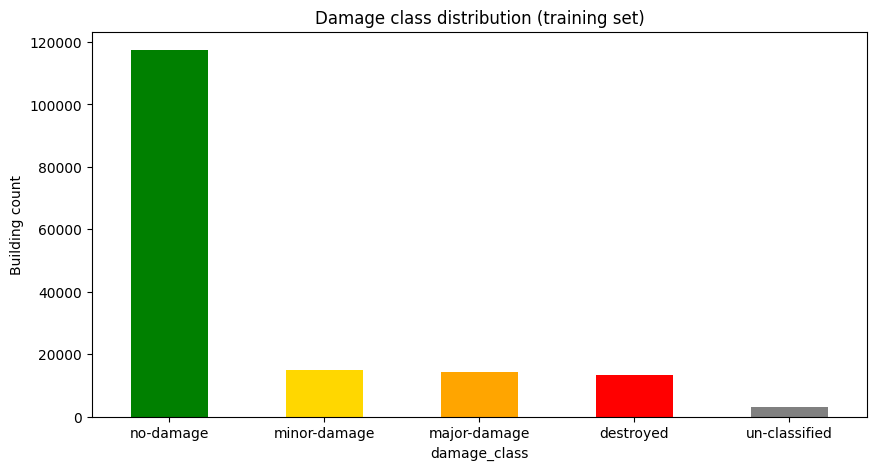

,buildings,share_%
damage_class,,
no-damage,117426,72.1
minor-damage,14980,9.2
major-damage,14161,8.7
destroyed,13227,8.1
un-classified,2993,1.8


In [3]:
DAMAGE_CLASSES = ["no-damage", "minor-damage", "major-damage", "destroyed"]  # ordinal order
DAMAGE_COLORS = {
    "no-damage": "green", "minor-damage": "gold",
    "major-damage": "orange", "destroyed": "red", "un-classified": "gray",
}

damage_counts = buildings_df["damage_class"].value_counts().reindex(DAMAGE_CLASSES + ["un-classified"])
damage_counts.plot(kind="bar", color=[DAMAGE_COLORS[c] for c in damage_counts.index],
                   title="Damage class distribution (training set)")
plt.ylabel("Building count")
plt.xticks(rotation=0)
plt.show()

pd.DataFrame({"buildings": damage_counts, "share_%": (100 * damage_counts / damage_counts.sum()).round(1)})

**Midpoint output 1c — buildings per disaster, split by damage class.** Disasters differ hugely in size and in how much damage they contain, so a model can look good overall while being poor on a single event. This table is also what the per-disaster carbon and cost totals in Sections 6-7 will be built on.

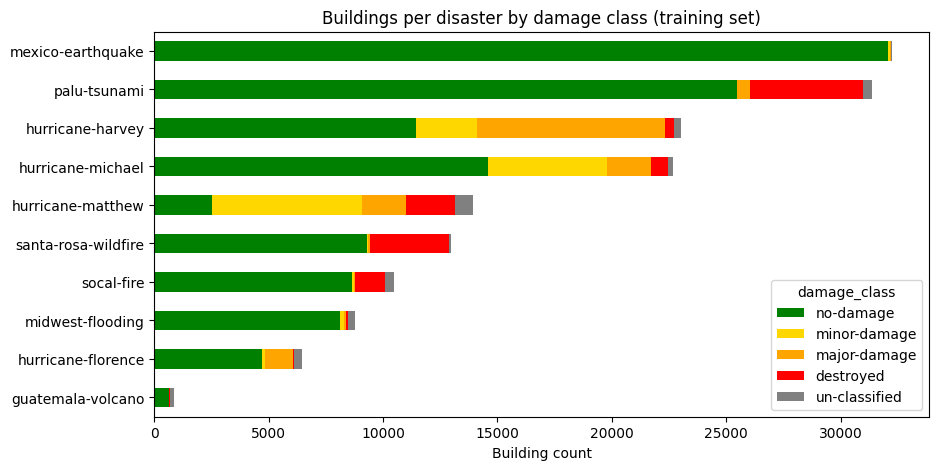

damage_class,no-damage,minor-damage,major-damage,destroyed,un-classified,total,tiles,disaster_type
disaster,,,,,,,,
mexico-earthquake,32066,110,18,2,75,32271,121,earthquake
palu-tsunami,25455,1,571,4966,401,31394,111,tsunami
hurricane-harvey,11423,2663,8238,401,289,23014,300,flooding
hurricane-michael,14588,5207,1902,757,232,22686,334,wind
hurricane-matthew,2515,6548,1945,2147,784,13939,223,wind
santa-rosa-wildfire,9285,78,63,3471,53,12950,219,fire
socal-fire,8638,83,51,1329,374,10475,408,fire
midwest-flooding,8128,149,119,75,285,8756,244,flooding
hurricane-florence,4689,132,1245,54,326,6446,306,flooding


In [4]:
per_disaster = pd.crosstab(buildings_df["disaster"], buildings_df["damage_class"])
per_disaster = per_disaster.reindex(columns=DAMAGE_CLASSES + ["un-classified"], fill_value=0)
per_disaster = per_disaster.loc[per_disaster.sum(axis=1).sort_values().index]

per_disaster.plot(kind="barh", stacked=True, color=[DAMAGE_COLORS[c] for c in per_disaster.columns],
                  title="Buildings per disaster by damage class (training set)")
plt.xlabel("Building count"); plt.ylabel("")
plt.show()

summary = per_disaster.iloc[::-1].copy()
summary["total"] = summary.sum(axis=1)
summary["tiles"] = buildings_df.groupby("disaster")["file"].nunique()
summary["disaster_type"] = buildings_df.groupby("disaster")["disaster_type"].first()
summary

**Midpoint output 1d — how big is one pixel, really?** Every downstream number (footprint → floor area → material mass → carbon/cost) depends on converting pixels to square metres, so we check it rather than assume it. Each building is stored twice in the labels: once in pixel coordinates and once in longitude/latitude. Dividing its real-world area by its pixel area gives the true metres-per-pixel of the image, which we compare with the `gsd` value in the label metadata.

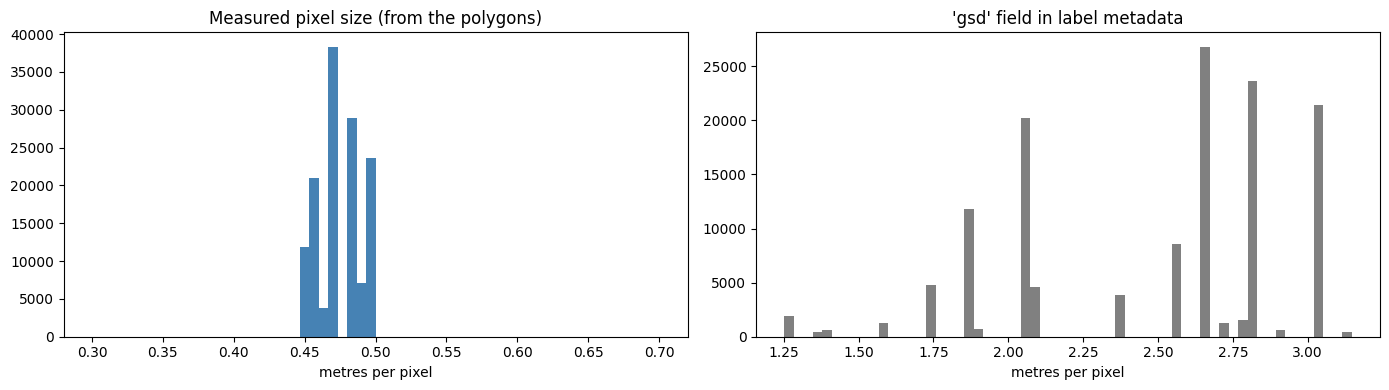

,measured_m_per_px,metadata_gsd
count,134630.000,134630.000
mean,0.475,2.482
std,0.016,0.447
min,0.448,1.252
5%,0.448,1.739
50%,0.468,2.650
95%,0.500,3.025
max,0.500,3.147


In [5]:
# Tiny polygons make the ratio noisy, so only use buildings of at least 200 pixels
big = buildings_df[buildings_df["area_px"] >= 200]
m_per_px = np.sqrt(big["footprint_m2"] / big["area_px"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(m_per_px, bins=60, range=(0.3, 0.7), color="steelblue")
axes[0].set_title("Measured pixel size (from the polygons)"); axes[0].set_xlabel("metres per pixel")
axes[1].hist(big["gsd"], bins=60, color="gray")
axes[1].set_title("'gsd' field in label metadata"); axes[1].set_xlabel("metres per pixel")
plt.tight_layout(); plt.show()

pd.DataFrame({
    "measured_m_per_px": m_per_px.describe(percentiles=[0.05, 0.5, 0.95]),
    "metadata_gsd": big["gsd"].describe(percentiles=[0.05, 0.5, 0.95]),
}).round(3)

**Midpoint output 1b — a real pre/post image pair with ground-truth building polygons overlaid.** This is a sanity check every reader can visually verify without any ML knowledge — if the polygons don't line up with real buildings, something upstream is wrong.

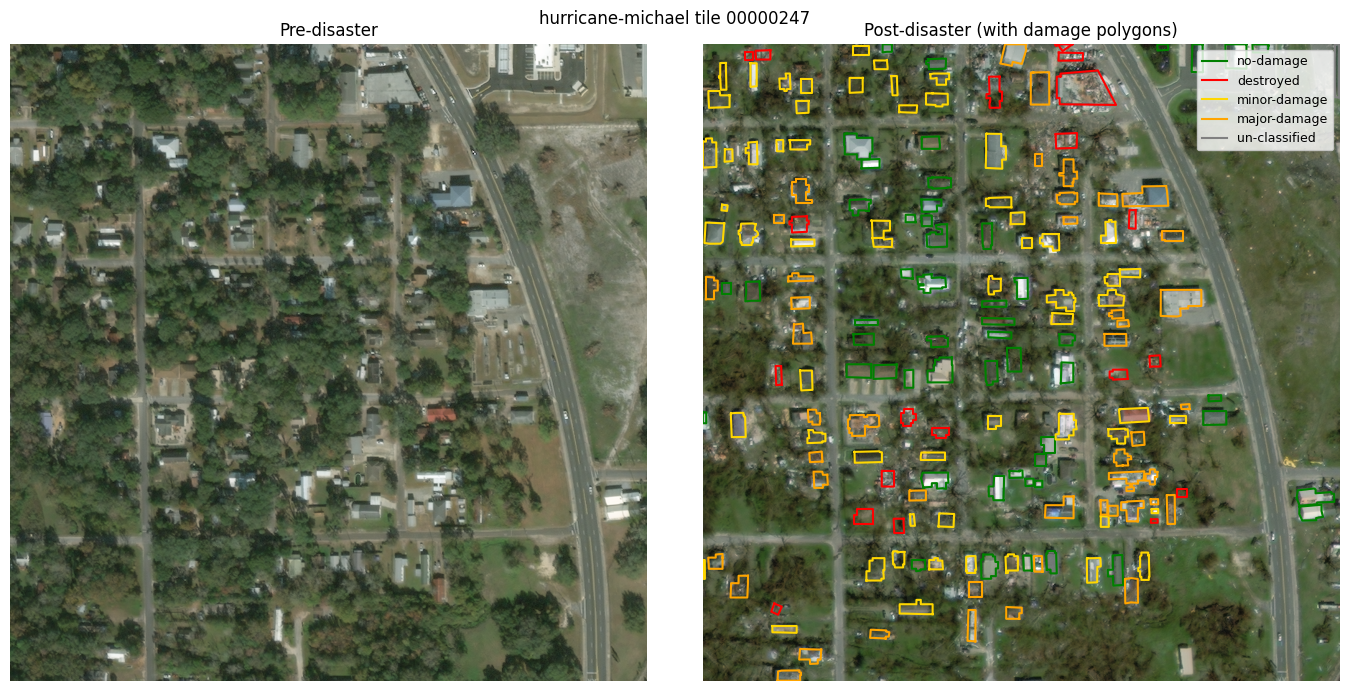

In [6]:
def show_sample_pair(disaster_name, image_id, images_dir, labels_dir):
    """Display pre/post disaster images side by side with ground-truth
    building polygons overlaid on the post-disaster image."""
    pre_img = Image.open(Path(images_dir) / f"{disaster_name}_{image_id}_pre_disaster.png")
    post_img = Image.open(Path(images_dir) / f"{disaster_name}_{image_id}_post_disaster.png")

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(pre_img)
    axes[0].set_title("Pre-disaster")
    axes[0].axis("off")

    axes[1].imshow(post_img)
    axes[1].set_title("Post-disaster (with damage polygons)")
    axes[1].axis("off")

    _, features, _ = load_label(Path(labels_dir) / f"{disaster_name}_{image_id}_post_disaster.json")
    seen = set()
    for feat in features:
        poly = wkt.loads(feat["wkt"])
        damage = feat["properties"].get("subtype", "un-classified")
        x, y = poly.exterior.xy
        # label each class once so the legend has one entry per class
        axes[1].plot(x, y, color=DAMAGE_COLORS[damage], linewidth=1.5,
                     label=damage if damage not in seen else None)
        seen.add(damage)
    axes[1].legend(loc="upper right", fontsize=9)

    plt.suptitle(f"{disaster_name} tile {image_id}")
    plt.tight_layout()
    plt.show()


# A tile chosen because it contains all four damage classes
show_sample_pair("hurricane-michael", "00000247", TRAIN_DIR / "images", TRAIN_DIR / "labels")

## 2. Stage 1 — Building Localization (Deep Learning)

**What this model does:** takes the pre-disaster image and predicts a segmentation mask of every building footprint. This uses the SpaceNet-based localization approach from the [xView2 baseline](https://github.com/DIUx-xView/xView2_baseline), which ships pretrained weights — you do not need to train this from scratch.

**Why it's kept separate from Stage 3 (classification):** this is a deliberate architectural choice from the original baseline, not just a convenience — localization only needs the *pre*-disaster image (buildings don't move). Keeping the stages separate also means you can sanity-check "did it find the buildings correctly" independently of "did it classify the damage correctly" — an important distinction if something goes wrong later, since it tells you which stage to debug.

**How the baseline is run here (and what was changed from the GitHub code):** the baseline's localization network is a U-Net written in Chainer, a deep learning framework that is no longer maintained. Rather than install it, the cell below **rebuilds the identical architecture in Keras and copies the original pretrained weights into it**. Nothing is retrained. Three things differ from the original code, none of which change the maths:

| Change | Why |
|---|---|
| Layers defined in Keras instead of Chainer | Chainer is discontinued and does not run reliably on current Python; Keras also runs on Colab |
| Weight arrays re-ordered when loaded | Chainer stores convolution kernels as (out, in, height, width); Keras expects (height, width, in, out). Same numbers, different axis order |
| Image arrays are height × width × channels | Chainer puts channels first, Keras puts them last |

The architecture: 9 convolution layers shrink the image to 1/16 of its size while growing from 32 to 512 feature channels (the *encoder*), then 9 layers grow it back to full size (the *decoder*). At each scale the decoder is also handed the encoder's output from the same scale (a *skip connection*), which is what lets a U-Net draw sharp building edges. The output is two scores per pixel: background and building.

In [7]:
# Mean RGB of the baseline's training images (weights/mean.npy in the baseline repo).
# The network was trained on images with this subtracted, so we must do the same.
LOCALIZATION_MEAN_RGB = np.array([81.01217, 89.24891, 65.47028], dtype=np.float32)
BN_EPS = 2e-5  # Chainer's default batch-norm epsilon


def build_localization_unet():
    """The xView2 baseline U-Net (spacenet/src/models/unet.py), layer for layer.
    Layer names match the names in the weight file so weights can be copied by name."""
    def down(x, name, channels, stride):
        # stride 1 = 3x3 conv keeping size; stride 2 = 4x4 conv halving size (padding 1, as in Chainer)
        if stride == 2:
            x = layers.ZeroPadding2D(1)(x)
            x = layers.Conv2D(channels, 4, strides=2, padding="valid", name=name)(x)
        else:
            x = layers.Conv2D(channels, 3, padding="same", name=name)(x)
        x = layers.BatchNormalization(epsilon=BN_EPS, name="bn" + name)(x)
        return layers.ReLU()(x)

    def up(x, name, channels, double_size):
        if double_size:
            # 4x4 transposed conv, stride 2, then trim 1 pixel per side = Chainer's Deconvolution2D(pad=1)
            x = layers.Conv2DTranspose(channels, 4, strides=2, padding="valid", name=name)(x)
            x = layers.Cropping2D(1)(x)
        else:
            x = layers.Conv2D(channels, 3, padding="same", name=name)(x)
        x = layers.BatchNormalization(epsilon=BN_EPS, name="bnd" + name[2:])(x)
        return layers.ReLU()(x)

    image = keras.Input(shape=(None, None, 3))
    # Encoder: full size -> 1/16 size
    e0 = down(image, "c0", 32, 1)
    e1 = down(e0, "c1", 64, 2);  e2 = down(e1, "c2", 64, 1)
    e3 = down(e2, "c3", 128, 2); e4 = down(e3, "c4", 128, 1)
    e5 = down(e4, "c5", 256, 2); e6 = down(e5, "c6", 256, 1)
    e7 = down(e6, "c7", 512, 2); e8 = down(e7, "c8", 512, 1)
    # Decoder: back up to full size, concatenating the encoder output at each scale (skip connections)
    d8 = up(layers.Concatenate()([e7, e8]), "dc8", 512, True)
    d7 = up(d8, "dc7", 256, False)
    d6 = up(layers.Concatenate()([e6, d7]), "dc6", 256, True)
    d5 = up(d6, "dc5", 128, False)
    d4 = up(layers.Concatenate()([e4, d5]), "dc4", 128, True)
    d3 = up(d4, "dc3", 64, False)
    d2 = up(layers.Concatenate()([e2, d3]), "dc2", 64, True)
    d1 = up(d2, "dc1", 32, False)
    scores = layers.Conv2D(2, 3, padding="same", name="dc0")(layers.Concatenate()([e0, d1]))
    return keras.Model(image, scores, name="baseline_localization_unet")


def load_chainer_weights(model, weights_path):
    """Copy the baseline's pretrained weights into the Keras model.
    Despite its .h5 name the file is a NumPy .npz archive (Chainer's save format)."""
    saved = np.load(weights_path)
    n_loaded = 0
    for layer in model.layers:
        if isinstance(layer, (layers.Conv2D, layers.Conv2DTranspose)):
            # Chainer kernel axes (a, b, height, width) -> Keras (height, width, b, a)
            layer.set_weights([saved[f"{layer.name}/W"].transpose(2, 3, 1, 0), saved[f"{layer.name}/b"]])
            n_loaded += 2
        elif isinstance(layer, layers.BatchNormalization):
            layer.set_weights([saved[f"{layer.name}/{k}"] for k in ("gamma", "beta", "avg_mean", "avg_var")])
            n_loaded += 4
    # every array in the file is used, except one bookkeeping counter ("N") per batch-norm layer
    n_in_file = sum(1 for k in saved.keys() if not k.endswith("/N"))
    assert n_loaded == n_in_file, f"loaded {n_loaded} arrays but file has {n_in_file}"
    return n_loaded


def predict_building_mask(model, image_array):
    """Run the U-Net on one RGB image and return a True/False building mask."""
    x = (image_array[..., :3].astype(np.float32) - LOCALIZATION_MEAN_RGB) / 255.0
    scores = model.predict_on_batch(x[np.newaxis])[0]
    return np.argmax(scores, axis=-1) == 1  # channel 1 = "building"


localization_model = build_localization_unet()
n_loaded = load_chainer_weights(localization_model, LOCALIZATION_WEIGHTS)
print(f"Loaded {n_loaded} pretrained weight arrays into a U-Net with {localization_model.count_params():,} parameters")

Loaded 104 pretrained weight arrays into a U-Net with 18,645,538 parameters


**Midpoint output 2 — predicted building mask overlaid on the real image, next to the ground truth.** This is the single most important sanity check in the whole notebook: if predicted masks don't roughly match real buildings, every downstream number (density, materials, carbon, cost) is built on sand.

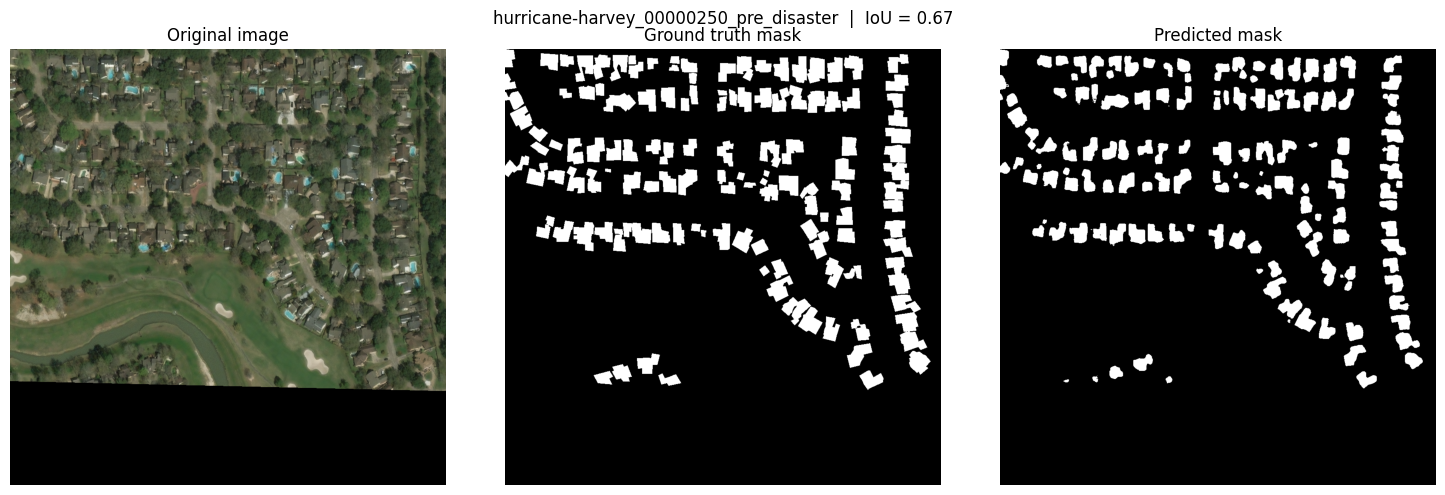

In [8]:
def compare_predicted_vs_true_mask(image, predicted_mask, true_mask, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(image); axes[0].set_title("Original image"); axes[0].axis("off")
    axes[1].imshow(true_mask, cmap="gray"); axes[1].set_title("Ground truth mask"); axes[1].axis("off")
    axes[2].imshow(predicted_mask, cmap="gray"); axes[2].set_title("Predicted mask"); axes[2].axis("off")
    plt.suptitle(title)
    plt.tight_layout(); plt.show()


def load_true_mask(pre_image_path):
    """Ground-truth building mask shipped with xBD (targets/ folder): pixel > 0 = building."""
    target_path = pre_image_path.parent.parent / "targets" / f"{pre_image_path.stem}_target.png"
    return np.array(Image.open(target_path)) > 0


def iou(pred_mask, true_mask):
    """Intersection over Union: overlap area / combined area. 1 = perfect, 0 = no overlap."""
    intersection = np.logical_and(pred_mask, true_mask).sum()
    union = np.logical_or(pred_mask, true_mask).sum()
    return intersection / union if union else 0


sample_path = TEST_DIR / "images" / "hurricane-harvey_00000250_pre_disaster.png"
sample_image = np.array(Image.open(sample_path))
sample_pred = predict_building_mask(localization_model, sample_image)
sample_true = load_true_mask(sample_path)
compare_predicted_vs_true_mask(sample_image, sample_pred, sample_true,
                               title=f"{sample_path.stem}  |  IoU = {iou(sample_pred, sample_true):.2f}")

**Midpoint output 2b — baseline localization score on the whole test split.** One picture can flatter or embarrass a model, so here every test tile is run and scored pixel by pixel against the ground-truth mask. Three numbers are reported: *precision* (of the pixels the model called building, how many really are), *recall* (of the real building pixels, how many it found), and *IoU*/*F1* which combine the two. These are the "before" figures any later localization change gets compared against.

Predicted masks are saved to `outputs/` the first time this runs (about 4 seconds per tile on a laptop CPU); re-running the cell just reloads them.

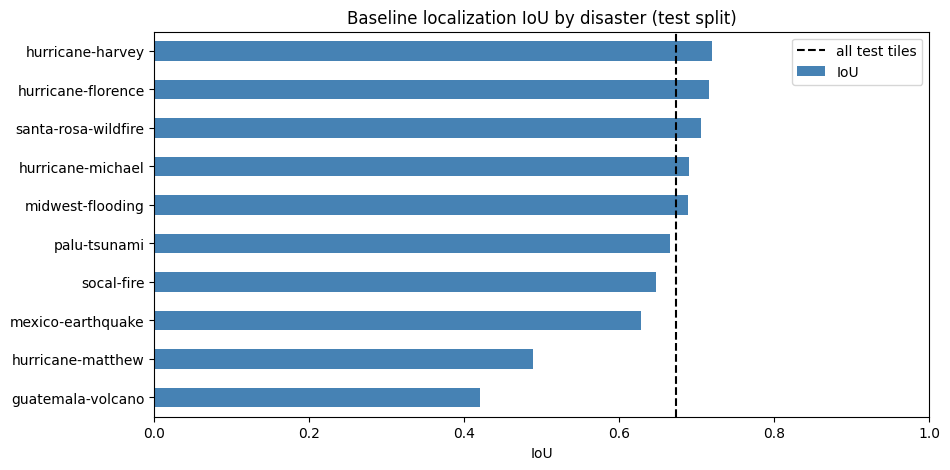

,tiles,precision,recall,IoU,F1
guatemala-volcano,5,0.631,0.557,0.420,0.592
hurricane-florence,108,0.968,0.734,0.716,0.835
hurricane-harvey,108,0.960,0.742,0.720,0.837
hurricane-matthew,73,0.896,0.518,0.489,0.657
hurricane-michael,98,0.944,0.720,0.690,0.817
mexico-earthquake,38,0.925,0.662,0.628,0.772
midwest-flooding,80,0.961,0.709,0.689,0.816
palu-tsunami,42,0.962,0.683,0.665,0.799
santa-rosa-wildfire,74,0.958,0.728,0.705,0.827
socal-fire,307,0.924,0.683,0.647,0.786


In [9]:
test_pre_images = sorted((TEST_DIR / "images").glob("*_pre_disaster.png"))[:TEST_TILE_LIMIT]
mask_cache_dir = OUTPUT_DIR / "baseline_localization_test"
mask_cache_dir.mkdir(exist_ok=True)

rows = []
for pre_path in test_pre_images:
    cache_path = mask_cache_dir / f"{pre_path.stem}_pred.png"
    if cache_path.exists():
        pred = np.array(Image.open(cache_path)) > 0
    else:
        pred = predict_building_mask(localization_model, np.array(Image.open(pre_path)))
        Image.fromarray(pred.astype(np.uint8) * 255).save(cache_path)
    true = load_true_mask(pre_path)
    rows.append({
        "tile": pre_path.stem.replace("_pre_disaster", ""),
        "disaster": pre_path.stem.split("_")[0],
        "tp": (pred & true).sum(),    # building pixels correctly found
        "fp": (pred & ~true).sum(),   # predicted building, actually background
        "fn": (~pred & true).sum(),   # real building pixels missed
    })
loc_tiles_df = pd.DataFrame(rows)


def localization_scores(df):
    """Pool pixel counts over a set of tiles, then compute the metrics once."""
    tp, fp, fn = df["tp"].sum(), df["fp"].sum(), df["fn"].sum()
    return pd.Series({
        "tiles": len(df),
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "IoU": tp / (tp + fp + fn) if tp + fp + fn else np.nan,
        "F1": 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else np.nan,
    })


baseline_loc_scores = localization_scores(loc_tiles_df)
loc_by_disaster = pd.DataFrame({d: localization_scores(g) for d, g in loc_tiles_df.groupby("disaster")}).T
loc_by_disaster.loc["ALL TEST TILES"] = baseline_loc_scores

loc_by_disaster["IoU"].iloc[:-1].sort_values().plot(kind="barh", color="steelblue",
                                                    title="Baseline localization IoU by disaster (test split)")
plt.axvline(baseline_loc_scores["IoU"], color="black", linestyle="--", label="all test tiles")
plt.xlabel("IoU"); plt.ylabel(""); plt.xlim(0, 1); plt.legend(); plt.show()

loc_by_disaster.astype({"tiles": int}).round(3)

## 3. Stage 2 — Damage Classification (Deep Learning)

**What this model does:** for each building, takes a small image crop around it and classifies damage on the ordinal scale: `no-damage → minor-damage → major-damage → destroyed`. Pretrained weights come from the baseline repo; nothing is trained in this section.

**Important detail about the baseline:** it only ever looks at the *post*-disaster crop. It never sees the pre-disaster image, so it cannot actually compare before and after. That is a real weakness, and one of the things Phase 3 can improve on.

**The architecture** has two branches that both look at the same 128×128 crop: a small 3-layer CNN, and a ResNet50 (a 50-layer network pretrained on ImageNet). Their outputs are joined and passed through four fully-connected layers down to 4 output scores, one per damage class. The highest score is the prediction.

**To isolate the classifier from Stage 1**, crops here are cut using the *ground-truth* building polygons, exactly as the baseline's own `process_data.py` does. So these scores answer "given a correctly-located building, how well is its damage classified?"

**What was changed from the GitHub code, and why:**

| Change | Why |
|---|---|
| Weights loaded layer by layer with a name translation | The weight file was saved with Keras 2.2 (2019). Current Keras names the ResNet50 layers differently (`res2a_branch2a` is now `conv2_block1_1_conv`), so its automatic loader fails. The architecture and numbers are identical |
| Crops are cut in memory instead of written to disk as ~55,000 PNG files | Same crops, far less disk use, and portable to Colab |
| Blue and red channels swapped before prediction | **Reproduces a baseline quirk.** The baseline saved its crops with OpenCV, which assumes blue-green-red order, so the model was trained on swapped colours. We must feed it what it was trained on |
| Pixel values multiplied by 1.4 | **Reproduces a baseline quirk.** The training script scaled pixels by 1/255 but the published inference script uses ×1.4. Tried on a sample of 2,532 test buildings, the "correct-looking" 1/255 makes the model predict *no-damage* for every single building, so ×1.4 is what the published baseline actually relies on |
| `un-classified` buildings excluded from scoring | They have no true label to compare against (the official xView2 scoring ignores them too) |

In [10]:
CROP_SIZE = 128        # the classifier's input size
CROP_MARGIN = 0.8      # baseline grows each building's bounding box by 80% per side for context


def build_baseline_classifier():
    """The xView2 baseline damage classifier (model/model.py), layer for layer.
    Returns the full model and its ResNet50 branch (needed separately for weight loading)."""
    crop = keras.Input(shape=(CROP_SIZE, CROP_SIZE, 3))

    # Branch 1: small CNN
    x = layers.Conv2D(32, 5, padding="same", activation="relu", name="conv2d_1")(crop)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2d_2")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2d_3")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)

    # Branch 2: ResNet50 (weights=None because we load the baseline's own copy below)
    resnet = keras.applications.ResNet50(include_top=False, weights=None, input_shape=(CROP_SIZE, CROP_SIZE, 3))
    r = layers.Flatten()(resnet(crop))

    # Join the branches, then fully-connected layers down to 4 class scores
    h = layers.Concatenate()([x, r])
    h = layers.Dense(2024, activation="relu", name="dense_1")(h)
    h = layers.Dense(524, activation="relu", name="dense_2")(h)
    h = layers.Dense(124, activation="relu", name="dense_3")(h)
    scores = layers.Dense(4, activation="relu", name="dense_4")(h)  # baseline uses ReLU here, not softmax
    return keras.Model(crop, scores, name="baseline_damage_classifier"), resnet


def keras2_resnet_name(name):
    """Translate a current Keras ResNet50 layer name to the name the same layer
    had in Keras 2.2, e.g. conv2_block1_1_conv -> res2a_branch2a."""
    if name == "conv1_conv": return "conv1"
    if name == "conv1_bn": return "bn_conv1"
    stage, block, branch, kind = re.match(r"conv(\d)_block(\d)_(\d)_(conv|bn)", name).groups()
    branch = "1" if branch == "0" else "2" + "abc"[int(branch) - 1]   # 0 = shortcut path
    return ("res" if kind == "conv" else "bn") + stage + "abcdef"[int(block) - 1] + "_branch" + branch


def load_baseline_classifier_weights(model, resnet, weights_path):
    """Copy every pretrained weight array from the baseline's file into the model."""
    n_loaded = 0
    with h5py.File(weights_path, "r") as saved:
        # Our own named layers: stored under the same name
        for layer in model.layers:
            if layer is not resnet and layer.weights:
                names = [n.decode() for n in saved[layer.name].attrs["weight_names"]]
                layer.set_weights([saved[layer.name][n][()] for n in names])
                n_loaded += len(names)
        # ResNet50 layers: stored under their Keras 2.2 names
        for layer in resnet.layers:
            if layer.weights:
                is_bn = isinstance(layer, layers.BatchNormalization)
                parts = ["gamma", "beta", "moving_mean", "moving_variance"] if is_bn else ["kernel", "bias"]
                old = keras2_resnet_name(layer.name)
                layer.set_weights([saved["resnet50"][f"{old}/{p}:0"][()] for p in parts])
                n_loaded += len(parts)
        n_in_file = sum(len(saved[k].attrs["weight_names"]) for k in saved)
    assert n_loaded == n_in_file == len(model.weights), (n_loaded, n_in_file, len(model.weights))
    return n_loaded


def crop_building(image_array, polygon_wkt, margin=CROP_MARGIN, size=CROP_SIZE, resample=Image.NEAREST):
    """Cut out one building: its bounding box, grown by `margin` on each side, clipped
    to the image, resized to `size` (defaults reproduce process_img in the baseline).
    Returns None if the box is empty."""
    height, width = image_array.shape[:2]
    xs, ys = wkt.loads(polygon_wkt).exterior.xy
    xdiff, ydiff = max(xs) - min(xs), max(ys) - min(ys)
    xmin, xmax = max(int(min(xs) - xdiff * margin), 0), min(int(max(xs) + xdiff * margin), width)
    ymin, ymax = max(int(min(ys) - ydiff * margin), 0), min(int(max(ys) + ydiff * margin), height)
    if xmax <= xmin or ymax <= ymin:
        return None
    crop = Image.fromarray(image_array[ymin:ymax, xmin:xmax, :3])
    return np.array(crop.resize((size, size), resample))


def baseline_preprocess(crops):
    """The two baseline quirks from the table above: red/blue swapped, pixels x1.4."""
    return crops[..., ::-1].astype(np.float32) * 1.4


baseline_classifier, _resnet = build_baseline_classifier()
n_loaded = load_baseline_classifier_weights(baseline_classifier, _resnet, CLASSIFICATION_WEIGHTS)
print(f"Loaded {n_loaded} pretrained weight arrays into a classifier with {baseline_classifier.count_params():,} parameters")

Loaded 332 pretrained weight arrays into a classifier with 124,257,940 parameters


In [11]:
def predict_damage_for_tiles(model, post_label_paths, preprocess):
    """Classify every labelled building in the given post-disaster tiles.
    Works one tile at a time so memory use stays small. Returns one row per building."""
    rows = []
    for label_path in post_label_paths:
        _, features, _ = load_label(label_path)
        features = [f for f in features if f["properties"].get("subtype") in DAMAGE_CLASSES]
        if not features:
            continue
        image = np.array(Image.open(label_path.parent.parent / "images" / f"{label_path.stem}.png"))
        crops = [crop_building(image, f["wkt"]) for f in features]
        kept = [(f, c) for f, c in zip(features, crops) if c is not None]
        scores = model.predict(preprocess(np.stack([c for _, c in kept])), batch_size=64, verbose=0)
        for (f, _), s in zip(kept, scores):
            rows.append({
                "file": label_path.stem,
                "uid": f["properties"]["uid"],
                "disaster": label_path.stem.split("_")[0],
                "wkt": f["wkt"],
                "true_class": f["properties"]["subtype"],
                "pred_class": DAMAGE_CLASSES[int(np.argmax(s))],
            })
    return pd.DataFrame(rows)


test_post_labels = sorted((TEST_DIR / "labels").glob("*_post_disaster.json"))[:TEST_TILE_LIMIT]
cls_cache_path = OUTPUT_DIR / f"baseline_classification_test_{len(test_post_labels)}tiles.csv"

if cls_cache_path.exists():
    baseline_cls_df = pd.read_csv(cls_cache_path)
else:
    baseline_cls_df = predict_damage_for_tiles(baseline_classifier, test_post_labels, baseline_preprocess)
    baseline_cls_df.to_csv(cls_cache_path, index=False)

print(f"{len(baseline_cls_df):,} test buildings classified across {baseline_cls_df['file'].nunique():,} tiles")
pd.DataFrame({
    "true": baseline_cls_df["true_class"].value_counts().reindex(DAMAGE_CLASSES),
    "predicted": baseline_cls_df["pred_class"].value_counts().reindex(DAMAGE_CLASSES, fill_value=0),
})

53,850 test buildings classified across 739 tiles


,true,predicted
no-damage,41427,35365
minor-damage,4798,4680
major-damage,3850,147
destroyed,3775,13658


**Midpoint output 3a — confusion matrix and baseline scores.** Because this is an *ordinal* scale (not just multi-class), it's worth checking not just overall accuracy but whether errors are "close" (e.g. major-damage misclassified as destroyed) or "far" (no-damage misclassified as destroyed) — the second is a much more serious error for our downstream carbon/cost estimates, since it would trigger an unnecessary full rebuild estimate.

How to read the scores below:
- **F1 per class** — combines precision and recall for that class; 1 is perfect, 0 means the class is never correctly predicted.
- **Macro F1** — the plain average of the four class F1s, so rare classes count as much as common ones. (Accuracy alone is misleading here: always answering "no-damage" would already score highly.)
- **xView2 F1** — the harmonic mean of the four class F1s, which is how the official challenge scored damage. It is dragged down hard by the weakest class.
- **Quadratic weighted kappa** — agreement between prediction and truth where being wrong by 3 classes is penalised 9× more than being wrong by 1. 0 = no better than chance, 1 = perfect.
- **Mean class error** — on average, how many steps along the damage scale the prediction is from the truth.

These are the "before" numbers every Phase 3 model is compared against.

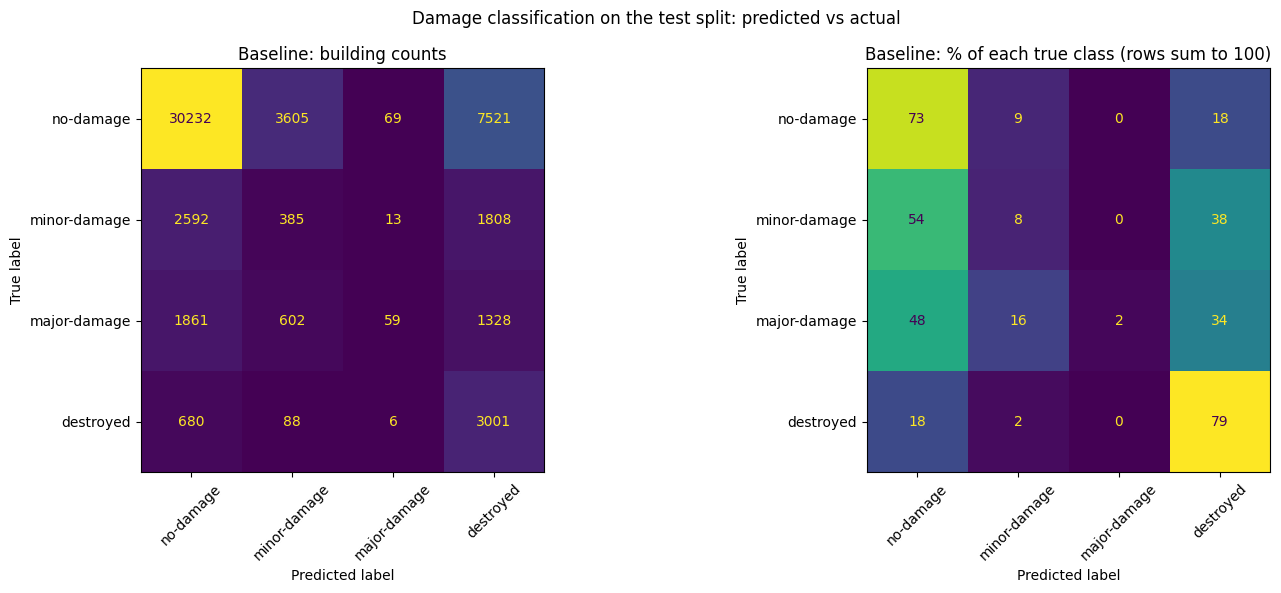

,baseline (pretrained)
F1 no-damage,0.787
F1 minor-damage,0.081
F1 major-damage,0.030
F1 destroyed,0.344
macro F1,0.311
xView2 F1 (harmonic mean),0.079
accuracy,0.625
quadratic weighted kappa,0.314
mean class error,0.750
far errors (off by 2+ classes) %,22.334


In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score, cohen_kappa_score


def damage_scores(y_true, y_pred):
    """All classification metrics for one model, as a Series (so models can be put side by side later)."""
    per_class = f1_score(y_true, y_pred, labels=DAMAGE_CLASSES, average=None, zero_division=0)
    true_idx = pd.Series(y_true).map(DAMAGE_CLASSES.index).to_numpy()
    pred_idx = pd.Series(y_pred).map(DAMAGE_CLASSES.index).to_numpy()
    scores = {f"F1 {c}": f for c, f in zip(DAMAGE_CLASSES, per_class)}
    scores["macro F1"] = per_class.mean()
    scores["xView2 F1 (harmonic mean)"] = len(per_class) / np.sum(1 / np.maximum(per_class, 1e-6))
    scores["accuracy"] = (true_idx == pred_idx).mean()
    scores["quadratic weighted kappa"] = cohen_kappa_score(true_idx, pred_idx, weights="quadratic")
    scores["mean class error"] = np.abs(true_idx - pred_idx).mean()
    scores["far errors (off by 2+ classes) %"] = 100 * (np.abs(true_idx - pred_idx) >= 2).mean()
    return pd.Series(scores)


y_true, y_pred = baseline_cls_df["true_class"], baseline_cls_df["pred_class"]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cm = confusion_matrix(y_true, y_pred, labels=DAMAGE_CLASSES)
ConfusionMatrixDisplay(cm, display_labels=DAMAGE_CLASSES).plot(ax=axes[0], xticks_rotation=45, colorbar=False, values_format="d")
axes[0].set_title("Baseline: building counts")
cm_pct = confusion_matrix(y_true, y_pred, labels=DAMAGE_CLASSES, normalize="true") * 100
ConfusionMatrixDisplay(cm_pct, display_labels=DAMAGE_CLASSES).plot(ax=axes[1], xticks_rotation=45, colorbar=False, values_format=".0f")
axes[1].set_title("Baseline: % of each true class (rows sum to 100)")
plt.suptitle("Damage classification on the test split: predicted vs actual")
plt.tight_layout(); plt.show()

# results_table collects one column per model; Phase 3 models get added to it
results_table = pd.DataFrame({"baseline (pretrained)": damage_scores(y_true, y_pred)})
results_table.round(3)

**Midpoint output 3b — example predictions shown as image pairs with predicted vs true label.** Numbers alone (accuracy, F1) don't tell a non-technical stakeholder *why* a mistake happened; showing a handful of actual misclassified examples does.

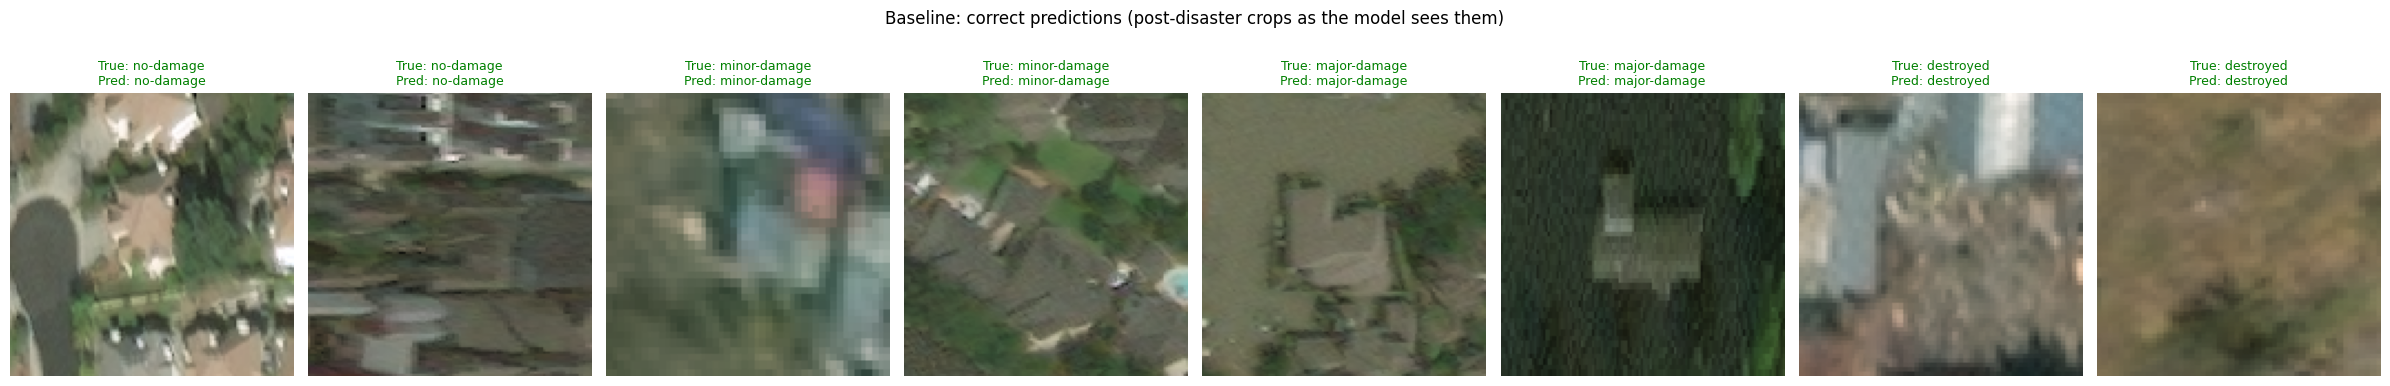

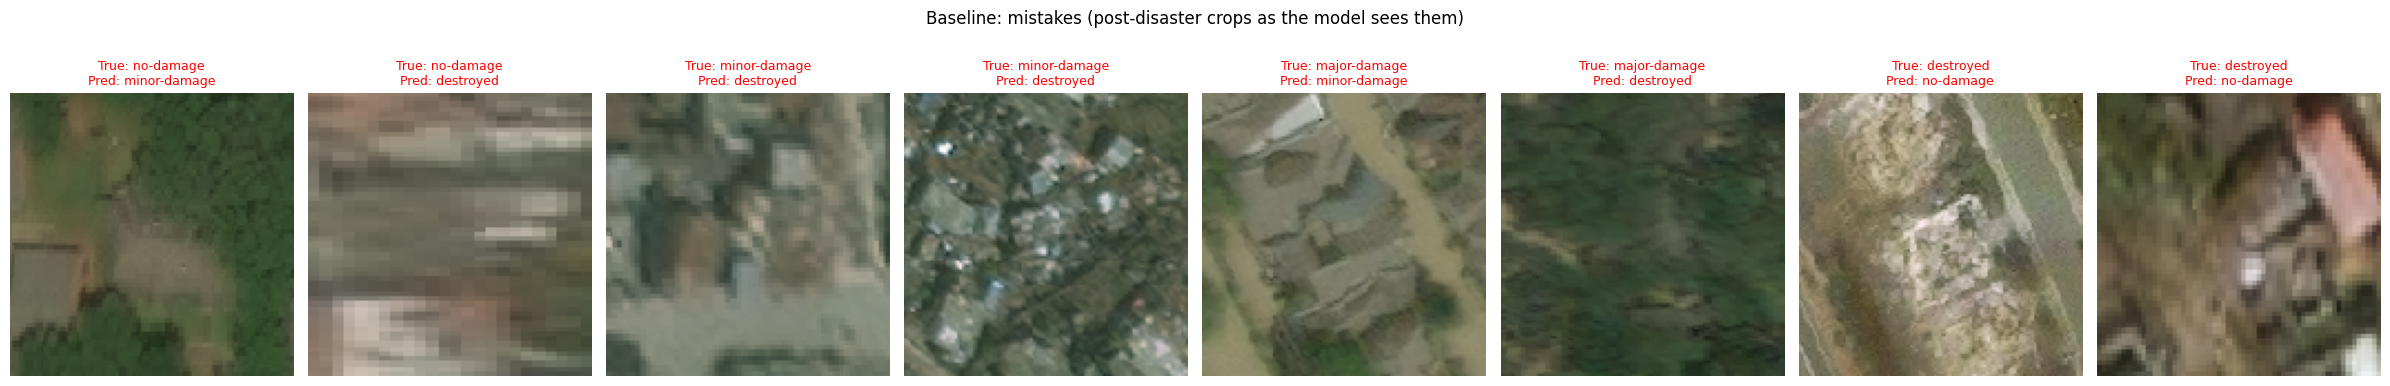

In [13]:
def show_example_predictions(building_crops, y_true, y_pred, title=""):
    n = len(building_crops)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3.6))
    for i in range(n):
        axes[i].imshow(building_crops[i])
        correct = y_true[i] == y_pred[i]
        color = "green" if correct else "red"
        axes[i].set_title(f"True: {y_true[i]}\nPred: {y_pred[i]}", color=color, fontsize=9)
        axes[i].axis("off")
    plt.suptitle(title, y=1.08)
    plt.tight_layout(); plt.show()


def crops_for_rows(rows_df, images_dir):
    """Re-cut the crops for a few rows of a predictions table (crops themselves are not cached)."""
    return [crop_building(np.array(Image.open(Path(images_dir) / f"{r.file}.png")), r.wkt)
            for r in rows_df.itertuples()]


is_correct = baseline_cls_df["true_class"] == baseline_cls_df["pred_class"]
for label, subset in [("Correct predictions", baseline_cls_df[is_correct]),
                      ("Mistakes", baseline_cls_df[~is_correct])]:
    # two random examples per true class (where available), so all four classes are shown
    by_class = [subset[subset["true_class"] == c] for c in DAMAGE_CLASSES]
    picks = pd.concat([g.sample(min(len(g), 2), random_state=1) for g in by_class if len(g)])
    show_example_predictions(crops_for_rows(picks, TEST_DIR / "images"),
                             picks["true_class"].tolist(), picks["pred_class"].tolist(),
                             title=f"Baseline: {label.lower()} (post-disaster crops as the model sees them)")

## 3b. Improving the Damage Classifier (Phase 3) — data preparation

**Everything from here to Section 4 is this project's own deep learning work**, compared at every step against the baseline scores in the `results_table` above.

**The first change is to what the model is shown.** The baseline only sees the post-disaster crop. Here every building gets a **pair**: the same crop cut from the pre-disaster image and from the post-disaster image, stacked into one 6-channel input (3 colour channels before + 3 after). Damage is a *change*, so the model should be able to see the change.

**Other choices, and why:**

| Choice | Value | Why |
|---|---|---|
| Crop size | 64 × 64 pixels | A typical building is 20–40 pixels wide, so with its surrounding margin it fits in 64 px with little loss. It is 4× cheaper than the baseline's 128 px, which makes training on a laptop or free Colab practical. One setting (`P3_CROP_SIZE`) changes it |
| Margin around each building | 80% of its size per side | Same as the baseline, so the comparison is about the model, not the crop |
| Colour handling | True colours, bilinear resizing | The baseline's swapped channels and ×1.4 scaling were quirks, not design choices |
| Validation set | 10% of *training tiles* held back | Used to decide when to stop training. The split is by tile, never by building, so neighbouring buildings from one image cannot sit on both sides. The **test split is only used for the final comparison** against the baseline |
| `un-classified` buildings | Left out | No label to learn from |

**Two pools of training data.** The `train` split (10 disasters) is used for the first set of experiments. The `tier3` split adds nine *different* disasters and nearly doubles the number of training buildings; experiments marked `train+tier3` use both. Validation tiles always come from `train`, and the test split is the same throughout, so every experiment is scored on identical buildings.

Crops are cut once and saved in `outputs/` (3.9 GB for train, 3.6 GB for tier3, 1.3 GB for test). Those files are also what gets uploaded to Colab for the longer training runs.

In [14]:
P3_CROP_SIZE = 64          # pixels; input to the Phase 3 models
VALIDATION_FRACTION = 0.10  # share of training TILES held back for validation


def build_crop_cache(buildings, images_dir, name):
    """Cut a (pre, post) crop pair for every labelled building and cache them.
    Returns (meta, crops): meta has one row per building; crops is an array of shape
    (n_buildings, size, size, 6) = pre RGB + post RGB, read from disk on demand."""
    meta_path = OUTPUT_DIR / f"crops_{name}_{P3_CROP_SIZE}px_meta.csv"
    data_path = OUTPUT_DIR / f"crops_{name}_{P3_CROP_SIZE}px.npy"
    if not (meta_path.exists() and data_path.exists()):
        meta = buildings[buildings["damage_class"].isin(DAMAGE_CLASSES)].reset_index(drop=True)
        meta = meta[["file", "uid", "disaster", "damage_class", "footprint_m2", "wkt"]].copy()
        meta["label"] = meta["damage_class"].map(DAMAGE_CLASSES.index)
        meta["has_crop"] = True
        tmp_path = data_path.with_suffix(".partial.npy")   # renamed at the end, so a half-finished file is never used
        crops = np.lib.format.open_memmap(tmp_path, mode="w+", dtype=np.uint8,
                                          shape=(len(meta), P3_CROP_SIZE, P3_CROP_SIZE, 6))
        for file, group in meta.groupby("file", sort=False):
            post = np.array(Image.open(Path(images_dir) / f"{file}.png"))
            pre = np.array(Image.open(Path(images_dir) / f"{file.replace('_post_', '_pre_')}.png"))
            for i, polygon in zip(group.index, group["wkt"]):
                pre_crop = crop_building(pre, polygon, size=P3_CROP_SIZE, resample=Image.BILINEAR)
                post_crop = crop_building(post, polygon, size=P3_CROP_SIZE, resample=Image.BILINEAR)
                if pre_crop is None:
                    meta.loc[i, "has_crop"] = False   # empty box (polygon on the tile edge)
                else:
                    crops[i] = np.concatenate([pre_crop, post_crop], axis=-1)
        crops.flush(); del crops
        tmp_path.rename(data_path)
        meta.drop(columns="wkt").to_csv(meta_path, index=False)
    return pd.read_csv(meta_path), np.load(data_path, mmap_mode="r")


test_buildings_df = build_metadata_table(TEST_DIR / "labels")
train_meta, train_crops = build_crop_cache(buildings_df, TRAIN_DIR / "images", "train")
test_meta, test_crops = build_crop_cache(test_buildings_df, TEST_DIR / "images", "test")
tier3_buildings_df = build_metadata_table(TIER3_DIR / "labels")
tier3_meta, tier3_crops = build_crop_cache(tier3_buildings_df, TIER3_DIR / "images", "tier3")

# Train / validation split BY TILE (fixed seed, so it is the same every run)
tiles = np.sort(train_meta["file"].unique())
rng = np.random.default_rng(0)
val_tiles = set(rng.choice(tiles, size=int(len(tiles) * VALIDATION_FRACTION), replace=False))
train_meta["subset"] = np.where(train_meta["file"].isin(val_tiles), "validation", "train")
test_meta["subset"] = "test"
tier3_meta["subset"] = "tier3"   # all of tier3 is training data; validation stays inside the train split

all_meta = pd.concat([train_meta, tier3_meta, test_meta])
split_counts = all_meta.pivot_table(
    index="subset", columns="damage_class", values="uid", aggfunc="count")[DAMAGE_CLASSES].loc[["train", "tier3", "validation", "test"]]
split_counts["total"] = split_counts.sum(axis=1)
split_counts["tiles"] = all_meta.groupby("subset")["file"].nunique()
split_counts["disasters"] = all_meta.groupby("subset")["disaster"].nunique()
print(f"Crop arrays: train {train_crops.shape}, tier3 {tier3_crops.shape}, test {test_crops.shape}")
split_counts

Crop arrays: train (159794, 64, 64, 6), tier3 (144576, 64, 64, 6), test (53850, 64, 64, 6)


damage_class,no-damage,minor-damage,major-damage,destroyed,total,tiles,disasters
subset,,,,,,,
train,107427,13678,13287,12003,146395,2017,10
tier3,116209,10744,7288,10335,144576,3253,9
validation,9999,1302,874,1224,13399,224,10
test,41427,4798,3850,3775,53850,739,10


**Midpoint output 3c — what the new model is shown.** Each pair is the same building before (left) and after (right). Four random training examples per damage class. If the pairs do not line up, or the "destroyed" row does not look worse than the "no-damage" row, something is wrong with the data before any model is involved.

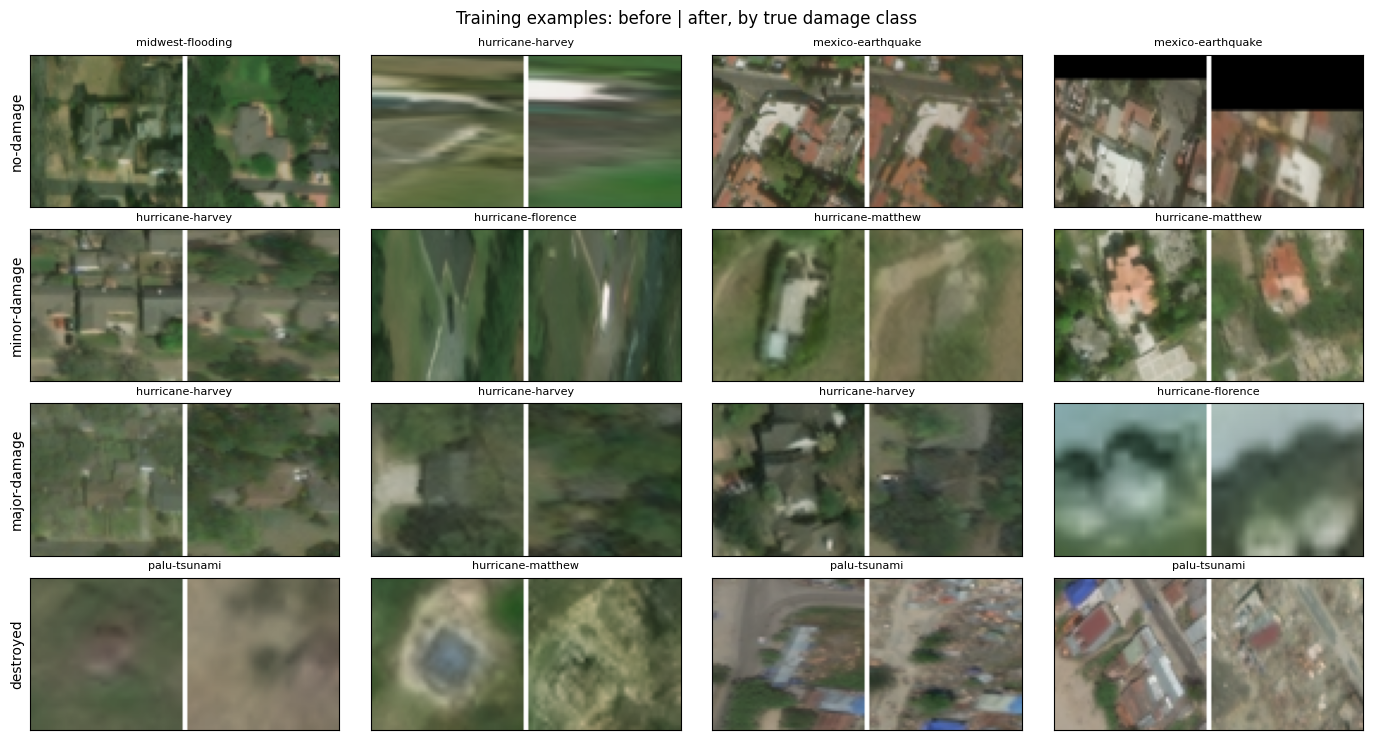

In [15]:
fig, axes = plt.subplots(len(DAMAGE_CLASSES), 4, figsize=(14, 7.5))
for row, damage in enumerate(DAMAGE_CLASSES):
    candidates = train_meta[(train_meta["damage_class"] == damage) & train_meta["has_crop"] & (train_meta["subset"] == "train")]
    for col, i in enumerate(candidates.sample(4, random_state=7).index):
        pair = np.asarray(train_crops[i])
        side_by_side = np.concatenate([pair[..., :3], np.full((P3_CROP_SIZE, 2, 3), 255, np.uint8), pair[..., 3:]], axis=1)
        axes[row, col].imshow(side_by_side)
        axes[row, col].set_title(f"{train_meta.loc[i, 'disaster']}", fontsize=8)
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(damage, fontsize=10)
plt.suptitle("Training examples: before | after, by true damage class")
plt.tight_layout(); plt.show()

## 3c. Improving the Damage Classifier (Phase 3) — model, losses and experiments

**The model (built from scratch, no pretrained weights).** A *Siamese* network: one small CNN encoder is applied twice with the **same weights**, once to the before-crop and once to the after-crop. That gives two feature vectors describing the building at each time. The classifier head is then handed three things: the "before" features, the "after" features, and their **difference** — so "what changed" is given to it directly rather than something it has to discover.

- **Encoder:** 4 blocks, each two 3×3 convolutions (with batch normalisation and ReLU) followed by 2× down-sampling; channels grow 16 → 32 → 64 → 128; the result is averaged over the image to a 128-number vector.
- **Head:** one 128-unit layer with dropout, then the output layer.
- **Size:** about 0.35 million parameters, against 124 million in the baseline.

**The experiments.** Each row changes one thing, so its effect can be read off the results table. All use the same model, data, training budget and random seed.

| Experiment | Loss | Class weights | What it tests |
|---|---|---|---|
| `cnn_ce` | Cross-entropy | no | The effect of the new before+after input and model alone |
| `cnn_weighted` | Cross-entropy | yes | **Class imbalance:** each building is weighted inversely to how common its class is, so the 73% of undamaged buildings cannot dominate |
| `cnn_focal` | Focal loss (γ = 2) | yes | **Class imbalance, second approach:** focal loss shrinks the contribution of examples the model already gets right, concentrating training on hard ones |
| `cnn_ordinal` | Ordinal (CORAL) | yes | **Damage is ordered.** Instead of 4 unrelated classes, the model learns one "damage score" and three thresholds along it (is it at least minor? at least major? destroyed?). Being wrong by three steps then costs more than being wrong by one, which matters because "undamaged → destroyed" errors are what inflate the carbon estimate |

**Sets 1 and 2 are the same four experiments on different data.** Set 1 trains on the `train` split only with a small budget (10 epochs of 40,000 buildings), which a laptop can manage. Set 2 (names ending `+tier3`) trains on `train` and `tier3` together with a larger budget (20 epochs of 150,000 buildings) on a Colab GPU. Comparing within a set shows the effect of the loss; comparing the same loss across sets shows the effect of more data and longer training.

**Set 3 answers three questions left open by Set 2**, where the validation score swung by up to 0.14 from one epoch to the next and each recipe had been run only once:

| Question | What Set 3 changes | How to read it |
|---|---|---|
| Is the noisy training hiding the real differences? | **Cosine learning-rate schedule:** the step size starts at the same value and shrinks smoothly to zero, so late epochs make small careful adjustments instead of large jumps | Compare `..._cosine` with the same name in Set 2 |
| Are the differences between losses real or luck? | **A second random seed** for the two best recipes (plain cross-entropy and focal) | If two seeds of one recipe differ by more than two recipes differ from each other, the ranking is not reliable |
| Does a pretrained encoder help? | **EfficientNetB0 pretrained on ImageNet** replaces the small from-scratch encoder (4 million parameters instead of 0.3 million, already able to recognise edges, textures and shapes). It uses a lower starting learning rate (0.0003) so the pretrained weights are adjusted gently | Compare `effnet_...` with `cnn_..._cosine` |

The pretrained weights are downloaded by Keras from `https://storage.googleapis.com/keras-applications/` (file `efficientnetb0_notop.h5`; model from Tan & Le, 2019, *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks*; distributed with Keras Applications under the Apache 2.0 licence).

**Training setup:** Adam optimiser, learning rate 0.001 unless the table says otherwise, batches of 128, random flips and 90° rotations as augmentation (applied identically to the before and after crops). After every epoch the model is scored on the validation tiles, and the weights from the epoch with the best validation macro F1 are the ones kept. The test split is touched once per experiment, at the end.

Trained weights, training history and test predictions are cached in `outputs/`, so this section only trains what is missing. Set `P3_TRAIN = False` to skip training entirely and just show cached results. The Colab runs use `colab_train.ipynb`, which is generated from these exact cells (same model, losses and training loop); its result files are downloaded into `outputs/` and picked up here.

In [16]:
P3_TRAIN = False                 # True = train any experiment with no cached result (Set 2 needs a GPU)
P3_BATCH_SIZE = 128
P3_WIDTH = 16                    # channels in the first encoder block
N_CLASSES = len(DAMAGE_CLASSES)

# One row per experiment.
#   train_on          which crop pools it learns from
#   samples_per_epoch random training buildings drawn each epoch (a fresh draw every epoch)
#   lr / lr_schedule  starting learning rate; "constant" keeps it, "cosine" lowers it smoothly to zero
#   seed              random seed (same seed = same starting weights and same sampling order)
#   encoder           "scratch" = the small CNN below; "efficientnet" = ImageNet-pretrained EfficientNetB0
P3_EXPERIMENTS = pd.DataFrame([
    # Set 1: train split only, small budget (laptop CPU, about an hour each)
    ("cnn_ce",                        "ce",    False, "train",       10,  40_000, 1e-3, "constant", 0, "scratch"),
    ("cnn_weighted",                  "ce",    True,  "train",       10,  40_000, 1e-3, "constant", 0, "scratch"),
    ("cnn_focal",                     "focal", True,  "train",       10,  40_000, 1e-3, "constant", 0, "scratch"),
    ("cnn_ordinal",                   "coral", True,  "train",       10,  40_000, 1e-3, "constant", 0, "scratch"),
    # Set 2: train + tier3, larger budget (Colab GPU)
    ("cnn_ce+tier3",                  "ce",    False, "train+tier3", 20, 150_000, 1e-3, "constant", 0, "scratch"),
    ("cnn_weighted+tier3",            "ce",    True,  "train+tier3", 20, 150_000, 1e-3, "constant", 0, "scratch"),
    ("cnn_focal+tier3",               "focal", True,  "train+tier3", 20, 150_000, 1e-3, "constant", 0, "scratch"),
    ("cnn_ordinal+tier3",             "coral", True,  "train+tier3", 20, 150_000, 1e-3, "constant", 0, "scratch"),
    # Set 3: the two best Set 2 recipes with a cosine learning-rate schedule, each with two seeds,
    # plus a pretrained encoder (Colab GPU)
    ("cnn_ce+tier3_cosine",           "ce",    False, "train+tier3", 20, 150_000, 1e-3, "cosine",   0, "scratch"),
    ("cnn_ce+tier3_cosine_seed1",     "ce",    False, "train+tier3", 20, 150_000, 1e-3, "cosine",   1, "scratch"),
    ("cnn_focal+tier3_cosine",        "focal", True,  "train+tier3", 20, 150_000, 1e-3, "cosine",   0, "scratch"),
    ("cnn_focal+tier3_cosine_seed1",  "focal", True,  "train+tier3", 20, 150_000, 1e-3, "cosine",   1, "scratch"),
    ("effnet_ce+tier3_cosine",        "ce",    False, "train+tier3", 20, 150_000, 3e-4, "cosine",   0, "efficientnet"),
    ("effnet_focal+tier3_cosine",     "focal", True,  "train+tier3", 20, 150_000, 3e-4, "cosine",   0, "efficientnet"),
], columns=["name", "loss", "class_weights", "train_on", "epochs", "samples_per_epoch", "lr", "lr_schedule", "seed", "encoder"])


# ----------------------------------------------------------------- the model
def build_encoder(norm="batch"):
    """Small CNN: 64x64x3 crop -> 128-number description of it.
    norm="batch" (Phase 3) normalises each layer using statistics of the whole batch;
    norm="group" (Layer 2) normalises each image on its own, see Section 4b for why."""
    x = crop = keras.Input((P3_CROP_SIZE, P3_CROP_SIZE, 3))
    for channels in [P3_WIDTH, P3_WIDTH * 2, P3_WIDTH * 4, P3_WIDTH * 8]:
        for _ in range(2):
            x = layers.Conv2D(channels, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x) if norm == "batch" else layers.GroupNormalization(groups=8)(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D()(x)
    return keras.Model(crop, layers.GlobalAveragePooling2D()(x), name="encoder")


class OrdinalThresholds(layers.Layer):
    """CORAL output: takes ONE damage score and adds a separate learned offset for each
    of the 3 thresholds (>= minor, >= major, destroyed). Output > 0 means 'past that threshold'."""
    def build(self, input_shape):
        self.offsets = self.add_weight(shape=(N_CLASSES - 1,), initializer="zeros", name="offsets")
    def call(self, score):
        return score + self.offsets


def build_pretrained_encoder():
    """EfficientNetB0 pretrained on ImageNet, used as the encoder instead of the small CNN.
    Weights are downloaded by Keras from https://storage.googleapis.com/keras-applications/
    (efficientnetb0_notop.h5; Tan & Le 2019, 'EfficientNet', released with Keras Applications,
    Apache 2.0 licence). It expects pixel values 0-255 and does its own input scaling."""
    # (no custom name here: Keras builds the download file name from the model's own name)
    return keras.applications.EfficientNetB0(include_top=False, weights="imagenet", pooling="avg",
                                             input_shape=(P3_CROP_SIZE, P3_CROP_SIZE, 3))


def build_pair_classifier(ordinal=False, encoder="scratch"):
    pair = keras.Input((P3_CROP_SIZE, P3_CROP_SIZE, 6))          # before RGB + after RGB
    if encoder == "scratch":
        x = layers.Rescaling(1 / 255.0)(pair)
        shared = build_encoder()                                  # ONE encoder, used twice
    else:
        x = pair                                                  # EfficientNet scales its own input
        shared = build_pretrained_encoder()
    before, after = shared(x[..., :3]), shared(x[..., 3:])
    h = layers.Concatenate()([before, after, layers.Subtract()([after, before])])
    h = layers.Dense(128, activation="relu")(h)
    h = layers.Dropout(0.3)(h)
    if ordinal:
        out = OrdinalThresholds()(layers.Dense(1, use_bias=False)(h))   # 3 threshold scores
    else:
        out = layers.Dense(N_CLASSES)(h)                                 # 4 class scores
    return keras.Model(pair, out)


# ---------------------------------------------------------------- the losses
def cross_entropy(y_true, scores):
    return keras.losses.sparse_categorical_crossentropy(y_true, scores, from_logits=True)

def focal_loss(y_true, scores, gamma=2.0):
    """Cross-entropy scaled by (1 - probability given to the true class)^gamma:
    confident correct answers contribute almost nothing, mistakes contribute fully."""
    ce = cross_entropy(y_true, scores)
    return (1.0 - keras.ops.exp(-ce)) ** gamma * ce

def coral_loss(y_true, scores):
    """Three yes/no questions per building: is the true class above threshold 0, 1, 2?
    e.g. major-damage (class 2) -> [yes, yes, no]. Loss = average binary cross-entropy."""
    y = keras.ops.cast(keras.ops.reshape(y_true, (-1, 1)), "float32")
    passed = keras.ops.cast(y > keras.ops.arange(N_CLASSES - 1, dtype="float32"), "float32")
    return keras.ops.mean(keras.ops.binary_crossentropy(passed, scores, from_logits=True), axis=-1)

P3_LOSSES = {"ce": cross_entropy, "focal": focal_loss, "coral": coral_loss}

def scores_to_class(scores, ordinal):
    """Model output -> class index 0..3. Ordinal: count how many thresholds were passed."""
    return (scores > 0).sum(axis=1) if ordinal else scores.argmax(axis=1)


# ------------------------------------------------------------------ the data
class CropBatches(keras.utils.PyDataset):
    """Feeds batches of crop pairs straight from the cached file on disk."""
    def __init__(self, crops, labels, indices, sample_weights=None, samples_per_epoch=None, training=False, seed=0):
        super().__init__()
        self.crops, self.labels, self.indices = crops, labels, np.asarray(indices)
        self.sample_weights, self.training = sample_weights, training
        self.n = len(self.indices) if samples_per_epoch is None else min(int(samples_per_epoch), len(self.indices))
        self.rng = np.random.default_rng(seed)
        self.order = self.rng.permutation(self.indices) if training else self.indices

    def __len__(self):
        return int(np.ceil(self.n / P3_BATCH_SIZE))

    def __getitem__(self, i):
        idx = np.sort(self.order[i * P3_BATCH_SIZE:min((i + 1) * P3_BATCH_SIZE, self.n)])
        x = np.asarray(self.crops[idx])
        if self.training:   # augmentation: the before and after crops are flipped/rotated together
            flip = self.rng.random(len(idx)) < 0.5
            x[flip] = x[flip][:, :, ::-1]
            x = np.rot90(x, k=int(self.rng.integers(4)), axes=(1, 2))
        y = self.labels[idx]
        w = np.ones(len(idx), np.float32) if self.sample_weights is None else self.sample_weights[idx]
        return np.ascontiguousarray(x), y, w

    def on_epoch_end(self):
        if self.training:   # fresh random draw of training buildings for the next epoch
            self.order = self.rng.permutation(self.indices)


class CropStore:
    """Several cached crop files presented as one long array (nothing is copied into memory)."""
    def __init__(self, arrays):
        self.arrays = arrays
        self.starts = np.cumsum([0] + [len(a) for a in arrays])
    def __len__(self):
        return int(self.starts[-1])
    def __getitem__(self, idx):   # idx: sorted array of positions in the combined array
        parts = [a[idx[(idx >= lo) & (idx < hi)] - lo] for a, lo, hi in zip(self.arrays, self.starts[:-1], self.starts[1:])]
        return np.concatenate(parts)


# The training pool: train split followed by tier3, addressed by one index
pool_meta = pd.concat([train_meta, tier3_meta], ignore_index=True)
pool_crops = CropStore([train_crops, tier3_crops])
pool_labels = pool_meta["label"].to_numpy()
test_labels = test_meta["label"].to_numpy()
val_idx = np.flatnonzero((pool_meta["has_crop"] & (pool_meta["subset"] == "validation")).to_numpy())

def training_indices(train_on):
    """Positions in the pool that an experiment may learn from, e.g. "train" or "train+tier3"."""
    return np.flatnonzero((pool_meta["has_crop"] & pool_meta["subset"].isin(train_on.split("+"))).to_numpy())

def balanced_class_weights(indices):
    """total / (number of classes x count of that class): rare classes weigh more."""
    counts = np.bincount(pool_labels[indices], minlength=N_CLASSES)
    return len(indices) / (N_CLASSES * counts)

weights_table = {}
for train_on in P3_EXPERIMENTS["train_on"].unique():
    idx = training_indices(train_on)
    weights_table[(train_on, "training buildings")] = np.bincount(pool_labels[idx], minlength=N_CLASSES)
    weights_table[(train_on, "class weight")] = balanced_class_weights(idx).round(2)
display(pd.DataFrame(weights_table, index=DAMAGE_CLASSES))

example_model = build_pair_classifier()
print(f"Pair classifier: {example_model.count_params():,} parameters "
      f"(encoder {example_model.get_layer('encoder').count_params():,}, shared between before and after)")
P3_EXPERIMENTS

train                     train+tier3             
             training buildings class weight training buildings class weight
no-damage                107427         0.34             223636         0.33
minor-damage              13678         2.68              24422         2.98
major-damage              13287         2.75              20575         3.54
destroyed                 12003         3.05              22338         3.26

Pair classifier: 344,756 parameters (encoder 294,960, shared between before and after)


,name,loss,class_weights,train_on,epochs,samples_per_epoch,lr,lr_schedule,seed,encoder
0,cnn_ce,ce,False,train,10,40000,0.0010,constant,0,scratch
1,cnn_weighted,ce,True,train,10,40000,0.0010,constant,0,scratch
2,cnn_focal,focal,True,train,10,40000,0.0010,constant,0,scratch
3,cnn_ordinal,coral,True,train,10,40000,0.0010,constant,0,scratch
4,cnn_ce+tier3,ce,False,train+tier3,20,150000,0.0010,constant,0,scratch
5,cnn_weighted+tier3,ce,True,train+tier3,20,150000,0.0010,constant,0,scratch
6,cnn_focal+tier3,focal,True,train+tier3,20,150000,0.0010,constant,0,scratch
7,cnn_ordinal+tier3,coral,True,train+tier3,20,150000,0.0010,constant,0,scratch
8,cnn_ce+tier3_cosine,ce,False,train+tier3,20,150000,0.0010,cosine,0,scratch
9,cnn_ce+tier3_cosine_seed1,ce,False,train+tier3,20,150000,0.0010,cosine,1,scratch


In [17]:
import time

def run_experiment(exp):
    """Train one row of P3_EXPERIMENTS (or load it from cache). Returns (history, test predictions) or None."""
    tag = f"p3_{exp.name}_{exp.epochs}ep_{exp.samples_per_epoch}spe"
    weights_path = OUTPUT_DIR / f"{tag}.weights.h5"
    history_path = OUTPUT_DIR / f"{tag}_history.csv"
    preds_path = OUTPUT_DIR / f"{tag}_test_predictions.csv"
    if history_path.exists() and preds_path.exists():
        return pd.read_csv(history_path), pd.read_csv(preds_path)
    if not P3_TRAIN:
        return None

    ordinal = exp.loss == "coral"
    keras.utils.set_random_seed(exp.seed)
    model = build_pair_classifier(ordinal, exp.encoder)
    train_idx = training_indices(exp.train_on)
    weights = balanced_class_weights(train_idx)[pool_labels].astype(np.float32) if exp.class_weights else None
    train_batches = CropBatches(pool_crops, pool_labels, train_idx, weights, exp.samples_per_epoch, training=True, seed=exp.seed)
    val_batches = CropBatches(pool_crops, pool_labels, val_idx)
    if exp.lr_schedule == "cosine":   # learning rate falls smoothly from exp.lr to zero over the whole run
        learning_rate = keras.optimizers.schedules.CosineDecay(exp.lr, decay_steps=exp.epochs * len(train_batches))
    else:
        learning_rate = exp.lr
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss=P3_LOSSES[exp.loss])

    history, best_f1, start = [], -1.0, time.time()
    for epoch in range(1, exp.epochs + 1):
        fit = model.fit(train_batches, epochs=1, verbose=0)
        val_pred = scores_to_class(model.predict(val_batches, verbose=0), ordinal)
        val_f1 = f1_score(pool_labels[val_idx], val_pred, average="macro")
        history.append({"experiment": exp.name, "epoch": epoch, "train_loss": fit.history["loss"][0],
                        "val_macro_f1": val_f1, "minutes": (time.time() - start) / 60})
        if val_f1 > best_f1:                       # keep the best epoch's weights
            best_f1 = val_f1
            model.save_weights(weights_path)
    model.load_weights(weights_path)

    test_idx = np.flatnonzero(test_meta["has_crop"].to_numpy())
    test_pred = scores_to_class(model.predict(CropBatches(test_crops, test_labels, test_idx), verbose=0), ordinal)
    preds = test_meta.iloc[test_idx][["file", "uid", "disaster", "damage_class"]].rename(columns={"damage_class": "true_class"})
    preds["pred_class"] = [DAMAGE_CLASSES[i] for i in test_pred]
    history = pd.DataFrame(history)
    history.to_csv(history_path, index=False); preds.to_csv(preds_path, index=False)
    return history, preds


# model_predictions: every model's test predictions, used again in Section 7b
model_predictions = {"baseline (pretrained)": baseline_cls_df}
p3_histories = []
for exp in P3_EXPERIMENTS.itertuples(index=False):
    result = run_experiment(exp)
    if result is None:
        print(f"{exp.name}: not trained yet (no cached result and P3_TRAIN is False)")
        continue
    p3_histories.append(result[0]); model_predictions[exp.name] = result[1]
    best = result[0].loc[result[0]["val_macro_f1"].idxmax()]
    print(f"{exp.name}: best validation macro F1 {best['val_macro_f1']:.3f} at epoch {int(best['epoch'])} "
          f"({result[0]['minutes'].max():.0f} min of training)")

cnn_ce: best validation macro F1 0.595 at epoch 8 (64 min of training)


cnn_weighted: best validation macro F1 0.597 at epoch 10 (61 min of training)
cnn_focal: best validation macro F1 0.580 at epoch 9 (114 min of training)


cnn_ordinal: best validation macro F1 0.473 at epoch 5 (63 min of training)


cnn_ce+tier3: best validation macro F1 0.682 at epoch 17 (48 min of training)
cnn_weighted+tier3: best validation macro F1 0.674 at epoch 15 (51 min of training)


cnn_focal+tier3: best validation macro F1 0.660 at epoch 14 (52 min of training)


cnn_ordinal+tier3: best validation macro F1 0.574 at epoch 12 (53 min of training)


cnn_ce+tier3_cosine: best validation macro F1 0.701 at epoch 15 (25 min of training)


cnn_ce+tier3_cosine_seed1: best validation macro F1 0.693 at epoch 19 (25 min of training)
cnn_focal+tier3_cosine: best validation macro F1 0.668 at epoch 14 (25 min of training)


cnn_focal+tier3_cosine_seed1: best validation macro F1 0.662 at epoch 17 (25 min of training)


effnet_ce+tier3_cosine: best validation macro F1 0.712 at epoch 15 (43 min of training)
effnet_focal+tier3_cosine: best validation macro F1 0.666 at epoch 15 (18 min of training)


### 3c-ii. A multi-task model: one network that finds buildings *and* judges their damage (Phase 3d)

Everything so far uses **two separate models**: the baseline's U-Net marks building pixels, and a crop classifier judges each building's damage from a small 64-pixel crop. The model here replaces both with **one network that reads the whole 1024 × 1024 tile pair at full resolution** and draws two maps at once:

- a **building map** (is this pixel part of a building?), and
- a **damage map** (for building pixels, which of the four damage classes?).

**Architecture: a Siamese U-Net.**
- The **encoder** is the ImageNet-pretrained EfficientNetB0 that won Set 3 (source as in Section 3c). It reads the before and after images with the **same weights**, giving features at five scales (1/2 down to 1/32 of the image size).
- At each scale the before features, the after features and their **difference** are joined, as in the crop model.
- The **decoder** climbs back up to full size, merging in each scale's joined features (the U-Net skip connections), and ends in two outputs per pixel: 1 building score and 4 damage scores.

**Why it might do better than the crop model:** it sees buildings at full resolution instead of shrunk into 64 pixels, it sees their surroundings (debris fields, flood water, burn scars), and finding buildings and judging damage can share what they learn. The leading xView2 competition entries used this design.

**Training targets.** For each tile, a target image is drawn from the label polygons: 0 = background, 1–4 = a building of that damage class, 5 = a building with no damage label (`un-classified`: counts as a building, but is left out of the damage loss).

**The loss is three parts added together:**
1. building map: binary cross-entropy (pixel by pixel) **plus** a *Dice* term, which scores the overlap of the whole predicted and true building areas and stops the large background from dominating;
2. damage map: plain cross-entropy on building pixels only (plain cross-entropy beat focal loss in Sets 2 and 3).

**How it is compared fairly with the crop models.** For every ground-truth building, the damage class predicted for the majority of its pixels becomes the model's answer for that building. That gives one prediction per building on exactly the same 53,850 test buildings, so it joins `results_table`, the model selection (by validation score) and the carbon/cost check in Section 7b like every other model. Its building map is scored separately against the baseline U-Net from Section 2.

**Training data and settings.** Random 512 × 512 windows cut from the train and tier3 tiles (with the same random flips/rotations applied to before, after and target), the same validation tiles as Phase 3, Adam with a cosine schedule from 0.0003, 8 windows per batch. It needs a GPU: it runs on Colab from `colab_train_multitask.ipynb`, which is generated from these cells, reading tile files exported by the next cell.

In [18]:
import io, zipfile
from PIL import ImageDraw

MT_JPEG_QUALITY = 95     # images are stored as high-quality JPEG (about 1/4 the size of the PNGs) for upload to Colab
TARGET_UNLABELLED = 5    # target value for a building with no damage label


def export_tiles_for_colab(split, split_dir, validation_tiles=frozenset()):
    """Write one zip per split holding, for every tile: before/after JPEGs, a target PNG
    (0 background, 1-4 damage class, 5 unlabelled building) and an instance PNG (building number
    per pixel, used to score each ground-truth building). Plus two index CSVs. Written straight
    into the zip, so no loose copies take up disk space."""
    zip_path = OUTPUT_DIR / f"mt_tiles_{split}.zip"
    if zip_path.exists():
        return zip_path
    tmp_path = zip_path.with_suffix(".partial.zip")
    tile_rows, instance_rows = [], []
    with zipfile.ZipFile(tmp_path, "w", compression=zipfile.ZIP_STORED) as z:
        for label_path in sorted((split_dir / "labels").glob("*_post_disaster.json")):
            tile = label_path.stem.replace("_post_disaster", "")
            _, features, _ = load_label(label_path)
            for when in ("pre", "post"):
                buffer = io.BytesIO()
                Image.open(split_dir / "images" / f"{tile}_{when}_disaster.png").convert("RGB").save(buffer, "JPEG", quality=MT_JPEG_QUALITY)
                z.writestr(f"{split}/{tile}_{when}.jpg", buffer.getvalue())
            target = Image.new("L", (1024, 1024), 0)
            instances = Image.new("I", (1024, 1024), 0)
            draw_t, draw_i = ImageDraw.Draw(target), ImageDraw.Draw(instances)
            for n, feat in enumerate(features, start=1):
                damage = feat["properties"].get("subtype", "un-classified")
                value = DAMAGE_CLASSES.index(damage) + 1 if damage in DAMAGE_CLASSES else TARGET_UNLABELLED
                outline = list(wkt.loads(feat["wkt"]).exterior.coords)
                draw_t.polygon(outline, fill=value); draw_i.polygon(outline, fill=n)
                instance_rows.append({"tile": tile, "instance": n, "uid": feat["properties"]["uid"], "damage_class": damage})
            for name, image in (("target", target), ("instances", Image.fromarray(np.asarray(instances, dtype=np.uint16)))):
                buffer = io.BytesIO(); image.save(buffer, "PNG"); z.writestr(f"{split}/{tile}_{name}.png", buffer.getvalue())
            tile_rows.append({"tile": tile, "disaster": tile.split("_")[0], "buildings": len(features),
                              "subset": "validation" if f"{tile}_post_disaster" in validation_tiles else ("test" if split == "test" else "train"),
                              "split": split})
        z.writestr(f"{split}/tiles.csv", pd.DataFrame(tile_rows).to_csv(index=False))
        z.writestr(f"{split}/instances.csv", pd.DataFrame(instance_rows).to_csv(index=False))
    tmp_path.rename(zip_path)
    return zip_path


mt_zips = [export_tiles_for_colab("test", TEST_DIR),
           export_tiles_for_colab("train", TRAIN_DIR, frozenset(val_tiles)),
           export_tiles_for_colab("tier3", TIER3_DIR)]
mt_tile_index = pd.concat(pd.read_csv(zipfile.ZipFile(p).open(f"{p.stem.replace('mt_tiles_', '')}/tiles.csv")) for p in mt_zips)
print("Files to upload to the Colab Drive folder:")
for p in mt_zips:
    print(f"  {p.name}: {p.stat().st_size / 1e9:.2f} GB")
mt_tile_index.groupby(["split", "subset"]).agg(tiles=("tile", "size"), buildings=("buildings", "sum"))

Files to upload to the Colab Drive folder:
  mt_tiles_test.zip: 0.73 GB
  mt_tiles_train.zip: 2.19 GB
  mt_tiles_tier3.zip: 4.87 GB


tiles  buildings
split subset                      
test  test          933      54862
tier3 train        6369     153327
train train        2575     149072
      validation    224      13715

In [19]:
import tensorflow as tf

MT_CROP = 512                      # training window size (pixels); prediction uses the full 1024 tile
MT_BATCH = 8
MT_DECODER_CHANNELS = [256, 128, 64, 32, 16]
MT_SKIP_LAYERS = ["block2a_expand_activation", "block3a_expand_activation", "block4a_expand_activation",
                  "block6a_expand_activation", "top_activation"]          # EfficientNetB0 features at 1/2 ... 1/32 scale

MT_EXPERIMENTS = pd.DataFrame([
    ("mt_unet_effnet", "train+tier3", 30, 500, 3e-4, 0),
], columns=["name", "train_on", "epochs", "steps_per_epoch", "lr", "seed"])


def conv_block(x, channels):
    for _ in range(2):
        x = layers.Conv2D(channels, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    return x


def build_multitask_unet():
    """Siamese U-Net: before/after tiles -> per-pixel [building score, 4 damage scores]."""
    before = keras.Input((None, None, 3), name="before")
    after = keras.Input((None, None, 3), name="after")
    backbone = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(None, None, 3))
    encoder = keras.Model(backbone.input, [backbone.get_layer(n).output for n in MT_SKIP_LAYERS], name="shared_encoder")
    f_before, f_after = encoder(before), encoder(after)                  # ONE encoder, used twice
    joined = [layers.Concatenate()([a, b, layers.Subtract()([b, a])]) for a, b in zip(f_before, f_after)]
    x = conv_block(joined[-1], MT_DECODER_CHANNELS[0])                   # start at 1/32 scale
    for skip, channels in zip(reversed(joined[:-1]), MT_DECODER_CHANNELS[1:]):
        x = layers.UpSampling2D(interpolation="bilinear")(x)             # double the size ...
        x = conv_block(layers.Concatenate()([x, skip]), channels)        # ... and merge that scale's features
    x = layers.UpSampling2D(interpolation="bilinear")(x)                 # back to full size
    maps = layers.Conv2D(5, 1, dtype="float32", name="maps")(x)          # channel 0: building, 1-4: damage
    return keras.Model([before, after], maps, name="multitask_unet")


def multitask_loss(target, maps):
    """Building map: cross-entropy + Dice. Damage map: cross-entropy on labelled building pixels only."""
    target = tf.cast(tf.reshape(target, tf.shape(maps)[:3]), tf.int32)
    is_building = tf.cast(target > 0, tf.float32)
    building_score = maps[..., 0]
    bce = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=is_building, logits=building_score))
    p = tf.sigmoid(building_score)
    dice = 1.0 - (2.0 * tf.reduce_sum(p * is_building) + 1.0) / (tf.reduce_sum(p) + tf.reduce_sum(is_building) + 1.0)
    labelled = tf.cast((target >= 1) & (target <= 4), tf.float32)
    damage_ce = tf.nn.sparse_softmax_cross_entropy_with_logits(labels=tf.clip_by_value(target - 1, 0, 3), logits=maps[..., 1:])
    damage = tf.reduce_sum(damage_ce * labelled) / tf.maximum(tf.reduce_sum(labelled), 1.0)
    return bce + dice + damage


def read_tile(tile_path_prefix):
    """Before, after, target and instance images of one tile (as tensors)."""
    jpg = lambda s: tf.io.decode_jpeg(tf.io.read_file(tile_path_prefix + s), channels=3)
    png = lambda s, dtype: tf.io.decode_png(tf.io.read_file(tile_path_prefix + s), channels=1, dtype=dtype)
    return jpg("_pre.jpg"), jpg("_post.jpg"), png("_target.png", tf.uint8)


def training_windows(prefixes, seed):
    """Endless stream of random 512 x 512 windows from random training tiles, with flips and
    90-degree rotations applied identically to before, after and target."""
    def window(prefix):
        before, after, target = read_tile(prefix)
        stack = tf.concat([before, after, target], axis=-1)                    # 7 channels, cropped together
        stack = tf.image.random_crop(stack, (MT_CROP, MT_CROP, 7))
        stack = tf.image.random_flip_left_right(stack)
        stack = tf.image.rot90(stack, k=tf.random.uniform((), 0, 4, dtype=tf.int32))
        return (tf.cast(stack[..., :3], tf.float32), tf.cast(stack[..., 3:6], tf.float32)), stack[..., 6]
    return (tf.data.Dataset.from_tensor_slices(prefixes).shuffle(len(prefixes), seed=seed).repeat()
            .map(window, num_parallel_calls=tf.data.AUTOTUNE).batch(MT_BATCH).prefetch(tf.data.AUTOTUNE))


def predict_tiles(model, tile_dir, tile_names, instances):
    """Run the model on whole tiles. Returns per-building damage predictions (majority vote of the
    damage map inside each ground-truth building) and per-tile building-map pixel counts."""
    building_rows, pixel_rows = [], []
    by_tile = instances.groupby("tile")
    for tile in tile_names:
        before, after, target = (t.numpy() for t in read_tile(f"{tile_dir}/{tile}"))
        maps = model.predict_on_batch((before[None].astype(np.float32), after[None].astype(np.float32)))[0]
        pred_building, true_building = maps[..., 0] > 0, target[..., 0] > 0
        pixel_rows.append({"tile": tile, "tp": int((pred_building & true_building).sum()),
                           "fp": int((pred_building & ~true_building).sum()), "fn": int((~pred_building & true_building).sum())})
        if tile not in by_tile.groups:
            continue
        inst = np.asarray(Image.open(f"{tile_dir}/{tile}_instances.png"), dtype=np.int64)
        votes = np.bincount((inst * 4 + maps[..., 1:].argmax(axis=-1)).ravel(), minlength=(inst.max() + 1) * 4).reshape(-1, 4)
        for row in by_tile.get_group(tile).itertuples():
            if row.damage_class not in DAMAGE_CLASSES:
                continue
            covered = row.instance < len(votes) and votes[row.instance].sum() > 0   # False only if fully drawn over by a neighbour
            building_rows.append({"file": f"{tile}_post_disaster", "uid": row.uid, "disaster": tile.split("_")[0],
                                  "true_class": row.damage_class,
                                  "pred_class": DAMAGE_CLASSES[int(votes[row.instance].argmax())] if covered else "no-damage",
                                  "no_pixels": not covered})
    return pd.DataFrame(building_rows), pd.DataFrame(pixel_rows)

In [20]:
MT_TRAIN = False                 # the multi-task model is trained on Colab (colab_train_multitask.ipynb)
MT_TILE_DIR = OUTPUT_DIR / "mt_tiles"   # where the exported tile zips are unpacked (Colab only)


def run_multitask(exp):
    """Train one row of MT_EXPERIMENTS (or load it from cache)."""
    tag = f"{exp.name}_{exp.epochs}ep_{exp.steps_per_epoch}steps"
    paths = {k: OUTPUT_DIR / f"{tag}{s}" for k, s in [("weights", ".weights.h5"), ("history", "_history.csv"),
                                                      ("preds", "_test_predictions.csv"), ("pixels", "_test_building_map.csv")]}
    if all(paths[k].exists() for k in ("history", "preds", "pixels")):
        return pd.read_csv(paths["history"]), pd.read_csv(paths["preds"]), pd.read_csv(paths["pixels"])
    if not MT_TRAIN:
        return None

    index = pd.concat(pd.read_csv(MT_TILE_DIR / s / "tiles.csv") for s in ("train", "tier3", "test"))
    instances = pd.concat(pd.read_csv(MT_TILE_DIR / s / "instances.csv") for s in ("train", "tier3", "test"))
    prefix = lambda r: str(MT_TILE_DIR / r.split / r.tile)
    train_rows = index[(index["subset"] == "train") & index["split"].isin(exp.train_on.split("+"))]
    val_rows, test_rows = index[index["subset"] == "validation"], index[index["subset"] == "test"]

    keras.utils.set_random_seed(exp.seed)
    model = build_multitask_unet()
    schedule = keras.optimizers.schedules.CosineDecay(exp.lr, decay_steps=exp.epochs * exp.steps_per_epoch)
    # jit_compile=False: TensorFlow's XLA compiler rejects the mix of 16- and 32-bit numbers that
    # mixed precision creates in the bilinear up-sampling gradient (error seen on Colab, 2026-10-15)
    model.compile(optimizer=keras.optimizers.Adam(schedule), loss=multitask_loss, jit_compile=False)
    windows = training_windows([prefix(r) for r in train_rows.itertuples()], exp.seed)

    history, best, start = [], -1.0, time.time()
    for epoch in range(1, exp.epochs + 1):
        fit = model.fit(windows, steps_per_epoch=exp.steps_per_epoch, epochs=1, verbose=0)
        val_buildings, val_pixels = predict_tiles(model, str(MT_TILE_DIR / "train"), val_rows["tile"], instances)
        val_f1 = f1_score(val_buildings["true_class"], val_buildings["pred_class"], labels=DAMAGE_CLASSES, average="macro")
        tp, fp, fn = val_pixels[["tp", "fp", "fn"]].sum()
        history.append({"experiment": exp.name, "epoch": epoch, "train_loss": fit.history["loss"][0],
                        "val_macro_f1": val_f1, "val_building_iou": tp / (tp + fp + fn), "minutes": (time.time() - start) / 60})
        print(f"epoch {epoch}: loss {history[-1]['train_loss']:.3f}  val damage macro F1 {val_f1:.3f}  val building IoU {history[-1]['val_building_iou']:.3f}")
        if val_f1 > best:
            best = val_f1
            model.save_weights(paths["weights"])
    model.load_weights(paths["weights"])
    test_buildings, test_pixels = predict_tiles(model, str(MT_TILE_DIR / "test"), test_rows["tile"], instances)
    history = pd.DataFrame(history)
    history.to_csv(paths["history"], index=False); test_buildings.to_csv(paths["preds"], index=False); test_pixels.to_csv(paths["pixels"], index=False)
    return history, test_buildings, test_pixels


mt_results = {}
for exp in MT_EXPERIMENTS.itertuples(index=False):
    result = run_multitask(exp)
    if result is None:
        print(f"{exp.name}: not trained yet (no cached result and MT_TRAIN is False)")
        continue
    mt_results[exp.name] = result
    p3_histories.append(result[0]); model_predictions[exp.name] = result[1]   # joins the selection and Section 7b
    best = result[0].loc[result[0]["val_macro_f1"].idxmax()]
    print(f"{exp.name}: best validation macro F1 {best['val_macro_f1']:.3f} at epoch {int(best['epoch'])} "
          f"({result[0]['minutes'].max():.0f} min of training)")

mt_unet_effnet: best validation macro F1 0.658 at epoch 30 (174 min of training)


**Midpoint output 3c-iii — the multi-task model's building map against the baseline U-Net.** Damage results for this model appear with every other model in the results table below. Here its *building* map is scored the same way as the baseline's in Section 2b: pixel by pixel against the ground-truth building outlines on the whole test split.

In [21]:
if mt_results:
    rows = {"baseline U-Net (Section 2)": baseline_loc_scores}
    for name, (_, _, pixels) in mt_results.items():
        tp, fp, fn = pixels[["tp", "fp", "fn"]].sum()
        rows[name] = pd.Series({"tiles": len(pixels), "precision": tp / (tp + fp), "recall": tp / (tp + fn),
                                "IoU": tp / (tp + fp + fn), "F1": 2 * tp / (2 * tp + fp + fn)})
    display(pd.DataFrame(rows).T.astype({"tiles": int}).round(3))
else:
    print("Multi-task model not trained yet: run colab_train_multitask.ipynb, then download its files into outputs/.")

,tiles,precision,recall,IoU,F1
baseline U-Net (Section 2),933,0.946,0.699,0.673,0.804
mt_unet_effnet,933,0.794,0.834,0.686,0.813


**Midpoint output 3d — every experiment against the baseline, on the same test buildings.** First the validation score after each epoch (is training still improving, and has it settled?). Then the full `results_table`, one column per model, with the same metrics as the baseline. Then a model is **chosen by its validation score** (never by its test score, which would make the reported test result look better than it really is), and that model's confusion matrix is set beside the baseline's. Last, the selected model's score on each disaster separately: an overall score can hide a model that works on hurricanes and fails on earthquakes.

What to look for: F1 on minor and major damage (the baseline scored 0.08 and 0.03), and "far errors", since those drive the carbon over-estimate shown in Section 7b.

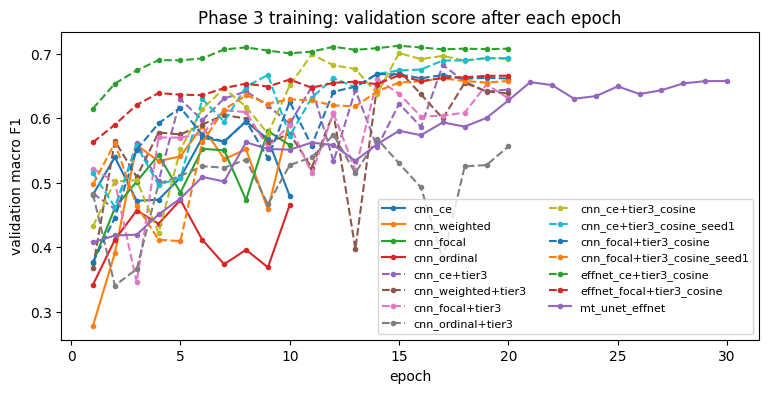

,baseline (pretrained),cnn_ce,cnn_weighted,cnn_focal,cnn_ordinal,cnn_ce+tier3,cnn_weighted+tier3,cnn_focal+tier3,cnn_ordinal+tier3,cnn_ce+tier3_cosine,cnn_ce+tier3_cosine_seed1,cnn_focal+tier3_cosine,cnn_focal+tier3_cosine_seed1,effnet_ce+tier3_cosine,effnet_focal+tier3_cosine,mt_unet_effnet
F1 no-damage,0.787,0.918,0.882,0.843,0.692,0.936,0.917,0.903,0.812,0.947,0.947,0.907,0.898,0.952,0.910,0.948
F1 minor-damage,0.081,0.420,0.462,0.442,0.208,0.521,0.521,0.489,0.316,0.566,0.559,0.546,0.522,0.592,0.522,0.330
F1 major-damage,0.030,0.568,0.548,0.468,0.341,0.600,0.600,0.610,0.419,0.660,0.656,0.639,0.625,0.685,0.637,0.571
F1 destroyed,0.344,0.605,0.604,0.627,0.656,0.761,0.708,0.711,0.744,0.796,0.778,0.671,0.650,0.803,0.732,0.821
macro F1,0.311,0.628,0.624,0.595,0.474,0.705,0.686,0.678,0.573,0.743,0.735,0.691,0.674,0.758,0.700,0.667
xView2 F1 (harmonic mean),0.079,0.581,0.590,0.557,0.374,0.670,0.657,0.646,0.493,0.715,0.708,0.668,0.649,0.735,0.672,0.567
accuracy,0.625,0.846,0.787,0.734,0.546,0.868,0.834,0.816,0.682,0.889,0.888,0.826,0.812,0.893,0.828,0.861
quadratic weighted kappa,0.314,0.603,0.607,0.577,0.550,0.753,0.720,0.723,0.681,0.803,0.795,0.695,0.668,0.827,0.740,0.823
mean class error,0.750,0.259,0.359,0.421,0.565,0.208,0.262,0.263,0.385,0.168,0.174,0.281,0.310,0.160,0.257,0.190
far errors (off by 2+ classes) %,22.334,7.302,9.610,11.662,10.067,5.770,6.756,5.328,6.058,4.254,4.496,6.862,7.703,3.798,5.818,4.264


,best validation macro F1,test macro F1
effnet_ce+tier3_cosine,0.712,0.758
cnn_ce+tier3_cosine,0.701,0.743
cnn_ce+tier3_cosine_seed1,0.693,0.735
cnn_ce+tier3,0.682,0.705
cnn_weighted+tier3,0.674,0.686
cnn_focal+tier3_cosine,0.668,0.691
effnet_focal+tier3_cosine,0.666,0.700
cnn_focal+tier3_cosine_seed1,0.662,0.674
cnn_focal+tier3,0.660,0.678
mt_unet_effnet,0.658,0.667


Selected model (highest validation macro F1): effnet_ce+tier3_cosine


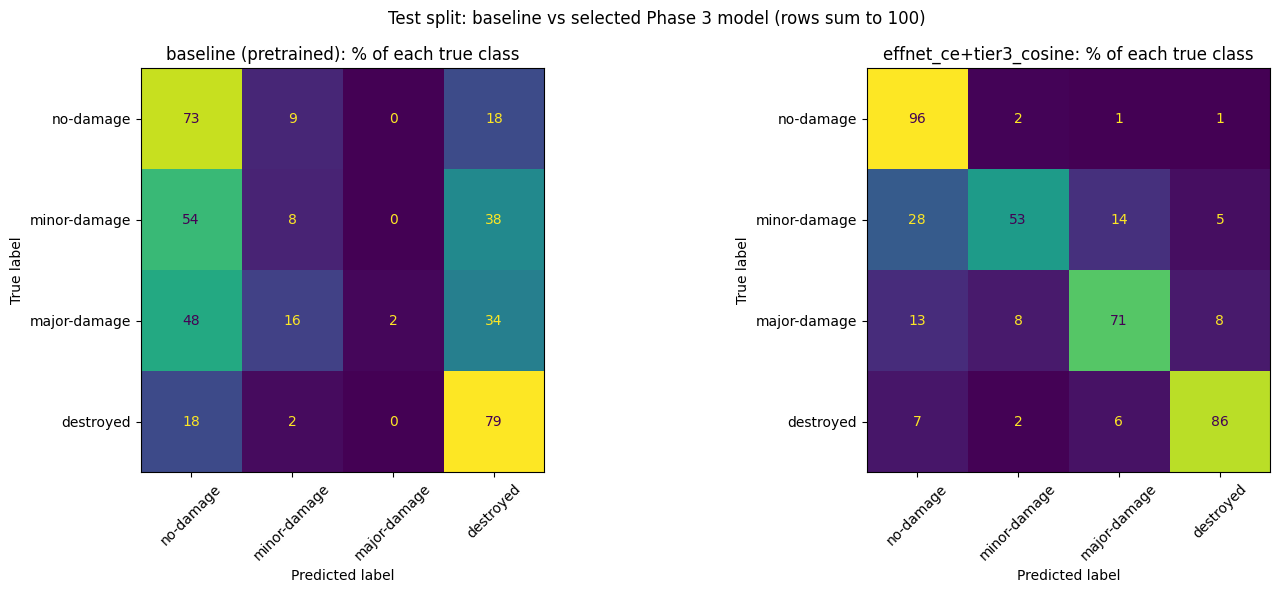

,test buildings,damaged (true) %,baseline macro F1,effnet_ce+tier3_cosine macro F1
disaster,,,,
hurricane-michael,5602,34.9,0.241,0.561
hurricane-harvey,7609,45.2,0.226,0.547
hurricane-matthew,3971,84.5,0.200,0.540
hurricane-florence,2117,20.8,0.285,0.535
guatemala-volcano,30,13.3,0.194,0.531
midwest-flooding,2391,4.8,0.239,0.518
palu-tsunami,12414,12.0,0.326,0.512
santa-rosa-wildfire,4214,23.5,0.363,0.481
socal-fire,4102,12.7,0.355,0.460


In [22]:
if p3_histories:
    fig, ax = plt.subplots(figsize=(9, 4))
    for h in p3_histories:
        ax.plot(h["epoch"], h["val_macro_f1"], marker="o", markersize=3,
                linestyle="--" if "+tier3" in h["experiment"].iloc[0] else "-", label=h["experiment"].iloc[0])
    ax.set_xlabel("epoch"); ax.set_ylabel("validation macro F1"); ax.legend(fontsize=8, ncol=2)
    ax.set_title("Phase 3 training: validation score after each epoch"); plt.show()

for name, preds in model_predictions.items():
    results_table[name] = damage_scores(preds["true_class"], preds["pred_class"])
display(results_table.round(3))

# Model selection uses the VALIDATION score only. The test split is for reporting, never for choosing.
selection = pd.DataFrame({
    "best validation macro F1": {h["experiment"].iloc[0]: h["val_macro_f1"].max() for h in p3_histories},
    "test macro F1": {h["experiment"].iloc[0]: results_table.loc["macro F1", h["experiment"].iloc[0]] for h in p3_histories},
}).sort_values("best validation macro F1", ascending=False)
display(selection.round(3))

selected_model_name = selection.index[0] if len(selection) else "baseline (pretrained)"
selected_preds = model_predictions[selected_model_name]
print("Selected model (highest validation macro F1):", selected_model_name)

if len(selection):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, (name, preds) in zip(axes, [("baseline (pretrained)", baseline_cls_df), (selected_model_name, selected_preds)]):
        cm_pct = confusion_matrix(preds["true_class"], preds["pred_class"], labels=DAMAGE_CLASSES, normalize="true") * 100
        ConfusionMatrixDisplay(cm_pct, display_labels=DAMAGE_CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".0f")
        ax.set_title(f"{name}: % of each true class")
    plt.suptitle("Test split: baseline vs selected Phase 3 model (rows sum to 100)")
    plt.tight_layout(); plt.show()

# Does the selected model work everywhere, or only on some disasters?
def macro_f1_by_disaster(preds):
    return preds.groupby("disaster").apply(
        lambda g: f1_score(g["true_class"], g["pred_class"], labels=DAMAGE_CLASSES, average="macro", zero_division=0),
        include_groups=False)

by_disaster = pd.DataFrame({
    "test buildings": selected_preds.groupby("disaster").size(),
    "damaged (true) %": (100 * selected_preds.assign(d=selected_preds["true_class"] != "no-damage").groupby("disaster")["d"].mean()).round(1),
    "baseline macro F1": macro_f1_by_disaster(baseline_cls_df),
    f"{selected_model_name} macro F1": macro_f1_by_disaster(selected_preds),
}).sort_values(f"{selected_model_name} macro F1", ascending=False)
by_disaster.round(3)

## 3d. Diagnosing the ordinal model (no retraining)

The ordinal (CORAL) model scored worst, which is the opposite of what was expected. Before concluding that "ordinal loss does not help", it is worth separating two things the model does:

1. **Ranking:** giving each building a damage score, higher for worse damage.
2. **Cutting:** deciding where on that score "minor" ends and "major" begins. The model has three cut-offs, and by default a building passes a cut-off when its score is above zero.

If the ranking is good but the cut-offs are in the wrong place, the model looks bad for a fixable reason. This is likely here: the class weights make damaged buildings count about nine times more than undamaged ones during training, which pushes all three cut-offs towards "call it damaged".

**The test:** keep the trained model exactly as it is, and move only the three cut-offs to wherever gives the best macro F1 **on the validation tiles**. Then score the result on the test split. Nothing is retrained and the test split is not used to choose anything.

**How to read the result:** if the score jumps, the ordinal model had learned to rank damage well and was let down by its cut-offs. If it does not, the ranking itself is the weak part.

In [23]:
def experiment_scores(exp):
    """Raw model outputs on the validation and test crops for one trained experiment (cached)."""
    tag = f"p3_{exp.name}_{exp.epochs}ep_{exp.samples_per_epoch}spe"
    val_path, test_path = OUTPUT_DIR / f"{tag}_val_scores.npy", OUTPUT_DIR / f"{tag}_test_scores.npy"
    if not (val_path.exists() and test_path.exists()):
        model = build_pair_classifier(ordinal=exp.loss == "coral", encoder=exp.encoder)
        model.load_weights(OUTPUT_DIR / f"{tag}.weights.h5")
        np.save(val_path, model.predict(CropBatches(pool_crops, pool_labels, val_idx), verbose=0))
        test_idx = np.flatnonzero(test_meta["has_crop"].to_numpy())
        np.save(test_path, model.predict(CropBatches(test_crops, test_labels, test_idx), verbose=0))
    return np.load(val_path), np.load(test_path)


def calibrate_cutoffs(val_scores, val_true, grid=np.linspace(-4, 4, 81), rounds=3):
    """Move one cut-off at a time to the grid value giving the best validation macro F1."""
    cutoffs = np.zeros(val_scores.shape[1])
    for _ in range(rounds):
        for k in range(len(cutoffs)):
            trial = [f1_score(val_true, (val_scores > np.r_[cutoffs[:k], g, cutoffs[k + 1:]]).sum(axis=1), average="macro") for g in grid]
            cutoffs[k] = grid[int(np.argmax(trial))]
    return cutoffs


calibration_rows = []
for exp in P3_EXPERIMENTS[P3_EXPERIMENTS["loss"] == "coral"].itertuples(index=False):
    if exp.name not in model_predictions:
        continue
    val_scores, test_scores = experiment_scores(exp)
    val_true, test_true = pool_labels[val_idx], test_labels[np.flatnonzero(test_meta["has_crop"].to_numpy())]
    cutoffs = calibrate_cutoffs(val_scores, val_true)
    for label, c in [("default cut-offs (0, 0, 0)", np.zeros(3)), ("cut-offs tuned on validation", cutoffs)]:
        test_pred = (test_scores > c).sum(axis=1)
        calibration_rows.append({
            "experiment": exp.name, "cut-offs": label, "values": np.round(c, 1).tolist(),
            "validation macro F1": f1_score(val_true, (val_scores > c).sum(axis=1), average="macro"),
            "test macro F1": f1_score(test_true, test_pred, average="macro"),
            **{f"test F1 {cls}": f for cls, f in zip(DAMAGE_CLASSES, f1_score(test_true, test_pred, average=None, labels=range(N_CLASSES)))},
        })
    # make the calibrated version available to the results table and to Section 7b
    calibrated = model_predictions[exp.name].copy()
    calibrated["pred_class"] = [DAMAGE_CLASSES[i] for i in (test_scores > cutoffs).sum(axis=1)]
    model_predictions[f"{exp.name} (cut-offs tuned)"] = calibrated
    results_table[f"{exp.name} (cut-offs tuned)"] = damage_scores(calibrated["true_class"], calibrated["pred_class"])

display(pd.DataFrame(calibration_rows).set_index(["experiment", "cut-offs"]).round(3))
results_table[[c for c in results_table.columns if "ordinal" in c or c in ("baseline (pretrained)", selected_model_name)]].round(3)

values  \
experiment        cut-offs                                         
cnn_ordinal       default cut-offs (0, 0, 0)     [0.0, 0.0, 0.0]   
                  cut-offs tuned on validation   [0.7, 0.0, 0.1]   
cnn_ordinal+tier3 default cut-offs (0, 0, 0)     [0.0, 0.0, 0.0]   
                  cut-offs tuned on validation  [0.8, 0.2, -0.6]   

                                                validation macro F1  \
experiment        cut-offs                                            
cnn_ordinal       default cut-offs (0, 0, 0)                  0.473   
                  cut-offs tuned on validation                0.511   
cnn_ordinal+tier3 default cut-offs (0, 0, 0)                  0.574   
                  cut-offs tuned on validation                0.595   

                                                test macro F1  \
experiment        cut-offs                                      
cnn_ordinal       default cut-offs (0, 0, 0)            0.474   
                  cut-offs tuned on validation          0.501   
cnn_ordinal+tier3 default cut-offs (0, 0, 0)            0.573   
                  cut-offs tuned on validation          0.593   

                                                test F1 no-damage  \
experiment        cut-offs                                          
cnn_ordinal       default cut-offs (0, 0, 0)                0.692   
                  cut-offs tuned on validation              0.834   
cnn_ordinal+tier3 default cut-offs (0, 0, 0)                0.812   
                  cut-offs tuned on validation              0.867   

                                                test F1 minor-damage  \
experiment        cut-offs                                             
cnn_ordinal       default cut-offs (0, 0, 0)                   0.208   
                  cut-offs tuned on validation                 0.162   
cnn_ordinal+tier3 default cut-offs (0, 0, 0)                   0.316   
                  cut-offs tuned on validation                 0.335   

                                                test F1 major-damage  \
experiment        cut-offs                                             
cnn_ordinal       default cut-offs (0, 0, 0)                   0.341   
                  cut-offs tuned on validation                 0.348   
cnn_ordinal+tier3 default cut-offs (0, 0, 0)                   0.419   
                  cut-offs tuned on validation                 0.420   

                                                test F1 destroyed  
experiment        cut-offs                                         
cnn_ordinal       default cut-offs (0, 0, 0)                0.656  
                  cut-offs tuned on validation              0.659  
cnn_ordinal+tier3 default cut-offs (0, 0, 0)                0.744  
                  cut-offs tuned on validation              0.749

,baseline (pretrained),cnn_ordinal,cnn_ordinal+tier3,effnet_ce+tier3_cosine,cnn_ordinal (cut-offs tuned),cnn_ordinal+tier3 (cut-offs tuned)
F1 no-damage,0.787,0.692,0.812,0.952,0.834,0.867
F1 minor-damage,0.081,0.208,0.316,0.592,0.162,0.335
F1 major-damage,0.030,0.341,0.419,0.685,0.348,0.420
F1 destroyed,0.344,0.656,0.744,0.803,0.659,0.749
macro F1,0.311,0.474,0.573,0.758,0.501,0.593
xView2 F1 (harmonic mean),0.079,0.374,0.493,0.735,0.340,0.509
accuracy,0.625,0.546,0.682,0.893,0.696,0.750
quadratic weighted kappa,0.314,0.550,0.681,0.827,0.602,0.711
mean class error,0.750,0.565,0.385,0.160,0.427,0.320
far errors (off by 2+ classes) %,22.334,10.067,6.058,3.798,10.968,5.848


## 4. Construction Type — Layer 1: regional mix from GEM (the novel contribution starts here)

**This is where the project departs from the standard xView2 task.** Everything above is the established damage-detection pipeline. To turn a damaged building into materials, carbon and cost we need to know *what it is made of*, which a satellite image does not tell us directly.

**Source:** the [GEM Global Exposure Model v2026.0.0](https://doi.org/10.5281/zenodo.8117363) (Yepes-Estrada et al., 2023/2026; licence CC BY-NC-SA 4.0 — non-commercial, attribution, share-alike). For every country and state/province it lists how many buildings exist of each occupancy (residential, commercial, industrial) and construction class, with their floor area, storeys, replacement cost and embodied carbon.

**How Layer 1 uses it:** each building is given the *mix* of its region. We do not claim to know whether one particular Texas house is wood or masonry; we say "a building here is 71% likely wood-frame, 20% masonry, ..." and calculate with that weighted average. Summed over thousands of buildings, the regional total comes out right even though no single building is labelled.

**What Layer 1 cannot do:** it treats every building in a region alike, so a warehouse and a house get the same mix. Telling them apart from the image is the job of the Layer 2 CNN (Phase 4), which will be checked against this layer.

**Three explicit assumptions are needed**, all shown as tables below so they can be challenged:
1. Which GEM region each disaster falls in.
2. How GEM's construction classes map onto the four structure types RASMI uses (concrete, masonry, steel, timber).
3. How GEM's occupancy maps onto RASMI's three functions (single-family, multi-family, non-residential).

In [24]:
gem_df = pd.read_csv(GEM_PATH)
gem_df = gem_df[gem_df["total_floor_area_m2"] > 0]

# --- Assumption 1: where each disaster is ------------------------------------
# gem_region = the GEM state/province holding most of the disaster's buildings.
# location_checked = True where confirmed from the building coordinates in the labels.
# Note: despite its name, nepal-flooding's buildings lie at about 26.6N, 83.4E (around Gorakhpur),
# just across the border in Uttar Pradesh, India, so it uses India's figures.
DISASTER_LOCATION = pd.DataFrame([
    ("guatemala-volcano",   "Guatemala", "GTM", "Escuintla",        "LAM_LAM-L",  True),
    ("hurricane-florence",  "USA",       "USA", "North Carolina",   "OECD_USA",   True),
    ("hurricane-harvey",    "USA",       "USA", "Texas",            "OECD_USA",   True),
    ("hurricane-matthew",   "Haiti",     "HTI", "Grande’Anse",      "LAM_LAM-L",  True),
    ("hurricane-michael",   "USA",       "USA", "Florida",          "OECD_USA",   True),
    ("mexico-earthquake",   "Mexico",    "MEX", "Ciudad de México", "LAM_MEX",    True),
    ("midwest-flooding",    "USA",       "USA", "Oklahoma",         "OECD_USA",   True),
    ("palu-tsunami",        "Indonesia", "IDN", "Sulawesi Tengah",  "ASIA_IDN",   True),
    ("santa-rosa-wildfire", "USA",       "USA", "California",       "OECD_USA",   True),
    ("socal-fire",          "USA",       "USA", "California",       "OECD_USA",   True),
    ("joplin-tornado",      "USA",       "USA", "Missouri",         "OECD_USA",   True),
    ("lower-puna-volcano",  "USA",       "USA", "Hawaii",           "OECD_USA",   True),
    ("moore-tornado",       "USA",       "USA", "Oklahoma",         "OECD_USA",   True),
    ("nepal-flooding",      "India",     "IND", "Uttar Pradesh",    "ASIA_IND",   True),
    ("pinery-bushfire",     "Australia", "AUS", "South Australia",  "OECD_AUNZ",  True),
    ("portugal-wildfire",   "Portugal",  "PRT", "Leiria",           "OECD_EU15",  True),
    ("sunda-tsunami",       "Indonesia", "IDN", "Banten",           "ASIA_IDN",   True),
    ("tuscaloosa-tornado",  "USA",       "USA", "Alabama",          "OECD_USA",   True),
    ("woolsey-fire",        "USA",       "USA", "California",       "OECD_USA",   True),
], columns=["disaster", "country", "iso3", "gem_region", "rasmi_region", "location_checked"])

# --- Assumption 2: GEM construction class -> RASMI structure type ------------
# RASMI structure types: C = reinforced concrete, M = masonry, S = steel, T = timber
GEM_TO_RASMI_STRUCTURE = pd.DataFrame([
    ("W",        "Wood",                                    "T", "direct match"),
    ("MUR",      "Unreinforced masonry",                    "M", "direct match"),
    ("MR|MCF",   "Reinforced / confined masonry",           "M", "direct match"),
    ("ADO|ST|E", "Adobe, stone, earth",                     "M", "nearest class: heavy load-bearing walls"),
    ("CR+",      "Reinforced concrete (engineered)",        "C", "direct match"),
    ("CR-",      "Reinforced concrete (low/no seismic code)", "C", "direct match"),
    ("S",        "Steel",                                   "S", "direct match"),
    ("HYB",      "Hybrid / mixed materials (India only)",   "M", "ASSUMPTION: treated as masonry, the dominant local material"),
    ("OT",       "Other (mobile homes, informal housing)",  "T", "ASSUMPTION: lightest RASMI class used for light structures"),
], columns=["gem_class", "meaning", "rasmi_structure", "basis"])

# --- Assumption 3: GEM occupancy -> RASMI function ---------------------------
# RS = residential single-family, RM = residential multi-family, NR = non-residential
MULTI_FAMILY_MIN_STOREYS = 3   # residential classes averaging this many storeys or more count as multi-family

def rasmi_function(occupancy, avg_storeys):
    if occupancy != "RES":
        return "NR"
    return "RM" if avg_storeys >= MULTI_FAMILY_MIN_STOREYS else "RS"

# Every region named above must exist in the GEM table
known = set(zip(gem_df["iso3"], gem_df["adm1_name"]))
missing = [r.disaster for r in DISASTER_LOCATION.itertuples() if (r.iso3, r.gem_region) not in known]
assert not missing, f"GEM region not found for: {missing}"

display(DISASTER_LOCATION)
display(GEM_TO_RASMI_STRUCTURE)

,disaster,country,iso3,gem_region,rasmi_region,location_checked
0,guatemala-volcano,Guatemala,GTM,Escuintla,LAM_LAM-L,True
1,hurricane-florence,USA,USA,North Carolina,OECD_USA,True
2,hurricane-harvey,USA,USA,Texas,OECD_USA,True
3,hurricane-matthew,Haiti,HTI,Grande’Anse,LAM_LAM-L,True
4,hurricane-michael,USA,USA,Florida,OECD_USA,True
5,mexico-earthquake,Mexico,MEX,Ciudad de México,LAM_MEX,True
6,midwest-flooding,USA,USA,Oklahoma,OECD_USA,True
7,palu-tsunami,Indonesia,IDN,Sulawesi Tengah,ASIA_IDN,True
8,santa-rosa-wildfire,USA,USA,California,OECD_USA,True
9,socal-fire,USA,USA,California,OECD_USA,True


,gem_class,meaning,rasmi_structure,basis
0,W,Wood,T,direct match
1,MUR,Unreinforced masonry,M,direct match
2,MR|MCF,Reinforced / confined masonry,M,direct match
3,ADO|ST|E,"Adobe, stone, earth",M,nearest class: heavy load-bearing walls
4,CR+,Reinforced concrete (engineered),C,direct match
5,CR-,Reinforced concrete (low/no seismic code),C,direct match
6,S,Steel,S,direct match
7,HYB,Hybrid / mixed materials (India only),M,"ASSUMPTION: treated as masonry, the dominant l..."
8,OT,"Other (mobile homes, informal housing)",T,ASSUMPTION: lightest RASMI class used for ligh...


**Midpoint output 4 — the construction mix each disaster region is given, plus a size sanity check.**

The chart shows, per disaster, what share of buildings falls in each structure type. The first table is one region spelled out in full (the worked example a reader can check against the GEM file). The second table is an independent check: GEM implies an average building footprint for each region (floor area ÷ storeys); if that is wildly different from the footprints actually measured in the xBD labels, the regional match is suspect.

A note on storeys: GEM gives storey *ranges* inside its class codes (`H:1-3`). These were converted to one number when the lookup file was built: a single value is used as is, a range uses its midpoint, and "more than N" uses N+1.

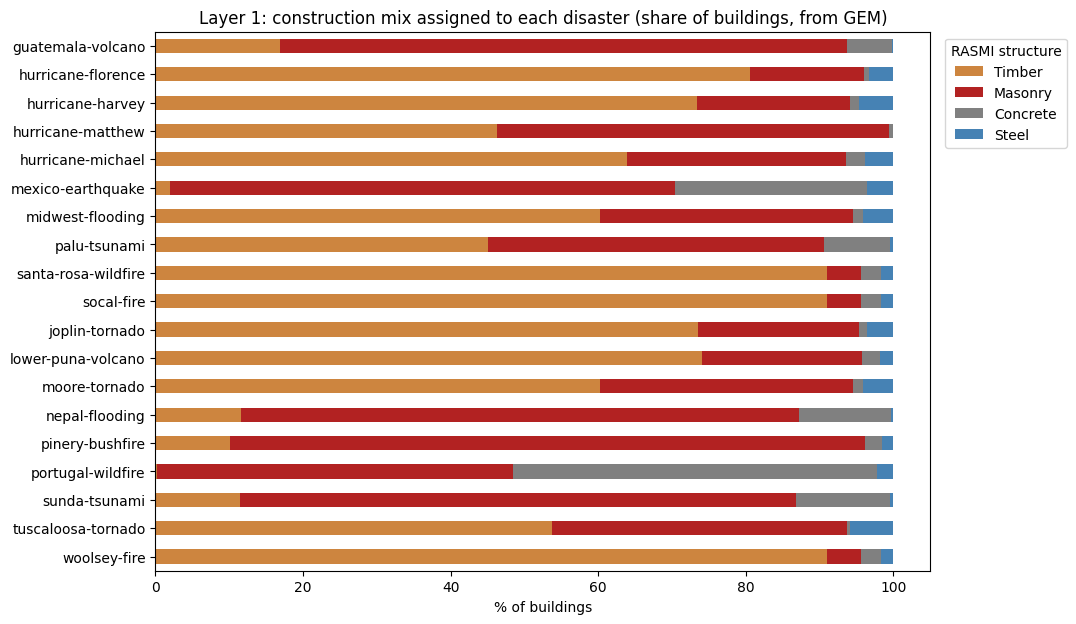

Worked example: hurricane-harvey (GEM region: Texas)


,occupancy,macro_taxonomy,rasmi_structure,rasmi_function,share_of_buildings_%,avg_storeys,cost_usd_per_m2,gem_kgco2e_per_m2
0,RES,W,T,RS,64.3,1.5,1741.8,99.7
1,RES,MUR,M,RS,17.7,1.5,1832.0,436.8
2,RES,OT,T,RS,6.3,1.0,698.8,99.6
3,COM,MUR,M,NR,2.6,1.6,1882.8,591.1
4,COM,W,T,NR,2.5,1.7,1923.4,186.8
5,COM,S,S,NR,2.1,1.8,1851.0,359.1
6,RES,S,S,RS,2.0,2.0,2031.3,283.8
7,COM,CR-,C,NR,0.9,1.7,1720.9,476.3
8,IND,S,S,NR,0.6,1.5,1650.3,327.9
9,IND,MUR,M,NR,0.4,1.5,1565.1,542.2


,gem_region,GEM implied mean footprint m2,xBD measured mean footprint m2,xBD measured median footprint m2
disaster,,,,
guatemala-volcano,Escuintla,67.0,107.0,77.0
hurricane-florence,North Carolina,159.0,209.0,140.0
hurricane-harvey,Texas,177.0,378.0,268.0
hurricane-matthew,Grande’Anse,64.0,92.0,60.0
hurricane-michael,Florida,145.0,267.0,199.0
mexico-earthquake,Ciudad de México,207.0,237.0,130.0
midwest-flooding,Oklahoma,150.0,202.0,150.0
palu-tsunami,Sulawesi Tengah,59.0,141.0,99.0
santa-rosa-wildfire,California,154.0,236.0,208.0


In [25]:
def gem_classes_for(loc):
    """All GEM building classes for one disaster's region, with the per-class
    quantities the rest of the pipeline needs."""
    g = gem_df[(gem_df["iso3"] == loc.iso3) & (gem_df["adm1_name"] == loc.gem_region)].copy()
    g.insert(0, "disaster", loc.disaster)
    g["rasmi_region"] = loc.rasmi_region
    g["share_of_buildings"] = g["buildings"] / g["buildings"].sum()
    g["rasmi_structure"] = g["macro_taxonomy"].map(GEM_TO_RASMI_STRUCTURE.set_index("gem_class")["rasmi_structure"])
    g["rasmi_function"] = [rasmi_function(o, s) for o, s in zip(g["occupancy"], g["avg_storeys"])]
    g["cost_usd_per_m2"] = g["bldg_replacement_cost_usd"] / g["total_floor_area_m2"]
    g["gem_kgco2e_per_m2"] = 1000 * g["embodied_carbon_tco2e"] / g["total_floor_area_m2"]
    # Expected m2 of floor in this class for every 1 m2 of building footprint in the region:
    # (chance a building is this class) x (its storeys)
    g["floor_m2_per_footprint_m2"] = g["share_of_buildings"] * g["avg_storeys"]
    return g

region_classes = pd.concat([gem_classes_for(loc) for loc in DISASTER_LOCATION.itertuples()], ignore_index=True)
assert region_classes["rasmi_structure"].notna().all(), "a GEM class has no RASMI mapping"

# Chart: structure mix per disaster region
STRUCTURE_NAMES = {"T": "Timber", "M": "Masonry", "C": "Concrete", "S": "Steel"}
STRUCTURE_COLORS = {"Timber": "peru", "Masonry": "firebrick", "Concrete": "gray", "Steel": "steelblue"}
mix = region_classes.pivot_table(index="disaster", columns="rasmi_structure", values="share_of_buildings", aggfunc="sum").fillna(0)
mix = (100 * mix[["T", "M", "C", "S"]]).rename(columns=STRUCTURE_NAMES).loc[DISASTER_LOCATION["disaster"][::-1]]
mix.plot(kind="barh", stacked=True, color=[STRUCTURE_COLORS[c] for c in mix.columns], figsize=(10, 7),
         title="Layer 1: construction mix assigned to each disaster (share of buildings, from GEM)")
plt.xlabel("% of buildings"); plt.ylabel("")
plt.legend(title="RASMI structure", loc="upper left", bbox_to_anchor=(1.01, 1)); plt.show()

# Worked example: every GEM class behind one region
example = region_classes[region_classes["disaster"] == "hurricane-harvey"].sort_values("share_of_buildings", ascending=False)
print("Worked example: hurricane-harvey (GEM region: Texas)")
display(example[["occupancy", "macro_taxonomy", "rasmi_structure", "rasmi_function", "share_of_buildings",
                 "avg_storeys", "cost_usd_per_m2", "gem_kgco2e_per_m2"]]
        .assign(share_of_buildings=lambda d: (100 * d["share_of_buildings"]).round(2))
        .rename(columns={"share_of_buildings": "share_of_buildings_%"}).round(1).reset_index(drop=True))

# Sanity check: footprint implied by GEM vs footprint measured in the xBD labels
implied = region_classes.assign(footprint_total=region_classes["total_floor_area_m2"] / region_classes["avg_storeys"]) \
    .groupby("disaster").agg(footprint_total=("footprint_total", "sum"), buildings=("buildings", "sum"))
size_check = pd.DataFrame({
    "gem_region": DISASTER_LOCATION.set_index("disaster")["gem_region"],
    "GEM implied mean footprint m2": implied["footprint_total"] / implied["buildings"],
    "xBD measured mean footprint m2": buildings_df.groupby("disaster")["footprint_m2"].mean(),
    "xBD measured median footprint m2": buildings_df.groupby("disaster")["footprint_m2"].median(),
}).dropna().round(0)
size_check

## 4b. Construction Type — Layer 2: a CNN that adjusts the regional mix per building

**The problem with Layer 1** is that every building in a region gets the same mix. **Layer 2** is a small CNN that looks at each building (its pre-disaster crop and its footprint size) and outputs its own probabilities of being timber, masonry, concrete or steel.

**The difficulty: there are no labels.** Nobody has recorded what each xBD building is made of. What we do have is GEM's mix for each *region*. So the network is trained by **learning from label proportions**:

1. Take a batch of 256 buildings, all from one region.
2. The network predicts four probabilities for each building.
3. Average those predictions over the batch. That average is the network's estimate of the region's mix.
4. The loss is how far that average is from GEM's mix for the region (KL divergence). No individual building is ever told what it is.

To get the batch average right in *every* region with one set of weights, the network has to find image features that go with construction type. That is the hope. **The risk** is that it instead learns to recognise the region ("this looks like Haiti") and gives every building there Haiti's mix, which would add nothing to Layer 1.

**The test that tells the two apart: leave one region out.** For each of the 16 regions in turn, the network is trained on the other 15 and then asked to predict the mix of the region it has never seen. It cannot have memorised that region, so if its predicted mix is close to GEM's, it has learned something that transfers. Its error is compared with a **no-image guess**: the average mix of the 15 training regions, which is the best anyone could do without looking at the buildings.

**How to read the result:** the measure is *total variation distance* between predicted and GEM mix: 0 means identical, 1 means completely different, and roughly "the share of buildings assigned to the wrong type". Layer 2 is worth using only if it beats the no-image guess on held-out regions. If it does not, the notebook says so and Layer 1 stays in use.

**A design detail that matters: normalisation.** The Phase 3 encoder uses *batch normalisation*, which rescales each layer using the average and spread of the whole batch. Here every batch comes from a single region, so those batch statistics would themselves reveal the region, and the network could match the regional mix during training without learning anything about individual buildings. It would then behave differently when used one building at a time. A first version of this section had exactly that flaw: after training on all regions, its predicted mixes were still far from GEM's (0.54 total variation on average) once it was run normally. Layer 2 therefore uses *group normalisation*, which rescales each image using only its own values, so training and use behave the same way.

**Limits stated up front:** only 16 regions exist to learn from; walls are not visible from above, so the network can only use roofs, size, shape and surroundings; and GEM's mix describes a whole state or province, not the specific neighbourhoods photographed.

In [26]:
L2_TRAIN = True            # False = only load cached results
L2_BAG_SIZE = 256          # buildings per batch, all from one region
L2_STEPS = 400             # batches per training run (about 100,000 buildings)
L2_EVAL_BUILDINGS = 4000   # buildings sampled from a held-out region to estimate its predicted mix
STRUCTURES = ["T", "M", "C", "S"]   # timber, masonry, concrete, steel (RASMI structure types)

# --- one row per region: GEM's structure mix (the training target) -----------
loc = DISASTER_LOCATION.assign(region=DISASTER_LOCATION["iso3"] + ": " + DISASTER_LOCATION["gem_region"])
region_of_disaster = loc.set_index("disaster")["region"]
structure_mix = region_classes.pivot_table(index="disaster", columns="rasmi_structure",
                                           values="share_of_buildings", aggfunc="sum").fillna(0)[STRUCTURES]
region_targets = structure_mix.groupby(region_of_disaster).first()      # same for every disaster in a region

l2_meta = pool_meta[pool_meta["has_crop"]].copy()                        # all train + tier3 buildings
l2_meta["region"] = l2_meta["disaster"].map(region_of_disaster)
l2_log_size = np.log10(pool_meta["footprint_m2"].clip(lower=1)).to_numpy(np.float32)
region_indices = {r: g.index.to_numpy() for r, g in l2_meta.groupby("region")}
REGIONS = sorted(region_indices)
display(region_targets.loc[REGIONS].mul(100).round(1).assign(buildings=[len(region_indices[r]) for r in REGIONS])
        .rename(columns={"T": "timber %", "M": "masonry %", "C": "concrete %", "S": "steel %"}))


# --- the model ----------------------------------------------------------------
def build_structure_classifier():
    """Pre-disaster crop + footprint size -> probabilities of timber / masonry / concrete / steel."""
    crop = keras.Input((P3_CROP_SIZE, P3_CROP_SIZE, 3), name="pre_crop")
    size = keras.Input((1,), name="log10_footprint_m2")
    features = build_encoder(norm="group")(layers.Rescaling(1 / 255.0)(crop))   # Phase 3 encoder design, group-normalised
    h = layers.Concatenate()([features, size])
    h = layers.Dense(64, activation="relu")(h)
    return keras.Model([crop, size], layers.Dense(len(STRUCTURES), activation="softmax")(h))


def proportion_loss(y_true, y_pred):
    """Learning from label proportions: compare the batch's AVERAGE prediction with the region's mix.
    y_true holds the same regional mix repeated for every building in the batch."""
    target = y_true[0]
    batch_mix = keras.ops.mean(y_pred, axis=0)
    kl = keras.ops.sum(target * (keras.ops.log(target + 1e-7) - keras.ops.log(batch_mix + 1e-7)))
    return kl * keras.ops.ones_like(y_pred[:, 0])


class RegionBags(keras.utils.PyDataset):
    """Each batch = L2_BAG_SIZE random buildings from ONE randomly chosen region."""
    def __init__(self, regions, steps, seed=0):
        super().__init__()
        self.regions, self.steps, self.rng = list(regions), steps, np.random.default_rng(seed)
    def __len__(self):
        return self.steps
    def __getitem__(self, i):
        region = self.regions[self.rng.integers(len(self.regions))]
        idx = np.sort(self.rng.choice(region_indices[region], L2_BAG_SIZE))
        crops = pool_crops[idx][..., :3]                                  # pre-disaster image only
        if self.rng.random() < 0.5: crops = crops[:, :, ::-1]
        crops = np.rot90(crops, k=int(self.rng.integers(4)), axes=(1, 2))
        target = np.tile(region_targets.loc[region].to_numpy(np.float32), (L2_BAG_SIZE, 1))
        return (np.ascontiguousarray(crops), l2_log_size[idx][:, None]), target


def predict_structure(model, idx):
    """Per-building structure probabilities for the given pool positions."""
    idx = np.sort(np.asarray(idx)); out = []
    for start in range(0, len(idx), 512):
        chunk = idx[start:start + 512]
        out.append(model.predict_on_batch((pool_crops[chunk][..., :3], l2_log_size[chunk][:, None])))
    return idx, np.concatenate(out)


def train_structure_model(train_regions, seed=0, steps=None):
    keras.utils.set_random_seed(seed)
    model = build_structure_classifier()
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss=proportion_loss)
    model.fit(RegionBags(train_regions, steps or L2_STEPS, seed), epochs=1, verbose=0)
    return model


def total_variation(p, q):
    return 0.5 * np.abs(np.asarray(p) - np.asarray(q)).sum()


# --- leave-one-region-out ----------------------------------------------------
loro_path = OUTPUT_DIR / f"l2_leave_one_region_out_{L2_STEPS}steps_groupnorm.csv"
if loro_path.exists():
    loro = pd.read_csv(loro_path)
elif L2_TRAIN:
    rows = []
    for held_out in REGIONS:
        others = [r for r in REGIONS if r != held_out]
        model = train_structure_model(others)
        rng = np.random.default_rng(0)
        sample = rng.choice(region_indices[held_out], min(L2_EVAL_BUILDINGS, len(region_indices[held_out])), replace=False)
        _, probs = predict_structure(model, sample)
        target = region_targets.loc[held_out].to_numpy()
        no_image_guess = region_targets.loc[others].mean().to_numpy()
        rows.append({"held_out_region": held_out, "buildings": len(region_indices[held_out]),
                     **{f"gem_{s}": t for s, t in zip(STRUCTURES, target)},
                     **{f"cnn_{s}": p for s, p in zip(STRUCTURES, probs.mean(axis=0))},
                     "error_cnn": total_variation(probs.mean(axis=0), target),
                     "error_no_image_guess": total_variation(no_image_guess, target),
                     # how different are buildings from each other? 0 = every building gets the same answer
                     "spread_within_region": float(probs.std(axis=0).mean())})
        pd.DataFrame(rows).to_csv(loro_path.with_suffix(".partial.csv"), index=False)   # progress survives an interruption
    loro = pd.DataFrame(rows); loro.to_csv(loro_path, index=False)
    loro_path.with_suffix(".partial.csv").unlink(missing_ok=True)
else:
    loro = None
    print("Layer 2 leave-one-region-out has not been run yet (no cached result and L2_TRAIN is False)")

rasmi_structure,timber %,masonry %,concrete %,steel %,buildings
region,,,,,
AUS: South Australia,10.2,86.0,2.3,1.6,5437
GTM: Escuintla,16.9,76.8,6.2,0.1,682
HTI: Grande’Anse,46.4,53.1,0.5,0.1,13155
IDN: Banten,11.4,75.4,12.7,0.5,14357
IDN: Sulawesi Tengah,45.1,45.4,8.9,0.5,30993
IND: Uttar Pradesh,11.7,75.5,12.5,0.3,41582
MEX: Ciudad de México,1.9,68.4,26.0,3.6,32196
PRT: Leiria,0.2,48.3,49.3,2.3,22349
USA: Alabama,53.8,40.0,0.4,5.9,14098


**Midpoint output 4b — does Layer 2 predict the mix of a region it has never seen?** One row per held-out region. `error_cnn` is the distance between the CNN's predicted mix and GEM's; `error_no_image_guess` is the distance for the average-of-other-regions guess. The CNN "wins" a region when its error is smaller. `spread_within_region` shows whether the CNN gives different buildings different answers (larger) or the same answer to all (near zero).

The verdict printed underneath is the honest summary: how many regions the CNN wins, and the average error of each approach.

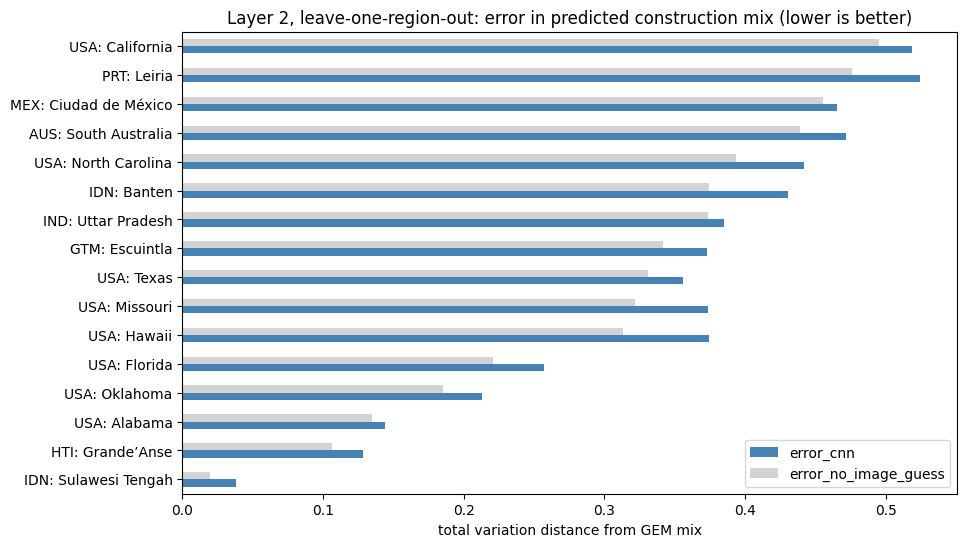

,buildings,GEM mix T/M/C/S %,CNN mix T/M/C/S %,error_cnn,error_no_image_guess,CNN better?,spread_within_region
held_out_region,,,,,,,
AUS: South Australia,5437,10 / 86 / 2 / 2,50 / 39 / 8 / 3,0.472,0.439,no,0.003
GTM: Escuintla,682,17 / 77 / 6 / 0,50 / 40 / 8 / 3,0.373,0.341,no,0.002
HTI: Grande’Anse,13155,46 / 53 / 1 / 0,50 / 40 / 7 / 3,0.128,0.106,no,0.003
IDN: Banten,14357,11 / 75 / 13 / 1,52 / 38 / 7 / 3,0.430,0.374,no,0.003
IDN: Sulawesi Tengah,30993,45 / 45 / 9 / 1,47 / 43 / 8 / 3,0.038,0.020,no,0.002
IND: Uttar Pradesh,41582,12 / 76 / 12 / 0,48 / 41 / 8 / 3,0.385,0.373,no,0.002
MEX: Ciudad de México,32196,2 / 68 / 26 / 4,48 / 42 / 7 / 2,0.465,0.455,no,0.003
PRT: Leiria,22349,0 / 48 / 49 / 2,52 / 40 / 6 / 2,0.525,0.476,no,0.009
USA: Alabama,14098,54 / 40 / 0 / 6,43 / 43 / 12 / 2,0.144,0.135,no,0.003


CNN beats the no-image guess in 0 of 16 held-out regions. Mean error: CNN 0.343, no-image guess 0.311.
Verdict: Layer 2 does NOT reliably beat the no-image guess on unseen regions; Layer 1 stays in use downstream.


In [27]:
if loro is not None:
    show = loro.set_index("held_out_region")
    table = pd.DataFrame({
        "buildings": show["buildings"],
        "GEM mix T/M/C/S %": [" / ".join(f"{100 * show.loc[r, f'gem_{s}']:.0f}" for s in STRUCTURES) for r in show.index],
        "CNN mix T/M/C/S %": [" / ".join(f"{100 * show.loc[r, f'cnn_{s}']:.0f}" for s in STRUCTURES) for r in show.index],
        "error_cnn": show["error_cnn"], "error_no_image_guess": show["error_no_image_guess"],
        "CNN better?": np.where(show["error_cnn"] < show["error_no_image_guess"], "yes", "no"),
        "spread_within_region": show["spread_within_region"],
    })
    show[["error_cnn", "error_no_image_guess"]].sort_values("error_no_image_guess").plot(
        kind="barh", figsize=(10, 6), color=["steelblue", "lightgray"],
        title="Layer 2, leave-one-region-out: error in predicted construction mix (lower is better)")
    plt.xlabel("total variation distance from GEM mix"); plt.ylabel(""); plt.show()
    display(table.round(3))
    wins = int((show["error_cnn"] < show["error_no_image_guess"]).sum())
    print(f"CNN beats the no-image guess in {wins} of {len(show)} held-out regions. "
          f"Mean error: CNN {show['error_cnn'].mean():.3f}, no-image guess {show['error_no_image_guess'].mean():.3f}.")
    LAYER2_HELPS = show["error_cnn"].mean() < show["error_no_image_guess"].mean() and wins > len(show) / 2
    print("Verdict:", "Layer 2 transfers to unseen regions better than guessing." if LAYER2_HELPS else
          "Layer 2 does NOT reliably beat the no-image guess on unseen regions; Layer 1 stays in use downstream.")

## 4c. What Layer 2 can still be used for: allocation *within* a known region

**The test above asked more than the pipeline needs.** It asked the CNN to work out the mix of a region it had never seen, and it could not. But the pipeline always knows the region's mix, because GEM covers every country. The job Layer 2 was meant to do is the next step: *within* a region whose mix is known, which buildings are the concrete ones and which the timber ones? That matters because buildings differ in size, so who gets which type changes the totals.

Two ways of doing that allocation are built here and compared with Layer 1 (which gives every building the same mix):

| Method | How each building's mix is set | Trained? |
|---|---|---|
| **Layer 1** | The region's GEM mix, identical for every building | no |
| **Size-adjusted Layer 1** | Starts from the region's mix and shifts it using the building's footprint: GEM says how large the average building of each type is in that region, so a building much larger than average is more likely to be one of the large types | no |
| **Layer 2 (CNN)** | The CNN from Section 4b, trained on all 16 regions, looking at the pre-disaster crop and footprint | yes |

Both adjusted methods are then **rescaled so that each region's average still equals GEM's mix exactly**. They can only move construction types between buildings, never change a region's totals by count.

**Assumptions in the size-adjusted method, stated openly:**
- A building's size is compared with its region's average in *relative* terms (xBD footprints run larger than GEM's, see Section 4), so "twice the regional average" means the same thing in both sources.
- Sizes within a type are assumed to scatter around that type's average by a factor of about 2 (`SIZE_SPREAD_LOG10 = 0.3`). This number is a judgement, not a measurement.

**How Layer 2 is checked without labels.** There is still no record of what any building is made of. But GEM gives one independent fact per region and type: its average building size. If the CNN's "probably concrete" buildings are larger than average in regions where GEM says concrete buildings are larger, and smaller where GEM says they are smaller, it is allocating in a direction GEM supports. This is **suggestive evidence, not proof**: a model can get the size pattern right and still be wrong about individual buildings. The size-adjusted method passes this check by construction, so it serves as the reference for how well a size-only rule can do.

CNN trained on all regions: its regional averages were already within 0.295 of GEM's mix (total variation, averaged over regions) before being rescaled to match exactly.


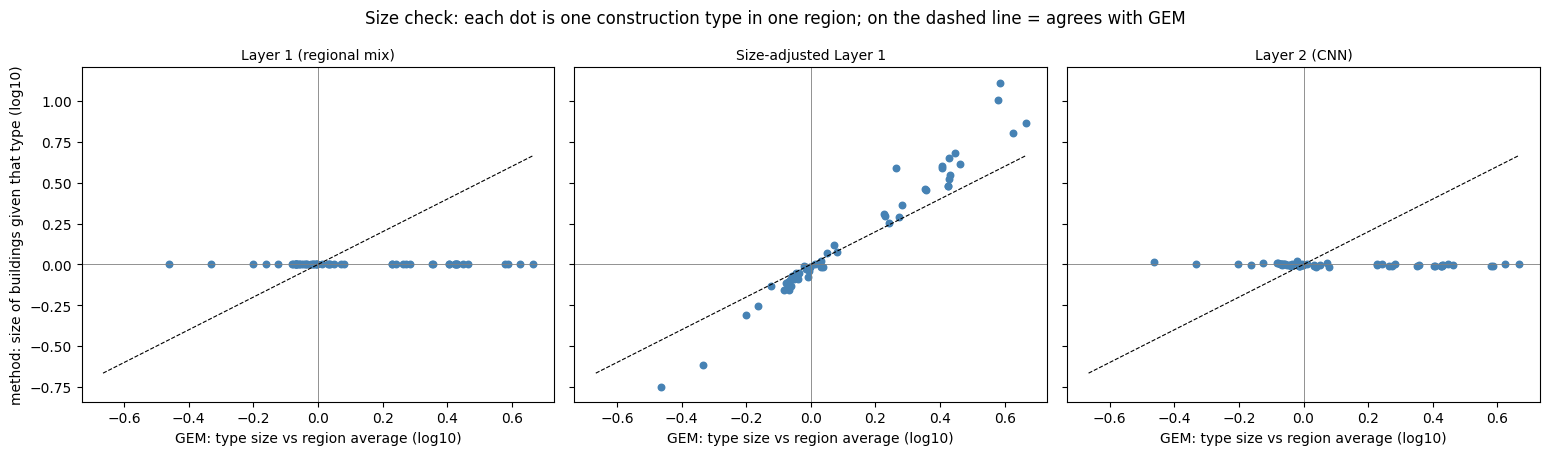

,rank correlation with GEM sizes,same direction as GEM %,region-type pairs compared
method,,,
Layer 1 (regional mix),0.02,0.0,55
Size-adjusted Layer 1,0.98,100.0,55
Layer 2 (CNN),-0.49,25.0,55


In [28]:
from scipy.stats import spearmanr

L2_FINAL_STEPS = 800          # training batches for the all-regions model (about 200,000 buildings)
SIZE_SPREAD_LOG10 = 0.3       # ASSUMPTION: sizes within a type scatter by a factor of ~2 around the type's average


def fit_to_region_mix(probs, rounds=20):
    """Rescale per-building probabilities so each region's average equals GEM's mix exactly
    (iterative proportional fitting). Rows keep summing to 1; only the split between buildings changes."""
    out = probs.copy()
    for region, idx in region_indices.items():
        target = region_targets.loc[region].to_numpy()
        p = out[idx] + 1e-9
        for _ in range(rounds):
            p = p * (target / p.mean(axis=0))          # match the regional average ...
            p = p / p.sum(axis=1, keepdims=True)       # ... while every building still sums to 1
        out[idx] = p
    return out


# --- Layer 1: every building gets its region's mix ----------------------------
n_pool = len(pool_meta)
layer1_probs = np.full((n_pool, len(STRUCTURES)), np.nan, dtype=np.float32)
for region, idx in region_indices.items():
    layer1_probs[idx] = region_targets.loc[region].to_numpy()

# --- Size-adjusted Layer 1 ------------------------------------------------------
# GEM's average footprint of each structure type, relative to the region's overall average
gem_size = region_classes.assign(footprint_total=region_classes["total_floor_area_m2"] / region_classes["avg_storeys"],
                                 region=region_classes["disaster"].map(region_of_disaster)).drop_duplicates(
                                     ["region", "occupancy", "macro_taxonomy"])
by_type = gem_size.groupby(["region", "rasmi_structure"])[["footprint_total", "buildings"]].sum()
by_region = gem_size.groupby("region")[["footprint_total", "buildings"]].sum()
gem_rel_size = np.log10((by_type["footprint_total"] / by_type["buildings"]).unstack()[STRUCTURES]
                        .div(by_region["footprint_total"] / by_region["buildings"], axis=0))   # log10(type avg / region avg)

footprint = pool_meta["footprint_m2"].clip(lower=1).to_numpy()
size_probs = layer1_probs.copy()
for region, idx in region_indices.items():
    rel = np.log10(footprint[idx] / footprint[idx].mean())[:, None]                # this building vs its region's average
    expected = gem_rel_size.loc[region].to_numpy()[None, :]                        # each type vs the region's average
    likelihood = np.exp(-0.5 * ((rel - np.nan_to_num(expected)) / SIZE_SPREAD_LOG10) ** 2)
    p = region_targets.loc[region].to_numpy()[None, :] * likelihood
    size_probs[idx] = p / p.sum(axis=1, keepdims=True)
size_probs = fit_to_region_mix(size_probs)

# --- Layer 2: the CNN trained on all regions ------------------------------------
cnn_path = OUTPUT_DIR / f"l2_all_regions_{L2_FINAL_STEPS}steps_groupnorm_probs.npy"
if cnn_path.exists():
    cnn_raw = np.load(cnn_path)
elif L2_TRAIN:
    l2_model = train_structure_model(REGIONS, steps=L2_FINAL_STEPS)
    cnn_raw = np.full((n_pool, len(STRUCTURES)), np.nan, dtype=np.float32)
    idx, probs = predict_structure(l2_model, l2_meta.index.to_numpy())
    cnn_raw[idx] = probs
    np.save(cnn_path, cnn_raw)
else:
    cnn_raw = None
    print("Layer 2 all-regions model not trained yet (no cached result and L2_TRAIN is False)")

ALLOCATIONS = {"Layer 1 (regional mix)": layer1_probs, "Size-adjusted Layer 1": size_probs}
if cnn_raw is not None:
    before_fit = np.mean([total_variation(cnn_raw[idx].mean(axis=0), region_targets.loc[r]) for r, idx in region_indices.items()])
    ALLOCATIONS["Layer 2 (CNN)"] = fit_to_region_mix(cnn_raw)
    print(f"CNN trained on all regions: its regional averages were already within {before_fit:.3f} of GEM's mix "
          f"(total variation, averaged over regions) before being rescaled to match exactly.")


# --- the size check -------------------------------------------------------------
def implied_rel_size(probs):
    """For each region and type: log10(average footprint of buildings weighted by P(type) / region average)."""
    rows = {}
    for region, idx in region_indices.items():
        p, fp = probs[idx], footprint[idx]
        rows[region] = np.log10((p * fp[:, None]).sum(axis=0) / np.maximum(p.sum(axis=0), 1e-9) / fp.mean())
    return pd.DataFrame(rows, index=STRUCTURES).T

# Only compare types that make up at least 1% of a region's buildings
comparable = (region_targets.loc[REGIONS] >= 0.01) & gem_rel_size.loc[REGIONS].notna()
check_rows, points = [], {}
for name, probs in ALLOCATIONS.items():
    implied = implied_rel_size(probs).loc[REGIONS]
    x, y = gem_rel_size.loc[REGIONS].to_numpy()[comparable.to_numpy()], implied.to_numpy()[comparable.to_numpy()]
    points[name] = (x, y)
    clear = np.abs(x) > 0.05                    # types GEM says are clearly larger or smaller than average
    check_rows.append({
        "method": name,
        "rank correlation with GEM sizes": spearmanr(x, y)[0] if np.ptp(y) > 1e-6 else np.nan,
        "same direction as GEM %": 100 * np.mean(np.sign(x[clear]) == np.sign(np.round(y[clear], 3))),
        "region-type pairs compared": int(comparable.to_numpy().sum()),
    })
size_check_table = pd.DataFrame(check_rows).set_index("method")

fig, axes = plt.subplots(1, len(ALLOCATIONS), figsize=(5.2 * len(ALLOCATIONS), 4.6), sharex=True, sharey=True)
for ax, (name, (x, y)) in zip(np.atleast_1d(axes), points.items()):
    ax.scatter(x, y, s=22, color="steelblue"); ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
    lim = max(np.abs(x).max(), 0.6); ax.plot([-lim, lim], [-lim, lim], color="black", lw=0.8, ls="--")
    ax.set_title(name, fontsize=10); ax.set_xlabel("GEM: type size vs region average (log10)")
np.atleast_1d(axes)[0].set_ylabel("method: size of buildings given that type (log10)")
plt.suptitle("Size check: each dot is one construction type in one region; on the dashed line = agrees with GEM")
plt.tight_layout(); plt.show()
size_check_table.round(2)

## 5. Material Quantity Estimation (RASMI)

**Source:** [RASMI](https://doi.org/10.5281/zenodo.10782341) (Fishman et al., 2024, CC BY 4.0) gives the kilograms of eight materials per m² of *floor area*, for each world region, structure type and function.

**The calculation, per building:**

`material mass = footprint × rebuild % × Σ over the region's building classes of (share of buildings × storeys × RASMI kg per m² floor)`

The sum on the right depends only on the region, so it is computed once per disaster and shown as a table: *kilograms of each material per m² of building footprint*. Each building then just multiplies its own footprint and rebuild percentage by that row.

**Assumptions stated openly:**
- **Rebuild percentage by damage class** (table below) is assumed, not measured, and scales every downstream number.
- **RASMI values are medians.** RASMI publishes a range per category; the median (50th percentile) is used as the central value, and the 25th/75th percentiles are kept in the lookup file for the sensitivity analysis in Section 9.
- **Copper is left out** of the eight RASMI materials, because ICE V5.0 has no carbon factor for it (see Section 6).
- **`un-classified` buildings are left out**, because there is no damage level to apply a rebuild percentage to. The count excluded is printed.

In [29]:
# Rebuild percentage assumption by damage class - STATE THIS EXPLICITLY,
# it materially affects every downstream number.
REBUILD_PCT = {
    "no-damage": 0.0,
    "minor-damage": 0.15,
    "major-damage": 0.60,
    "destroyed": 1.0,
}

rasmi_df = pd.read_csv(RASMI_PATH)
# Decision (2026-10-08): copper is left out of the pipeline. ICE V5.0 has withdrawn its copper
# carbon factors, and copper is only ~0.2 kg per m2 of floor, so it cannot be costed in carbon.
EXCLUDED_MATERIALS = ["copper"]
MATERIALS = sorted(m for m in rasmi_df["material"].unique() if m not in EXCLUDED_MATERIALS)


def regional_factors(intensity_col="intensity_kg_per_m2", classes=None):
    """One row per disaster: what 1 m2 of building footprint means in that region.
    - floor_m2: expected floor area (accounts for storeys)
    - kg_<material>: expected mass of each material (RASMI)
    - gem_kgco2e, cost_usd: GEM's own embodied carbon and replacement cost
    Pass intensity_col="p25_kg_per_m2" / "p75_kg_per_m2", or an alternative `classes`
    table, for the sensitivity analysis."""
    classes = region_classes if classes is None else classes
    with_rasmi = classes.merge(
        rasmi_df[rasmi_df["material"].isin(MATERIALS)], how="left",
        left_on=["rasmi_region", "rasmi_structure", "rasmi_function"],
        right_on=["region", "structural_type", "functional_type"])
    assert with_rasmi[intensity_col].notna().all(), "a building class has no RASMI match"
    with_rasmi["kg"] = with_rasmi["floor_m2_per_footprint_m2"] * with_rasmi[intensity_col]
    materials = with_rasmi.pivot_table(index="disaster", columns="material", values="kg", aggfunc="sum").add_prefix("kg_")

    rc = classes.assign(
        floor_m2=classes["floor_m2_per_footprint_m2"],
        gem_kgco2e=classes["floor_m2_per_footprint_m2"] * classes["gem_kgco2e_per_m2"],
        cost_usd=classes["floor_m2_per_footprint_m2"] * classes["cost_usd_per_m2"])
    other = rc.groupby("disaster")[["floor_m2", "gem_kgco2e", "cost_usd"]].sum()
    return other.join(materials)


factors = regional_factors()
print("Per 1 m2 of building FOOTPRINT in each disaster region:")
factors.round(1)

Per 1 m2 of building FOOTPRINT in each disaster region:


,floor_m2,gem_kgco2e,cost_usd,kg_aluminum,kg_brick,kg_concrete,kg_glass,kg_plastics,kg_steel,kg_wood
disaster,,,,,,,,,,
guatemala-volcano,1.5,703.7,924.3,0.7,798.7,910.6,7.5,1.8,46.3,61.0
hurricane-florence,1.5,255.1,2943.9,0.7,248.6,491.5,6.9,1.8,19.8,82.7
hurricane-harvey,1.5,296.3,2618.0,0.7,305.8,532.3,7.1,1.8,23.6,81.1
hurricane-matthew,1.0,173.3,342.1,0.5,377.5,479.0,4.5,1.2,19.7,55.7
hurricane-michael,1.5,353.4,2718.1,0.8,400.2,586.1,7.5,1.8,24.9,80.0
joplin-tornado,1.5,293.8,3295.2,0.7,314.2,528.3,7.3,1.8,20.7,82.2
lower-puna-volcano,1.7,330.4,4200.4,0.8,384.2,614.3,8.1,2.0,22.2,88.1
mexico-earthquake,2.9,1022.6,2340.8,1.4,1461.6,2026.2,6.3,3.5,102.7,87.7
midwest-flooding,1.5,356.5,2568.7,0.7,428.2,571.9,7.6,1.8,22.1,76.4


**Midpoint output 5 — a readable per-building table, and total material mass per disaster.** The table is where a non-technical reader can follow one building from footprint and damage class to kilograms of each material. The chart sums those up per disaster.

These figures use the **training split with ground-truth damage labels**, so they show what the downstream calculation does when damage is known exactly. Model predictions are swapped in later.

159,794 buildings estimated; 2,993 un-classified buildings excluded


,disaster,damage_class,footprint_m2,rebuild_pct,rebuilt_floor_m2,kg_aluminum,kg_brick,kg_concrete,kg_glass,kg_plastics,kg_steel,kg_wood
0,guatemala-volcano,no-damage,38.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,midwest-flooding,no-damage,313.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,hurricane-harvey,minor-damage,213.0,0.15,48.0,24.0,9757.0,16987.0,228.0,58.0,752.0,2588.0
3,hurricane-harvey,minor-damage,68.0,0.15,15.0,8.0,3129.0,5448.0,73.0,19.0,241.0,830.0
4,hurricane-matthew,major-damage,526.0,0.60,321.0,157.0,119095.0,151118.0,1427.0,385.0,6215.0,17559.0
5,hurricane-harvey,major-damage,190.0,0.60,172.0,84.0,34868.0,60706.0,815.0,207.0,2686.0,9249.0
6,palu-tsunami,destroyed,142.0,1.00,234.0,115.0,53192.0,102343.0,418.0,281.0,4710.0,11539.0
7,palu-tsunami,destroyed,22.0,1.00,36.0,18.0,8204.0,15785.0,65.0,43.0,726.0,1780.0


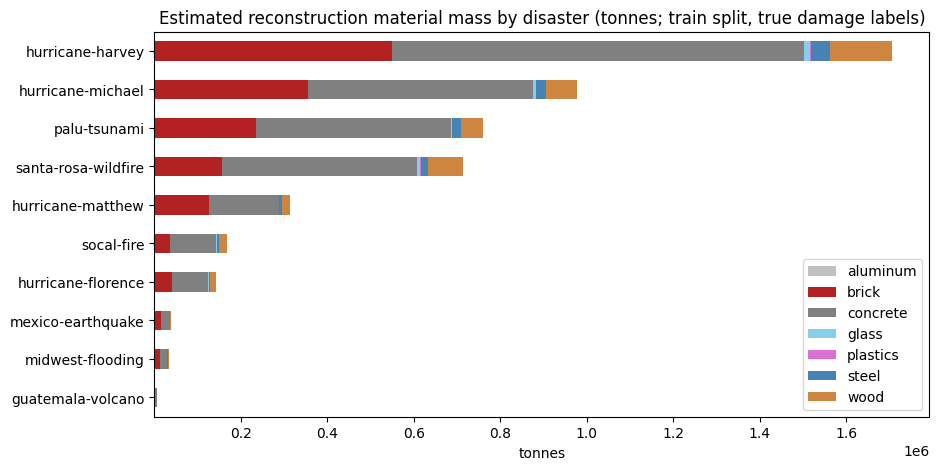

,aluminum,brick,concrete,glass,plastics,steel,wood
disaster,,,,,,,
hurricane-harvey,1327.0,548029.0,954123.0,12806.0,3248.0,42211.0,145364.0
hurricane-michael,669.0,354968.0,519847.0,6687.0,1638.0,22116.0,70962.0
palu-tsunami,506.0,234600.0,451375.0,1846.0,1238.0,20773.0,50893.0
santa-rosa-wildfire,686.0,156325.0,451185.0,6192.0,1678.0,16457.0,81571.0
hurricane-matthew,167.0,126528.0,160550.0,1516.0,409.0,6603.0,18655.0
socal-fire,161.0,36737.0,106029.0,1455.0,394.0,3867.0,19169.0
hurricane-florence,122.0,41822.0,82696.0,1166.0,299.0,3339.0,13911.0
mexico-earthquake,15.0,15109.0,20946.0,65.0,36.0,1061.0,906.0
midwest-flooding,22.0,12852.0,17167.0,228.0,54.0,664.0,2293.0


In [30]:
def add_material_mass(buildings, damage_col="damage_class", factors_table=None, rebuild_pct=None):
    """Add rebuilt area and material mass columns to a table of buildings.
    Needs columns: disaster, footprint_m2 and a damage class column."""
    factors_table = factors if factors_table is None else factors_table
    out = buildings[buildings[damage_col].isin(DAMAGE_CLASSES)].copy()
    out["rebuild_pct"] = out[damage_col].map(REBUILD_PCT if rebuild_pct is None else rebuild_pct)
    out["rebuilt_footprint_m2"] = out["footprint_m2"] * out["rebuild_pct"]
    f = factors_table.loc[out["disaster"]].set_index(out.index)   # each building's regional row
    out["rebuilt_floor_m2"] = out["rebuilt_footprint_m2"] * f["floor_m2"]
    for m in MATERIALS:
        out[f"kg_{m}"] = out["rebuilt_footprint_m2"] * f[f"kg_{m}"]
    return out


n_unclassified = (buildings_df["damage_class"] == "un-classified").sum()
est_df = add_material_mass(buildings_df)
print(f"{len(est_df):,} buildings estimated; {n_unclassified:,} un-classified buildings excluded")

# Sample table: two buildings per damage class
sample = pd.concat([est_df[est_df["damage_class"] == c].sample(2, random_state=3) for c in DAMAGE_CLASSES])
sample_cols = ["disaster", "damage_class", "footprint_m2", "rebuild_pct", "rebuilt_floor_m2"] + [f"kg_{m}" for m in MATERIALS]
display(sample[sample_cols].round({c: 0 for c in sample_cols if c != "rebuild_pct"}).reset_index(drop=True))

# Total mass per disaster, by material (tonnes)
MATERIAL_COLORS = {"concrete": "gray", "brick": "firebrick", "wood": "peru", "steel": "steelblue",
                   "glass": "skyblue", "plastics": "orchid", "aluminum": "silver", "copper": "darkorange"}
mass_by_disaster = est_df.groupby("disaster")[[f"kg_{m}" for m in MATERIALS]].sum() / 1000
mass_by_disaster.columns = MATERIALS
mass_by_disaster = mass_by_disaster.loc[mass_by_disaster.sum(axis=1).sort_values().index]
mass_by_disaster.plot(kind="barh", stacked=True, color=[MATERIAL_COLORS[m] for m in MATERIALS],
                      title="Estimated reconstruction material mass by disaster (tonnes; train split, true damage labels)")
plt.xlabel("tonnes"); plt.ylabel(""); plt.show()
mass_by_disaster.iloc[::-1].round(0)

## 6. Embodied Carbon Estimation — two independent routes

**Route A (main, auditable): RASMI × ICE.** Each material's mass from Section 5 is multiplied by its embodied carbon factor (kgCO2e per kg) from the [ICE Database Educational V5.0](https://circularecology.com/embodied-carbon-footprint-database.html) (Circular Ecology, June 2026). The factor table below lists the exact ICE entry and summary-sheet row behind each number. This route shows *which materials* the carbon comes from.

**Route B (cross-check): GEM.** GEM publishes its own embodied carbon per m² of floor for every building class. The same rebuilt floor area is multiplied by that figure. It uses a completely different method and source, so agreement between the routes is evidence the estimate is in the right range, and disagreement shows how uncertain it is.

**What these numbers are:** *embodied material carbon* of rebuilding — the emissions from producing the materials. They exclude transport, construction-site energy, demolition and waste.

**Copper is excluded.** ICE V5.0 has withdrawn its copper values, so copper cannot be given a carbon figure and is left out of the material list altogether (a decision, recorded in the log at the end of the notebook). Copper is about 0.2 kg per m² of floor, so the effect on totals is negligible.

In [31]:
ice_df = pd.read_csv(ICE_PATH)
ICE_CARBON_FACTORS = ice_df.set_index("material")["kgco2e_per_kg"]
missing_factors = [m for m in MATERIALS if pd.isna(ICE_CARBON_FACTORS.get(m))]
assert not missing_factors, f"no ICE factor for: {missing_factors}"


def add_carbon(est, factors_table=None, ice_factors=None):
    """Add embodied material carbon by both routes, in tonnes CO2e."""
    factors_table = factors if factors_table is None else factors_table
    ice_factors = ICE_CARBON_FACTORS if ice_factors is None else ice_factors
    out = est.copy()
    # Route A: sum over materials of mass x ICE factor
    out["carbon_A_tco2e"] = sum(out[f"kg_{m}"] * ice_factors[m] for m in MATERIALS if m not in missing_factors) / 1000
    # Route B: rebuilt footprint x GEM carbon per m2 of footprint
    f = factors_table.loc[out["disaster"]].set_index(out.index)
    out["carbon_B_tco2e"] = out["rebuilt_footprint_m2"] * f["gem_kgco2e"] / 1000
    return out


est_df = add_carbon(est_df)
ice_df[ice_df["material"].isin(MATERIALS)][["material", "kgco2e_per_kg", "ice_entry", "ice_summary_row", "note"]]

**Midpoint output 6 — embodied material carbon by disaster and by damage class, both routes side by side.** This is one of the two headline decision-support outputs. The ratio column shows how far the two routes disagree for each disaster.

(Training split, ground-truth damage labels.)

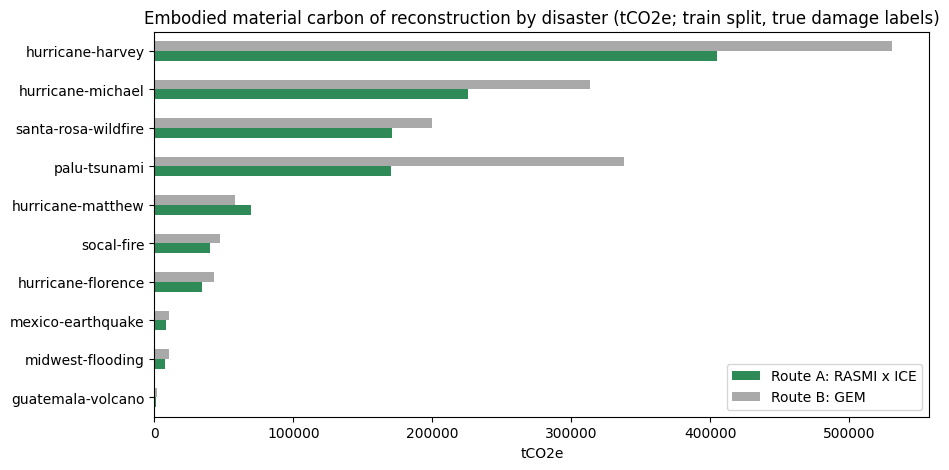

,Route A: RASMI x ICE,Route B: GEM,A / B
disaster,,,
hurricane-harvey,404730.0,531062.0,0.76
hurricane-michael,225443.0,313454.0,0.72
santa-rosa-wildfire,171149.0,199701.0,0.86
palu-tsunami,170278.0,337559.0,0.50
hurricane-matthew,69642.0,58081.0,1.20
socal-fire,40220.0,46930.0,0.86
hurricane-florence,34189.0,42923.0,0.80
mexico-earthquake,8044.0,10570.0,0.76
midwest-flooding,7553.0,10701.0,0.71


,Route A tCO2e,share_%
brick,325761.0,28.8
concrete,285968.0,25.3
steel,201638.0,17.8
wood,199057.0,17.6
aluminum,48002.0,4.2
glass,45963.0,4.1
plastics,26073.0,2.3


,buildings,carbon_A_tco2e,carbon_B_tco2e
damage_class,,,
no-damage,117426,0.0,0.0
minor-damage,14980,120358.0,151921.0
major-damage,14161,585055.0,781057.0
destroyed,13227,427049.0,620141.0


In [32]:
carbon_by_disaster = est_df.groupby("disaster")[["carbon_A_tco2e", "carbon_B_tco2e"]].sum()
carbon_by_disaster = carbon_by_disaster.sort_values("carbon_A_tco2e")
carbon_by_disaster.columns = ["Route A: RASMI x ICE", "Route B: GEM"]
carbon_by_disaster.plot(kind="barh", color=["seagreen", "darkgray"],
                        title="Embodied material carbon of reconstruction by disaster (tCO2e; train split, true damage labels)")
plt.xlabel("tCO2e"); plt.ylabel(""); plt.show()

carbon_table = carbon_by_disaster.iloc[::-1].copy()
carbon_table["A / B"] = carbon_table["Route A: RASMI x ICE"] / carbon_table["Route B: GEM"]
carbon_table.loc["ALL DISASTERS"] = [carbon_table.iloc[:, 0].sum(), carbon_table.iloc[:, 1].sum(),
                                     carbon_table.iloc[:, 0].sum() / carbon_table.iloc[:, 1].sum()]
display(carbon_table.round({"Route A: RASMI x ICE": 0, "Route B: GEM": 0, "A / B": 2}))

# Which materials drive Route A, and which damage classes drive the total
by_material = pd.Series({m: (est_df[f"kg_{m}"] * ICE_CARBON_FACTORS[m]).sum() / 1000
                         for m in MATERIALS if m not in missing_factors}).sort_values(ascending=False)
display(pd.DataFrame({"Route A tCO2e": by_material.round(0), "share_%": (100 * by_material / by_material.sum()).round(1)}))

by_damage = est_df.groupby("damage_class").agg(buildings=("uid", "size"),
                                              carbon_A_tco2e=("carbon_A_tco2e", "sum"),
                                              carbon_B_tco2e=("carbon_B_tco2e", "sum")).reindex(DAMAGE_CLASSES)
by_damage.round(0)

## 7. Building Replacement Cost (GEM)

**Source:** GEM gives the cost to construct or replace each building class per m² of floor, in US dollars, for every region. The rebuilt floor area from Section 5 is multiplied by the regional mix-weighted cost.

**What this number is:** *building replacement cost* — structural and non-structural components as built, **including labour**. It **excludes building contents** (furniture, equipment, stock), and it is a regional average per m², not a quote for any individual building. It is not an insurance loss or a total economic loss figure.

In [33]:
def add_cost(est, factors_table=None):
    """Add building replacement cost in USD (GEM regional cost per m2)."""
    factors_table = factors if factors_table is None else factors_table
    out = est.copy()
    f = factors_table.loc[out["disaster"]].set_index(out.index)
    out["replacement_cost_usd"] = out["rebuilt_footprint_m2"] * f["cost_usd"]
    return out


est_df = add_cost(est_df)

cost_summary = est_df.groupby("disaster").agg(
    buildings_damaged=("rebuild_pct", lambda x: (x > 0).sum()),
    rebuilt_floor_m2=("rebuilt_floor_m2", "sum"),
    replacement_cost_usd_million=("replacement_cost_usd", lambda x: x.sum() / 1e6),
).sort_values("replacement_cost_usd_million", ascending=False)
cost_summary["usd_per_m2_rebuilt"] = 1e6 * cost_summary["replacement_cost_usd_million"] / cost_summary["rebuilt_floor_m2"]
cost_summary.round(0)

,buildings_damaged,rebuilt_floor_m2,replacement_cost_usd_million,usd_per_m2_rebuilt
disaster,,,,
hurricane-harvey,11302,2708369.0,4692.0,1732.0
santa-rosa-wildfire,3612,1399153.0,3505.0,2505.0
hurricane-michael,7866,1365654.0,2411.0,1765.0
socal-fire,1463,328803.0,824.0,2505.0
hurricane-florence,1431,248983.0,495.0,1989.0
palu-tsunami,5538,1032266.0,282.0,273.0
hurricane-matthew,10640,341118.0,115.0,336.0
midwest-flooding,343,44750.0,77.0,1723.0
mexico-earthquake,130,29829.0,24.0,811.0


**Midpoint output 7 — replacement cost by disaster, shown alongside the carbon figure from Section 6** for direct comparison. Disasters rank differently on the two measures: rebuilding in a high-cost region is expensive per m² without being proportionally carbon-heavy, and the reverse holds where masonry and concrete dominate at low cost. That divergence is itself a result worth discussing.

(Training split, ground-truth damage labels.)

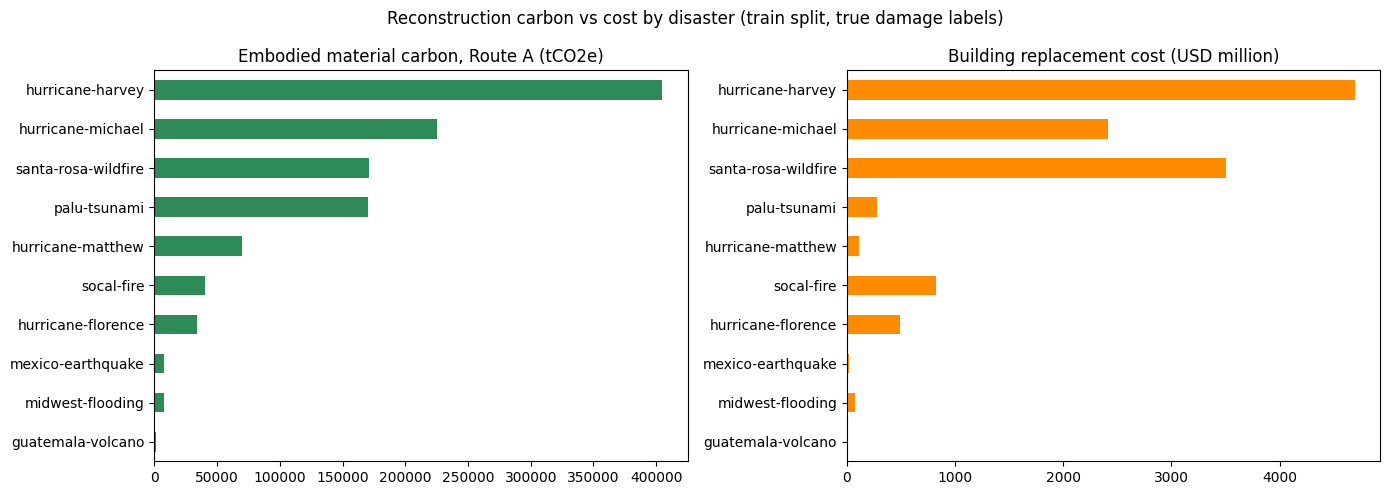

,kgCO2e per USD of rebuild
disaster,
hurricane-matthew,0.61
palu-tsunami,0.60
guatemala-volcano,0.43
mexico-earthquake,0.33
midwest-flooding,0.10
hurricane-michael,0.09
hurricane-harvey,0.09
hurricane-florence,0.07
socal-fire,0.05


In [34]:
order = est_df.groupby("disaster")["carbon_A_tco2e"].sum().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
est_df.groupby("disaster")["carbon_A_tco2e"].sum().loc[order].plot(
    kind="barh", ax=axes[0], color="seagreen", title="Embodied material carbon, Route A (tCO2e)")
(est_df.groupby("disaster")["replacement_cost_usd"].sum().loc[order] / 1e6).plot(
    kind="barh", ax=axes[1], color="darkorange", title="Building replacement cost (USD million)")
for ax in axes: ax.set_ylabel("")
plt.suptitle("Reconstruction carbon vs cost by disaster (train split, true damage labels)")
plt.tight_layout(); plt.show()

intensity = est_df.groupby("disaster")[["carbon_A_tco2e", "replacement_cost_usd"]].sum()
intensity["kgCO2e per USD of rebuild"] = 1000 * intensity["carbon_A_tco2e"] / intensity["replacement_cost_usd"]
intensity[["kgCO2e per USD of rebuild"]].sort_values("kgCO2e per USD of rebuild", ascending=False).round(2)

**Midpoint output 7b — why the damage classifier matters for these numbers.** Everything above used the true damage labels. Here the same calculation is run on the **test split** with the true labels, and then again with each model's predicted damage (the baseline from Section 3, and every Phase 3 model from Section 3c). The ratio rows show how far each model's totals are from the true-label totals: **1.00 would mean the classifier's errors cancel out and leave the estimate unchanged.** Moving this ratio towards 1 is the practical goal of Phase 3.

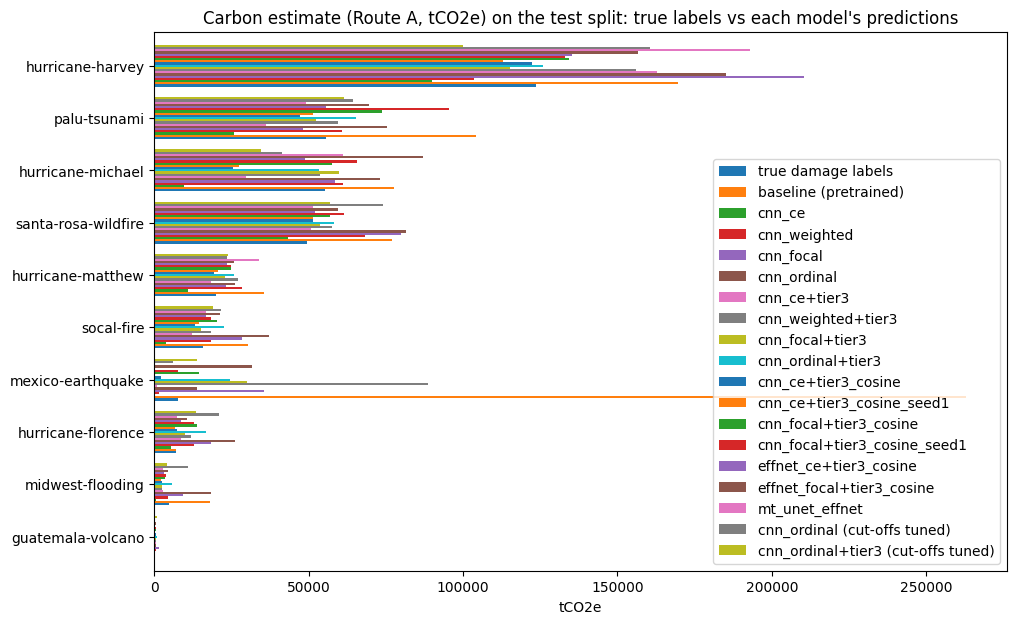

53,850 test buildings


,true damage labels,baseline (pretrained),cnn_ce,cnn_weighted,cnn_focal,cnn_ordinal,cnn_ce+tier3,cnn_weighted+tier3,cnn_focal+tier3,cnn_ordinal+tier3,cnn_ce+tier3_cosine,cnn_ce+tier3_cosine_seed1,cnn_focal+tier3_cosine,cnn_focal+tier3_cosine_seed1,effnet_ce+tier3_cosine,effnet_focal+tier3_cosine,mt_unet_effnet,cnn_ordinal (cut-offs tuned),cnn_ordinal+tier3 (cut-offs tuned)
buildings needing work,12423.0,18485.0,7029.0,16931.0,21610.0,30038.0,10983.0,16047.0,16791.0,23945.0,10322.0,10133.0,17177.0,17938.0,12164.0,17823.0,13005.0,18329.0,18567.0
rebuilt floor area (thousand m2),2239.5,4421.0,1297.0,2406.5,3381.6,3589.9,2178.2,2916.8,2325.2,2599.4,1961.1,1936.2,2621.7,2784.4,2296.5,3003.8,2752.9,2853.1,2163.0
carbon Route A (thousand tCO2e),339.4,782.4,189.3,359.9,513.5,537.5,322.8,475.9,361.9,399.2,291.5,287.6,399.5,423.2,344.0,466.6,415.6,423.7,327.6
carbon Route B (thousand tCO2e),467.9,1072.1,254.0,491.6,684.5,732.6,432.2,644.7,493.7,547.6,397.4,394.6,554.9,600.9,471.1,641.8,556.8,577.3,451.3
replacement cost (USD million),3661.8,6299.6,2254.5,4010.2,5876.5,6135.2,3742.7,4549.4,3767.1,4213.8,3266.7,3188.2,4193.6,4323.8,3782.7,4846.4,4556.1,4841.7,3500.9


,baseline (pretrained),cnn_ce,cnn_weighted,cnn_focal,cnn_ordinal,cnn_ce+tier3,cnn_weighted+tier3,cnn_focal+tier3,cnn_ordinal+tier3,cnn_ce+tier3_cosine,cnn_ce+tier3_cosine_seed1,cnn_focal+tier3_cosine,cnn_focal+tier3_cosine_seed1,effnet_ce+tier3_cosine,effnet_focal+tier3_cosine,mt_unet_effnet,cnn_ordinal (cut-offs tuned),cnn_ordinal+tier3 (cut-offs tuned)
buildings needing work: predicted / true,1.49,0.57,1.36,1.74,2.42,0.88,1.29,1.35,1.93,0.83,0.82,1.38,1.44,0.98,1.43,1.05,1.48,1.49
rebuilt floor area (thousand m2): predicted / true,1.97,0.58,1.07,1.51,1.60,0.97,1.30,1.04,1.16,0.88,0.86,1.17,1.24,1.03,1.34,1.23,1.27,0.97
carbon Route A (thousand tCO2e): predicted / true,2.31,0.56,1.06,1.51,1.58,0.95,1.40,1.07,1.18,0.86,0.85,1.18,1.25,1.01,1.37,1.22,1.25,0.97
carbon Route B (thousand tCO2e): predicted / true,2.29,0.54,1.05,1.46,1.57,0.92,1.38,1.06,1.17,0.85,0.84,1.19,1.28,1.01,1.37,1.19,1.23,0.96
replacement cost (USD million): predicted / true,1.72,0.62,1.10,1.60,1.68,1.02,1.24,1.03,1.15,0.89,0.87,1.15,1.18,1.03,1.32,1.24,1.32,0.96


In [35]:
# test_buildings_df (one row per test building, with footprint) was built in Section 3b
def reconstruction_totals(buildings, damage_col):
    est = add_cost(add_carbon(add_material_mass(buildings, damage_col=damage_col)))
    return pd.Series({
        "buildings needing work": (est["rebuild_pct"] > 0).sum(),
        "rebuilt floor area (thousand m2)": est["rebuilt_floor_m2"].sum() / 1e3,
        "carbon Route A (thousand tCO2e)": est["carbon_A_tco2e"].sum() / 1e3,
        "carbon Route B (thousand tCO2e)": est["carbon_B_tco2e"].sum() / 1e3,
        "replacement cost (USD million)": est["replacement_cost_usd"].sum() / 1e6,
    })


test_labelled = test_buildings_df[test_buildings_df["damage_class"].isin(DAMAGE_CLASSES)]
propagation = pd.DataFrame({"true damage labels": reconstruction_totals(test_labelled, "damage_class")})
carbon_by_model = {"true damage labels": add_carbon(add_material_mass(test_labelled)).groupby("disaster")["carbon_A_tco2e"].sum()}
for name, preds in model_predictions.items():
    with_pred = test_labelled.merge(preds[["file", "uid", "pred_class"]], on=["file", "uid"], how="inner")
    assert len(with_pred) == len(test_labelled), f"{name}: predictions missing for some test buildings"
    propagation[name] = reconstruction_totals(with_pred, "pred_class")
    carbon_by_model[name] = add_carbon(add_material_mass(with_pred, "pred_class")).groupby("disaster")["carbon_A_tco2e"].sum()

per_disaster = pd.DataFrame(carbon_by_model).sort_values("true damage labels")
per_disaster.plot(kind="barh", figsize=(11, 7), width=0.8,
                  title="Carbon estimate (Route A, tCO2e) on the test split: true labels vs each model's predictions")
plt.xlabel("tCO2e"); plt.ylabel(""); plt.show()

print(f"{len(test_labelled):,} test buildings")
display(propagation.round(1))
ratios = propagation.drop(columns="true damage labels").div(propagation["true damage labels"], axis=0)
ratios.round(2).rename(index=lambda r: f"{r}: predicted / true")

**Midpoint output 7c — headline totals under both floor-area methods.** How much floor each damaged building has is the assumption the totals are most sensitive to (Section 9b), and there are two defensible ways to get it. **Both are reported; neither is treated as the single answer.**

| Method | Floor area of a building | Strength | Weakness |
|---|---|---|---|
| Measured footprint | Its own outline in the xBD labels × the regional average storeys from GEM | Uses what is actually seen; a large building counts as large | xBD outlines trace roofs, which overhang walls, and the labelled areas are not a random sample of the region |
| GEM average size | Every building gets its region's average GEM floor area | Consistent with the source of the cost and carbon rates | Ignores the building's real size completely |

(Training split, ground-truth damage labels.)

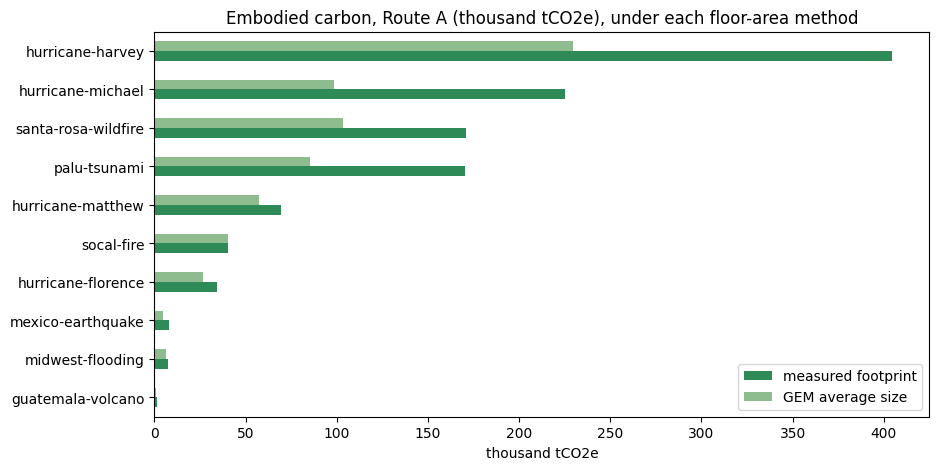

carbon_A_ktco2e                     carbon_B_ktco2e  \
                    measured footprint GEM average size measured footprint   
disaster                                                                     
hurricane-harvey                 404.7            229.6              531.1   
hurricane-michael                225.4             98.7              313.5   
santa-rosa-wildfire              171.1            103.4              199.7   
palu-tsunami                     170.3             85.1              337.6   
hurricane-matthew                 69.6             57.1               58.1   
socal-fire                        40.2             40.3               46.9   
hurricane-florence                34.2             26.5               42.9   
mexico-earthquake                  8.0              4.7               10.6   
midwest-flooding                   7.6              6.4               10.7   
guatemala-volcano                  1.2              0.9                2.1   
ALL DISASTERS                   1132.5            652.7             1553.1   

                                       cost_usd_million                   
                    GEM average size measured footprint GEM average size  
disaster                                                                  
hurricane-harvey               301.2             4692.2           2661.3  
hurricane-michael              137.3             2410.8           1056.0  
santa-rosa-wildfire            120.6             3505.4           2117.2  
palu-tsunami                   168.7              282.0            141.0  
hurricane-matthew               47.6              114.7             94.1  
socal-fire                      47.0              823.8            825.1  
hurricane-florence              33.3              495.3            384.2  
mexico-earthquake                6.2               24.2             14.2  
midwest-flooding                 9.0               77.1             65.0  
guatemala-volcano                1.5                2.8              2.0  
ALL DISASTERS                  872.5            12428.2           7360.0

In [36]:
FLOOR_AREA_METHODS = {
    "measured footprint": buildings_df,
    "GEM average size": buildings_df.assign(
        footprint_m2=buildings_df["disaster"].map(size_check["GEM implied mean footprint m2"])),
}

both = {}
for method, table in FLOOR_AREA_METHODS.items():
    est = add_cost(add_carbon(add_material_mass(table)))
    both[method] = est.groupby("disaster").agg(
        carbon_A_ktco2e=("carbon_A_tco2e", lambda x: x.sum() / 1e3),
        carbon_B_ktco2e=("carbon_B_tco2e", lambda x: x.sum() / 1e3),
        cost_usd_million=("replacement_cost_usd", lambda x: x.sum() / 1e6))
headline = pd.concat(both, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
headline = headline.sort_values(("carbon_A_ktco2e", "measured footprint"), ascending=False)
headline.loc["ALL DISASTERS"] = headline.sum()

headline["carbon_A_ktco2e"].iloc[:-1][::-1].plot(
    kind="barh", color=["seagreen", "darkseagreen"],
    title="Embodied carbon, Route A (thousand tCO2e), under each floor-area method")
plt.xlabel("thousand tCO2e"); plt.ylabel(""); plt.show()
headline.round(1)

## 8. Hold-out Evaluation: the protocol

The `hold/` split (933 tiles, 10 disasters) has not been opened at any point in this project. It is used **once**, in Section 10 at the end of the notebook (it has to run there, after the pipeline code of Section 9 is defined). Everything it depends on was fixed beforehand using `train`, `tier3`, `validation` and `test` only:

| Frozen choice | Value | How it was chosen |
|---|---|---|
| Damage model | `effnet_ce+tier3_cosine` (pretrained EfficientNetB0 encoder, plain cross-entropy, cosine schedule, train + tier3) | highest **validation** macro F1 of 15 trained models (Section 3c) |
| Building finder for the automatic pipeline | multi-task U-Net building map (Section 3c-ii) | higher building recall than the baseline U-Net on test (0.83 vs 0.70) |
| Splitting touching buildings | watershed, minimum seed separation chosen on **validation** (Section 9d) | lowest typical per-disaster carbon error on validation |
| Construction type | Layer 1 (GEM regional mix) | Layer 2 did not beat a no-image guess (Section 4b) |
| All assumption tables | rebuild %, GEM→RASMI mapping, multi-family rule, ICE factors, RASMI median, floor area = footprint × GEM storeys | stated in Sections 4-7; varied in the sensitivity analysis (Section 9b) |

**What Section 10 measures:**
1. **Damage:** the final damage model and the original baseline, on the surveyed building outlines, with the same scores as Section 3.
2. **Finding buildings:** the baseline U-Net and the multi-task U-Net, pixel by pixel against the surveyed outlines, as in Section 2.
3. **Carbon and cost:** totals per disaster in four versions (true labels; surveyed outlines + model damage; fully automatic; fully automatic with splitting), as in Section 9d.

**The rule:** whatever Section 10 shows is reported as it is. Nothing above is changed in response to it; otherwise the hold-out would stop being an honest test.

In [37]:
# The hold-out evaluation itself is in Section 10, at the end of the notebook.
print("Hold-out protocol only. See Section 10 for the one-off run.")

Hold-out protocol only. See Section 10 for the one-off run.


## 9. Decision-Support Dashboard & Sensitivity Analysis

**This section exists to make the notebook "performative" rather than a one-shot report** — the two things below are what someone would actually re-run to inform a real decision.

**9a. Cross-disaster summary table** — buildings damaged, embodied carbon (both routes), replacement cost, side by side, so disasters can be compared directly. Shown for the test split, with the true damage labels beside the selected model's predictions, so a reader sees both the estimate and how far the model moves it for each disaster. A total that matches overall can hide disasters that are over- and under-estimated, which this table exposes.

**9b. Sensitivity analysis** — the whole downstream calculation is rerun with one assumption changed at a time, to show how much the totals move. This is important intellectual honesty: it tells you (and a reader) how much to trust the headline figures, and which assumption matters most. The scenarios:

| Scenario | What changes | Why it is plausible |
|---|---|---|
| Rebuild % −20% / +20% | Every rebuild percentage scaled (capped at 100%) | The percentages are assumed, not measured |
| RASMI 25th / 75th percentile | Material intensity low / high instead of the median | RASMI publishes a range, not one value |
| GEM "other" class as masonry | Mobile homes / informal housing treated as masonry instead of timber | The mapping for this class is a judgement call |
| Floor area from GEM averages | Every building gets its region's average GEM floor area instead of measured footprint × storeys | xBD footprints are larger than GEM's regional average (Section 4 size check) |
| Timber with carbon storage | ICE's timber factor *including* the carbon stored in the wood (a negative number) instead of the one excluding it | Valid only if the timber is sustainably sourced |

Run on the training split with true damage labels, so the only thing varying is the assumption.

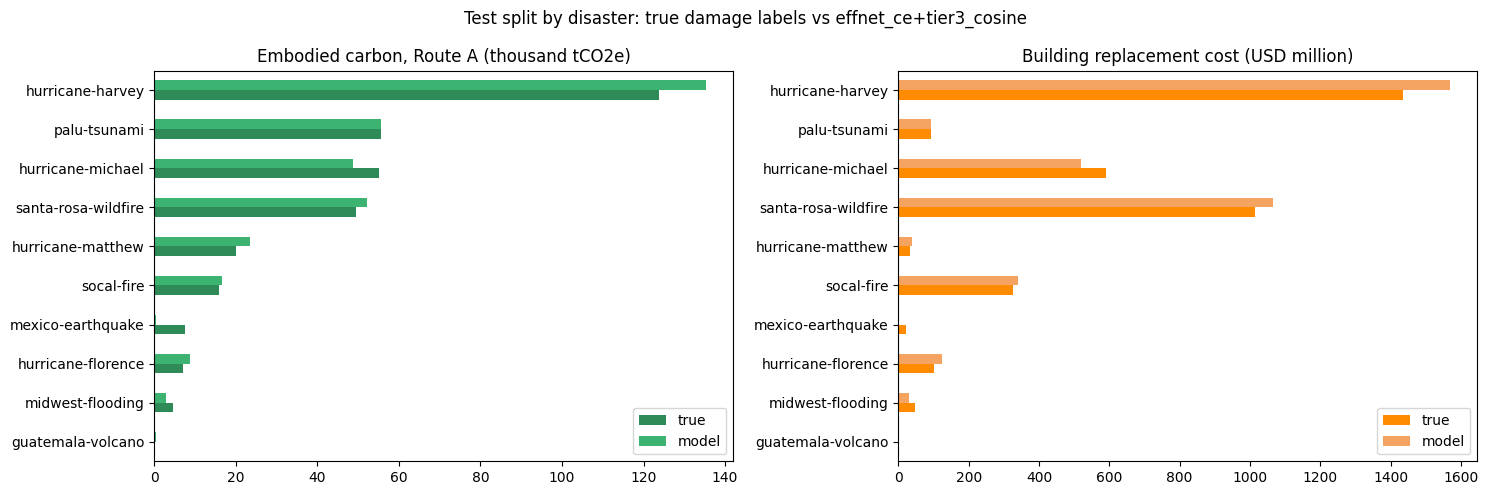

Model: effnet_ce+tier3_cosine | floor area: measured footprint x GEM storeys


buildings needing_work          carbon_A_ktco2e          \
                                      true    model            true   model   
disaster                                                                      
hurricane-harvey       7609.0       3441.0   3323.0          123.71  135.26   
palu-tsunami          12414.0       1487.0   1537.0           55.60   55.57   
hurricane-michael      5602.0       1955.0   1683.0           55.22   48.63   
santa-rosa-wildfire    4214.0        992.0   1059.0           49.53   52.07   
hurricane-matthew      3971.0       3354.0   3496.0           20.03   23.56   
socal-fire             4102.0        519.0    512.0           15.91   16.58   
mexico-earthquake     11400.0        116.0     16.0            7.64    0.29   
hurricane-florence     2117.0        441.0    457.0            6.99    8.67   
midwest-flooding       2391.0        114.0     73.0            4.62    2.98   
guatemala-volcano        30.0          4.0      8.0            0.10    0.37   
ALL TEST DISASTERS    53850.0      12423.0  12164.0          339.36  343.97   

                    carbon_B_ktco2e         cost_usd_million           \
                               true   model             true    model   
disaster                                                                
hurricane-harvey             162.32  177.48          1434.17  1568.09   
palu-tsunami                 110.23  110.16            92.09    92.04   
hurricane-michael             76.78   67.62           590.48   520.07   
santa-rosa-wildfire           57.80   60.75          1014.54  1066.42   
hurricane-matthew             16.71   19.65            32.99    38.79   
socal-fire                    18.57   19.35           325.90   339.61   
mexico-earthquake             10.03    0.39            22.97     0.88   
hurricane-florence             8.78   10.88           101.30   125.59   
midwest-flooding               6.54    4.22            47.13    30.38   
guatemala-volcano              0.18    0.64             0.24     0.85   
ALL TEST DISASTERS           467.93  471.14          3661.82  3782.73   

                        carbon_A  
                    model / true  
disaster                          
hurricane-harvey            1.09  
palu-tsunami                1.00  
hurricane-michael           0.88  
santa-rosa-wildfire         1.05  
hurricane-matthew           1.18  
socal-fire                  1.04  
mexico-earthquake           0.04  
hurricane-florence          1.24  
midwest-flooding            0.64  
guatemala-volcano           3.59  
ALL TEST DISASTERS          1.01

In [38]:
# 9a - cross-disaster summary on the TEST split, using the model selected in Section 3c.
# "true" columns use the ground-truth damage labels; "model" columns use the model's predictions.
def disaster_summary(buildings, damage_col):
    est = add_cost(add_carbon(add_material_mass(buildings, damage_col=damage_col)))
    return est.groupby("disaster").agg(
        buildings=("uid", "size"),
        needing_work=("rebuild_pct", lambda x: (x > 0).sum()),
        carbon_A_ktco2e=("carbon_A_tco2e", lambda x: x.sum() / 1e3),
        carbon_B_ktco2e=("carbon_B_tco2e", lambda x: x.sum() / 1e3),
        cost_usd_million=("replacement_cost_usd", lambda x: x.sum() / 1e6))

with_selected = test_labelled.merge(selected_preds[["file", "uid", "pred_class"]], on=["file", "uid"], how="inner")
dashboard = pd.concat({"true": disaster_summary(with_selected, "damage_class"),
                       "model": disaster_summary(with_selected, "pred_class")}, axis=1)
dashboard = dashboard.swaplevel(axis=1)[[(m, s) for m in ["needing_work", "carbon_A_ktco2e", "carbon_B_ktco2e", "cost_usd_million"]
                                         for s in ["true", "model"]]]
dashboard.insert(0, "buildings", disaster_summary(with_selected, "damage_class")["buildings"])
dashboard = dashboard.sort_values(("carbon_A_ktco2e", "true"), ascending=False)
dashboard.loc["ALL TEST DISASTERS"] = dashboard.sum()
dashboard[("carbon_A", "model / true")] = dashboard[("carbon_A_ktco2e", "model")] / dashboard[("carbon_A_ktco2e", "true")]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dashboard[["carbon_A_ktco2e"]].iloc[:-1][::-1].droplevel(0, axis=1).plot(
    kind="barh", ax=axes[0], color=["seagreen", "mediumseagreen"], title="Embodied carbon, Route A (thousand tCO2e)")
dashboard[["cost_usd_million"]].iloc[:-1][::-1].droplevel(0, axis=1).plot(
    kind="barh", ax=axes[1], color=["darkorange", "sandybrown"], title="Building replacement cost (USD million)")
for ax in axes: ax.set_ylabel("")
plt.suptitle(f"Test split by disaster: true damage labels vs {selected_model_name}")
plt.tight_layout(); plt.show()

print("Model:", selected_model_name, "| floor area: measured footprint x GEM storeys")
dashboard.round(2)

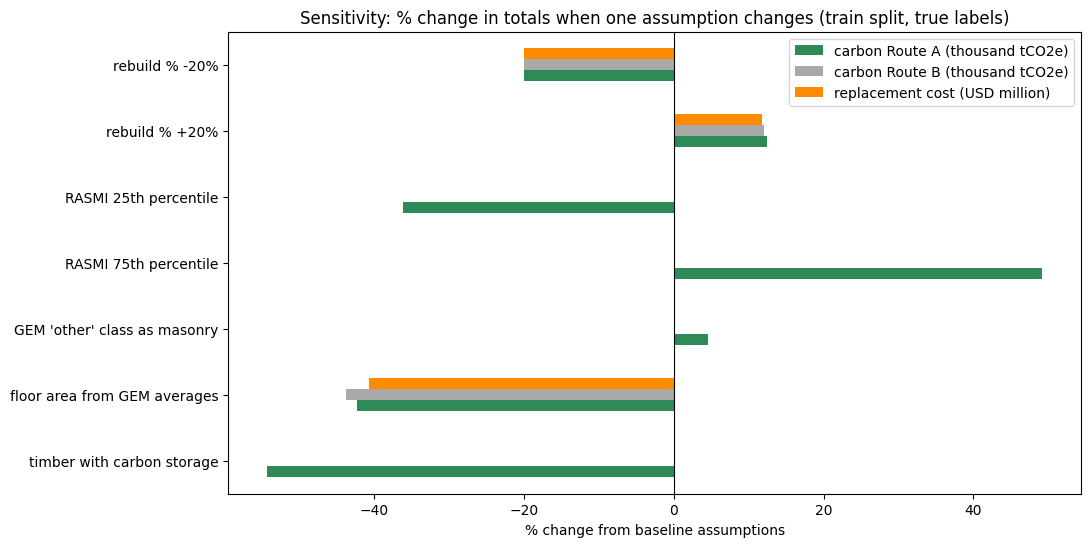

,carbon Route A (thousand tCO2e),carbon Route B (thousand tCO2e),replacement cost (USD million)
baseline assumptions,1132.0,1553.0,12428.0
rebuild % -20%,906.0,1242.0,9943.0
rebuild % +20%,1274.0,1740.0,13901.0
RASMI 25th percentile,722.0,1553.0,12428.0
RASMI 75th percentile,1690.0,1553.0,12428.0
GEM 'other' class as masonry,1184.0,1553.0,12428.0
floor area from GEM averages,653.0,873.0,7360.0
timber with carbon storage,517.0,1553.0,12428.0


,carbon Route A (thousand tCO2e) % change,carbon Route B (thousand tCO2e) % change,replacement cost (USD million) % change
rebuild % -20%,-20.0,-20.0,-20.0
rebuild % +20%,12.5,12.0,11.8
RASMI 25th percentile,-36.3,0.0,0.0
RASMI 75th percentile,49.2,0.0,0.0
GEM 'other' class as masonry,4.5,0.0,0.0
floor area from GEM averages,-42.4,-43.8,-40.8
timber with carbon storage,-54.3,0.0,0.0


In [39]:
def scenario_totals(buildings=None, **changes):
    """Totals for one scenario. `changes` may contain: rebuild_pct, intensity_col, classes, ice_factors."""
    buildings = buildings_df if buildings is None else buildings
    f = regional_factors(changes.get("intensity_col", "intensity_kg_per_m2"), classes=changes.get("classes"))
    est = add_material_mass(buildings, factors_table=f, rebuild_pct=changes.get("rebuild_pct"))
    est = add_cost(add_carbon(est, factors_table=f, ice_factors=changes.get("ice_factors")), factors_table=f)
    return pd.Series({
        "carbon Route A (thousand tCO2e)": est["carbon_A_tco2e"].sum() / 1e3,
        "carbon Route B (thousand tCO2e)": est["carbon_B_tco2e"].sum() / 1e3,
        "replacement cost (USD million)": est["replacement_cost_usd"].sum() / 1e6,
    })


# Alternative assumptions
other_as_masonry = region_classes.copy()
other_as_masonry.loc[other_as_masonry["macro_taxonomy"] == "OT", "rasmi_structure"] = "M"

gem_mean_footprint = size_check["GEM implied mean footprint m2"]            # from Section 4
gem_sized_buildings = buildings_df.assign(footprint_m2=buildings_df["disaster"].map(gem_mean_footprint))

timber_with_storage = ICE_CARBON_FACTORS.copy()
# ICE 'Timber - Average of all data - Including Carbon Storage' (built by tools/build_ice_factors.py)
timber_with_storage["wood"] = ICE_CARBON_FACTORS["wood_with_carbon_storage"]

scenarios = {
    "baseline assumptions": {},
    "rebuild % -20%": {"rebuild_pct": {k: v * 0.8 for k, v in REBUILD_PCT.items()}},
    "rebuild % +20%": {"rebuild_pct": {k: min(v * 1.2, 1.0) for k, v in REBUILD_PCT.items()}},
    "RASMI 25th percentile": {"intensity_col": "p25_kg_per_m2"},
    "RASMI 75th percentile": {"intensity_col": "p75_kg_per_m2"},
    "GEM 'other' class as masonry": {"classes": other_as_masonry},
    "floor area from GEM averages": {"buildings": gem_sized_buildings},
    "timber with carbon storage": {"ice_factors": timber_with_storage},
}
sensitivity = pd.DataFrame({name: scenario_totals(**changes) for name, changes in scenarios.items()}).T
pct_change = (100 * (sensitivity / sensitivity.loc["baseline assumptions"] - 1)).iloc[1:]

pct_change.iloc[::-1].plot(kind="barh", figsize=(11, 6), color=["seagreen", "darkgray", "darkorange"],
                           title="Sensitivity: % change in totals when one assumption changes (train split, true labels)")
plt.axvline(0, color="black", linewidth=0.8); plt.xlabel("% change from baseline assumptions"); plt.show()

display(sensitivity.round(0))
pct_change.round(1).add_suffix(" % change")

**9c. Does it matter which buildings get which construction type?** The three allocation methods from Section 4c are run through the same materials, carbon and cost calculation. All three give every region the same GEM mix by count; they differ only in *which* buildings are treated as timber, masonry, concrete or steel. Because larger buildings need more material, moving the heavy types onto larger or smaller buildings changes the totals.

The first line printed is a self-check: the Layer 1 column, computed here building by building, must reproduce the Section 6 total exactly.

(Training split, ground-truth damage labels. Layer 1 remains the headline method; the other two are shown as alternatives.)

Self-check: Layer 1 rebuilt here gives 1,132,462 tCO2e; Section 6 gave 1,132,462 tCO2e


,Layer 1 (regional mix),Size-adjusted Layer 1,Layer 2 (CNN)
carbon Route A (thousand tCO2e),1132.0,1382.0,1126.0
carbon Route B (thousand tCO2e),1553.0,1878.0,1540.0
replacement cost (USD million),12428.0,13125.0,12416.0


,Size-adjusted Layer 1: % change vs Layer 1,Layer 2 (CNN): % change vs Layer 1
carbon Route A (thousand tCO2e),22.1,-0.6
carbon Route B (thousand tCO2e),20.9,-0.9
replacement cost (USD million),5.6,-0.1


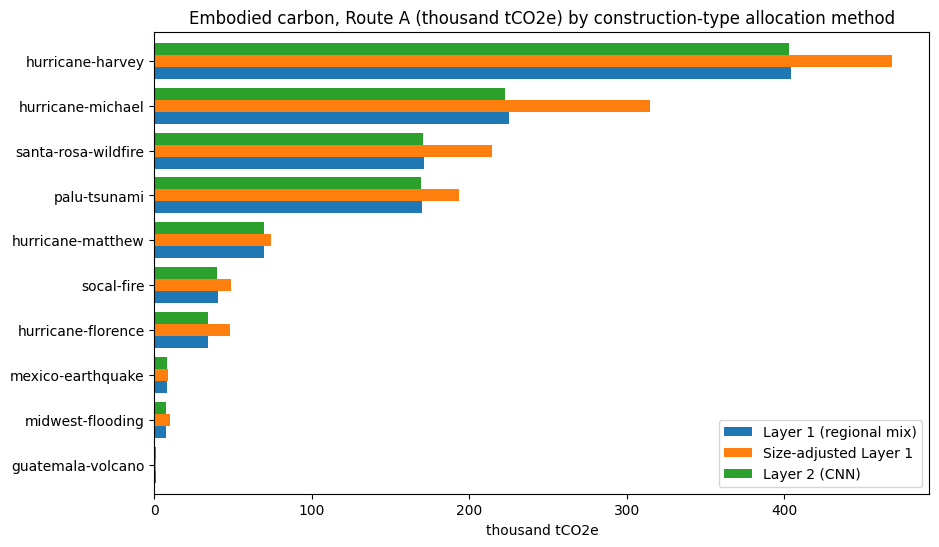

,Size-adjusted Layer 1: % change vs Layer 1,Layer 2 (CNN): % change vs Layer 1
disaster,,
hurricane-harvey,15.8,-0.5
hurricane-michael,39.5,-1.3
santa-rosa-wildfire,25.2,-0.4
palu-tsunami,13.6,-0.4
hurricane-matthew,6.7,-0.3
socal-fire,21.2,-0.3
hurricane-florence,40.9,-0.8
mexico-earthquake,9.4,-0.0
midwest-flooding,34.6,-0.9


In [40]:
def structure_factors():
    """Like regional_factors(), but one row per (disaster, structure type): what 1 m2 of footprint
    means GIVEN the building is of that type. GEM's split of classes inside each type is kept."""
    c = region_classes.copy()
    c["w"] = c["share_of_buildings"] / c.groupby(["disaster", "rasmi_structure"])["share_of_buildings"].transform("sum")
    c["floor_m2"] = c["w"] * c["avg_storeys"]
    c["gem_kgco2e"] = c["floor_m2"] * c["gem_kgco2e_per_m2"]
    c["cost_usd"] = c["floor_m2"] * c["cost_usd_per_m2"]
    other = c.groupby(["disaster", "rasmi_structure"])[["floor_m2", "gem_kgco2e", "cost_usd"]].sum()
    with_rasmi = c.merge(rasmi_df[rasmi_df["material"].isin(MATERIALS)], how="left",
                         left_on=["rasmi_region", "rasmi_structure", "rasmi_function"],
                         right_on=["region", "structural_type", "functional_type"])
    with_rasmi["kg"] = with_rasmi["floor_m2"] * with_rasmi["intensity_kg_per_m2"]
    materials = with_rasmi.pivot_table(index=["disaster", "rasmi_structure"], columns="material", values="kg", aggfunc="sum").add_prefix("kg_")
    return other.join(materials)


type_factors = structure_factors()
labelled_train = buildings_df[buildings_df["damage_class"].isin(DAMAGE_CLASSES)][["file", "uid", "disaster", "damage_class", "footprint_m2"]]


def totals_with_allocation(probs):
    """Carbon and cost when each building has its OWN structure probabilities (array aligned with pool_meta)."""
    p = pd.concat([pool_meta[["file", "uid"]], pd.DataFrame(probs, columns=[f"P_{s}" for s in STRUCTURES])], axis=1)
    b = labelled_train.merge(p, on=["file", "uid"], how="inner")
    assert len(b) == len(labelled_train) and b[[f"P_{s}" for s in STRUCTURES]].notna().all().all()
    rebuilt = (b["footprint_m2"] * b["damage_class"].map(REBUILD_PCT)).to_numpy()
    per_footprint = sum(b[f"P_{s}"].to_numpy()[:, None] *
                        type_factors.reindex(pd.MultiIndex.from_arrays([b["disaster"], [s] * len(b)])).fillna(0).to_numpy()
                        for s in STRUCTURES)
    per_building = pd.DataFrame(per_footprint * rebuilt[:, None], columns=type_factors.columns)
    return pd.DataFrame({
        "disaster": b["disaster"].to_numpy(),
        "carbon_A_tco2e": sum(per_building[f"kg_{m}"] * ICE_CARBON_FACTORS[m] for m in MATERIALS) / 1000,
        "carbon_B_tco2e": per_building["gem_kgco2e"] / 1000,
        "replacement_cost_usd": per_building["cost_usd"],
    })


by_method = {name: totals_with_allocation(probs) for name, probs in ALLOCATIONS.items()}
layer1_total = by_method["Layer 1 (regional mix)"]["carbon_A_tco2e"].sum()
print(f"Self-check: Layer 1 rebuilt here gives {layer1_total:,.0f} tCO2e; Section 6 gave {est_df['carbon_A_tco2e'].sum():,.0f} tCO2e")
assert np.isclose(layer1_total, est_df["carbon_A_tco2e"].sum(), rtol=1e-4)

allocation_totals = pd.DataFrame({name: pd.Series({
    "carbon Route A (thousand tCO2e)": t["carbon_A_tco2e"].sum() / 1e3,
    "carbon Route B (thousand tCO2e)": t["carbon_B_tco2e"].sum() / 1e3,
    "replacement cost (USD million)": t["replacement_cost_usd"].sum() / 1e6}) for name, t in by_method.items()})
display(allocation_totals.round(0))
display((100 * (allocation_totals.div(allocation_totals["Layer 1 (regional mix)"], axis=0) - 1))
        .drop(columns="Layer 1 (regional mix)").round(1).add_suffix(": % change vs Layer 1"))

carbon_by_disaster_alloc = pd.DataFrame({name: t.groupby("disaster")["carbon_A_tco2e"].sum() / 1e3 for name, t in by_method.items()})
carbon_by_disaster_alloc = carbon_by_disaster_alloc.sort_values("Layer 1 (regional mix)")
carbon_by_disaster_alloc.plot(kind="barh", figsize=(10, 6), width=0.8,
                              title="Embodied carbon, Route A (thousand tCO2e) by construction-type allocation method")
plt.xlabel("thousand tCO2e"); plt.ylabel(""); plt.show()
(100 * (carbon_by_disaster_alloc.div(carbon_by_disaster_alloc["Layer 1 (regional mix)"], axis=0) - 1)).iloc[::-1] \
    .drop(columns="Layer 1 (regional mix)").round(1).add_suffix(": % change vs Layer 1")

**9d. The prototype: the finished pipeline, run with no human help.** Everything above that used a trained model was given the *ground-truth building outlines*. A real user has none. The prototype (`prototype.ipynb`, built on the module `xbd_pipeline.py`) therefore combines the two best parts found in Phase 3:

| Step | Model | Why this one |
|---|---|---|
| Find buildings | the **multi-task U-Net**'s building map (Section 3c-ii), split into separate buildings | finds 83% of building pixels, against 70% for the baseline U-Net |
| Judge damage | the **pretrained crop classifier** `effnet_ce+tier3_cosine` (Section 3c) | best damage model (test macro F1 0.758, against 0.667 for the multi-task model) |
| Materials, carbon, cost | Layer 1 regional mix, RASMI, ICE, GEM (Sections 4-7) | the transparent headline calculation |

This cell does two things:

1. **Checks that the module reproduces this notebook.** Its carbon and cost totals for the training split must equal Section 6/7 exactly, and its damage model must give the same answers as Section 3c on the same buildings.
2. **Runs the whole pipeline automatically on every test tile** and compares its totals with the true-label figures. Two new kinds of error now enter: buildings that are missed or invented, and **touching buildings that are found as one blob** (the building map marks *pixels*, so neighbours that touch are not separated). Footprints come from the predicted map (pixels × 0.47 m × 0.47 m) instead of the surveyed outlines.

Three versions of the test-split totals are compared, so each source of error can be seen on its own:
- **true:** surveyed outlines, true damage labels (the reference);
- **assisted:** surveyed outlines, the model's damage (the Section 9a figure);
- **automatic:** the model finds the buildings *and* judges their damage (what the prototype does).

In [41]:
import importlib, sys
sys.path.insert(0, str(Path(".").resolve()))
import xbd_pipeline as xp
importlib.reload(xp)

# --- 1. does the module reproduce this notebook? ------------------------------------
module_totals = {"carbon_A_tco2e": 0.0, "carbon_B_tco2e": 0.0, "replacement_cost_usd": 0.0}
for disaster, group in buildings_df[buildings_df["damage_class"].isin(DAMAGE_CLASSES)].groupby("disaster"):
    e = xp.estimate(group, xp.region_factors(*xp.DISASTER_REGION[disaster]))
    for k in module_totals:
        module_totals[k] += e[k].sum()
consistency = pd.DataFrame({"this notebook (Sections 6-7)": est_df[list(module_totals)].sum(), "xbd_pipeline module": pd.Series(module_totals)})
consistency["difference %"] = 100 * (consistency.iloc[:, 1] / consistency.iloc[:, 0] - 1)
display(consistency.round(3))
assert (consistency["difference %"].abs() < 0.01).all(), "module and notebook disagree"

finder, damage_model = xp.load_models()
check = model_predictions[xp.DAMAGE_MODEL_WEIGHTS.name.replace("p3_", "").split("_20ep")[0]] \
    .merge(baseline_cls_df[["file", "uid", "wkt"]], on=["file", "uid"]).groupby("file").head(30).head(1500)
same = []
for file, g in check.groupby("file"):
    before = xp.load_image(TEST_DIR / "images" / f"{file.replace('_post_', '_pre_')}.png")
    after = xp.load_image(TEST_DIR / "images" / f"{file}.png")
    boxes = pd.DataFrame([dict(zip(["x0", "y0", "x1", "y1"], wkt.loads(w).bounds)) for w in g["wkt"]])
    same += list(np.array(xp.judge_damage(damage_model, before, after, boxes)) == g["pred_class"].to_numpy())
print(f"Damage model in the module gives the same answer as Section 3c for {np.mean(same):.1%} of {len(same)} test buildings")

,this notebook (Sections 6-7),xbd_pipeline module,difference %
carbon_A_tco2e,1.132462e+06,1.132462e+06,0.0
carbon_B_tco2e,1.553119e+06,1.553119e+06,0.0
replacement_cost_usd,1.242824e+10,1.242824e+10,0.0


Damage model in the module gives the same answer as Section 3c for 100.0% of 1500 test buildings


**Splitting touching buildings (tuned on validation).** A first automatic run on the test split over-estimated carbon about 1.8 times, and the cause was clear: the building map marks *pixels*, so neighbouring buildings that touch join into one large patch (up to 100,000 m² in Mexico City), and if any part of that patch looks damaged, the whole patch is treated as rebuilt. The damage model was not at fault: with the surveyed outlines it was within 1%.

The fix is a **watershed**, a standard image-processing step that needs no training. For each building pixel, measure how far it is to the nearest non-building pixel: that distance is largest in the middle of a building and dips at the narrow neck where two buildings touch. The highest points become seeds, and each patch is shared out between its seeds along the dips. One setting controls it: **how far apart two seeds must be** (in pixels). Too small, and single buildings get cut up; too large, and touching buildings stay merged.

**How the setting is chosen, without touching the test split.** Each candidate is run on the 224 **validation tiles** (from the training split, never trained on), and its carbon estimate is compared with the true-label figure for each disaster. The score is the average size of the error *disaster by disaster* (measured as a factor, so 2× too high and 2× too low count equally), because an overall total can look right while every disaster is wrong. The best setting is then used once on the test split below.

In [42]:
SPLIT_CANDIDATES = [None, 3, 5, 8, 12, 16]   # minimum seed separation in pixels; None = no splitting


def totals(table, damage_col):
    """Per-disaster totals of buildings, buildings needing work, carbon (RASMI x ICE) and cost."""
    out = []
    for disaster, group in table.groupby("disaster"):
        e = xp.estimate(group, xp.region_factors(*xp.DISASTER_REGION[disaster]), damage_col=damage_col)
        out.append({"disaster": disaster, "buildings": len(e), "needing work": int((e["rebuild_pct"] > 0).sum()),
                    "carbon A (kt)": e["carbon_A_tco2e"].sum() / 1e3, "cost (USD m)": e["replacement_cost_usd"].sum() / 1e6})
    return pd.DataFrame(out).set_index("disaster")


validation_truth = train_meta[train_meta["subset"] == "validation"]
validation_files = sorted(validation_truth["file"].unique())

# Building masks for the validation tiles: the slow part (the network), done once and cached
mask_path = OUTPUT_DIR / "e2e_validation_masks.npz"
if mask_path.exists():
    stored = np.load(mask_path)
    validation_masks = {f: np.unpackbits(stored[f])[:1024 * 1024].reshape(1024, 1024).astype(bool) for f in validation_files}
else:
    validation_masks = {}
    for file in validation_files:
        before = xp.load_image(TRAIN_DIR / "images" / f"{file.replace('_post_', '_pre_')}.png")
        validation_masks[file] = xp.building_mask(finder, before, xp.load_image(TRAIN_DIR / "images" / f"{file}.png"))
    np.savez_compressed(mask_path, **{f: np.packbits(m) for f, m in validation_masks.items()})

found = {sep: [] for sep in SPLIT_CANDIDATES}
for file in validation_files:
    before = xp.load_image(TRAIN_DIR / "images" / f"{file.replace('_post_', '_pre_')}.png")
    after = xp.load_image(TRAIN_DIR / "images" / f"{file}.png")
    for sep in SPLIT_CANDIDATES:
        b, _ = xp.buildings_from_labels(xp.split_touching(validation_masks[file], sep))
        b["damage_class"] = xp.judge_damage(damage_model, before, after, b)
        found[sep].append(b.assign(disaster=file.split("_")[0]))

true_val = totals(validation_truth, "damage_class")
tuning_rows = []
for sep in SPLIT_CANDIDATES:
    auto_val = totals(pd.concat(found[sep], ignore_index=True), "damage_class").reindex(true_val.index)
    ratio = auto_val["carbon A (kt)"] / true_val["carbon A (kt)"]
    usable = true_val["carbon A (kt)"] > 0.5                     # ignore disasters with almost no damage in validation
    tuning_rows.append({"min seed separation (px)": "no splitting" if sep is None else sep,
                        "buildings found": int(auto_val["buildings"].sum()), "buildings surveyed": int(true_val["buildings"].sum()),
                        "carbon ratio, all validation": auto_val["carbon A (kt)"].sum() / true_val["carbon A (kt)"].sum(),
                        "typical error factor per disaster": float(2 ** np.abs(np.log2(ratio[usable])).mean())})
tuning = pd.DataFrame(tuning_rows)
best = tuning["typical error factor per disaster"].idxmin()
CHOSEN_SEPARATION = SPLIT_CANDIDATES[best]
display(tuning.round(2))
print(f"Chosen on validation: {tuning.loc[best, 'min seed separation (px)']} "
      f"(typical error factor {tuning.loc[best, 'typical error factor per disaster']:.2f}; 1.00 would be perfect)")
if CHOSEN_SEPARATION != xp.SPLIT_MIN_SEPARATION_PX:
    print(f"NOTE: set SPLIT_MIN_SEPARATION_PX = {CHOSEN_SEPARATION} in xbd_pipeline.py so the prototype uses it.")

,min seed separation (px),buildings found,buildings surveyed,"carbon ratio, all validation",typical error factor per disaster
0,no splitting,8473,13399,1.28,1.20
1,3,21129,13399,1.20,1.21
2,5,17428,13399,1.19,1.20
3,8,15376,13399,1.20,1.21
4,12,13939,13399,1.20,1.20
5,16,12970,13399,1.20,1.21


Chosen on validation: 12 (typical error factor 1.20; 1.00 would be perfect)


**Midpoint output 9d — the whole pipeline on the test split, with no human help.** Four versions of the same totals, so each source of error can be seen on its own:
- **true:** surveyed outlines, true damage labels (the reference);
- **assisted:** surveyed outlines, the model's damage (the Section 9a figure);
- **automatic, no splitting:** the model finds and judges the buildings;
- **automatic, split:** the same with the watershed setting chosen on validation.

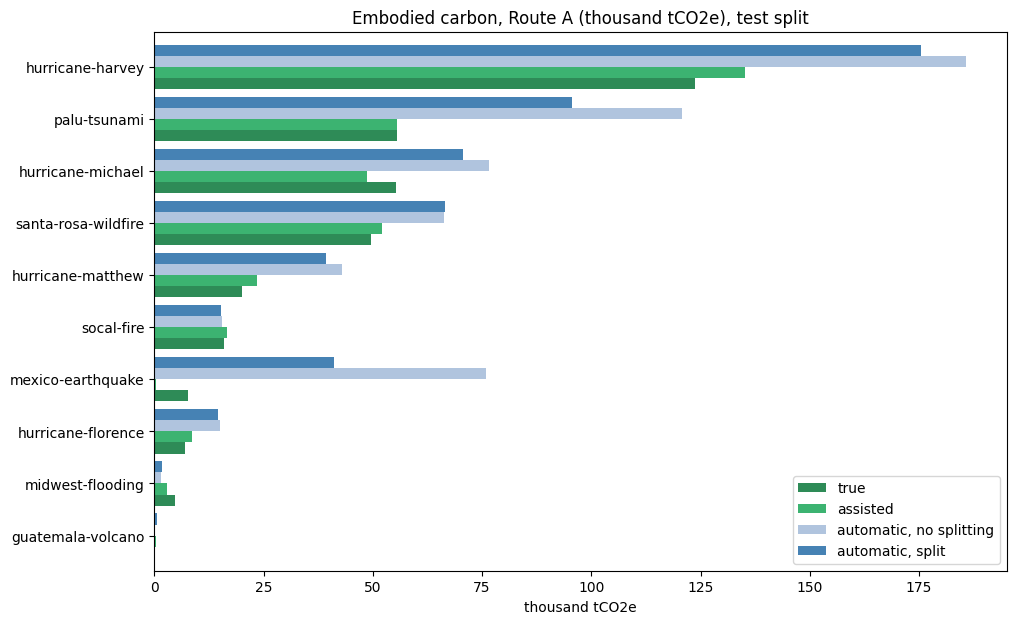

Carbon (Route A) as a multiple of the true-label figure; 1.00 = exact


,assisted,"automatic, no splitting","automatic, split","buildings found, split",buildings surveyed
disaster,,,,,
guatemala-volcano,3.59,1.91,5.88,62.0,30.0
hurricane-florence,1.24,2.14,2.07,2724.0,2117.0
hurricane-harvey,1.09,1.50,1.42,8791.0,7609.0
hurricane-matthew,1.18,2.14,1.96,2696.0,3971.0
hurricane-michael,0.88,1.39,1.28,7095.0,5602.0
mexico-earthquake,0.04,9.95,5.38,8164.0,11400.0
midwest-flooding,0.64,0.32,0.40,2774.0,2391.0
palu-tsunami,1.00,2.17,1.72,5896.0,12414.0
santa-rosa-wildfire,1.05,1.34,1.34,4683.0,4214.0


In [43]:
automatic = {}
for label, sep in [("automatic, no splitting", None), ("automatic, split", CHOSEN_SEPARATION)]:
    cache = OUTPUT_DIR / ("e2e_test_buildings.csv" if sep is None else f"e2e_test_buildings_split{sep}.csv")
    if cache.exists():
        automatic[label] = pd.read_csv(cache)
        continue
    rows = []
    for pre_path in sorted((TEST_DIR / "images").glob("*_pre_disaster.png")):
        tile = pre_path.stem.replace("_pre_disaster", "")
        before, after = xp.load_image(pre_path), xp.load_image(TEST_DIR / "images" / f"{tile}_post_disaster.png")
        b, _ = xp.find_buildings(finder, before, after, min_separation_px=sep)
        b["damage_class"] = xp.judge_damage(damage_model, before, after, b)
        if len(b):
            rows.append(b.assign(tile=tile, disaster=tile.split("_")[0]))
    automatic[label] = pd.concat(rows, ignore_index=True)
    automatic[label].to_csv(cache, index=False)

surveyed = test_labelled.merge(selected_preds[["file", "uid", "pred_class"]], on=["file", "uid"])
versions = {"true": totals(surveyed, "damage_class"), "assisted": totals(surveyed, "pred_class")}
versions.update({label: totals(table, "damage_class") for label, table in automatic.items()})
four = pd.concat(versions, axis=1)
four.loc["ALL TEST DISASTERS"] = four.sum()

fig, ax = plt.subplots(figsize=(11, 7))
four.xs("carbon A (kt)", axis=1, level=1).iloc[:-1].sort_values("true").plot(
    kind="barh", ax=ax, color=["seagreen", "mediumseagreen", "lightsteelblue", "steelblue"], width=0.85,
    title="Embodied carbon, Route A (thousand tCO2e), test split")
ax.set_xlabel("thousand tCO2e"); ax.set_ylabel(""); plt.show()

ratios = pd.DataFrame({label: four[(label, "carbon A (kt)")] / four[("true", "carbon A (kt)")]
                       for label in ["assisted", "automatic, no splitting", "automatic, split"]})
ratios["buildings found, split"] = four[("automatic, split", "buildings")]
ratios["buildings surveyed"] = four[("true", "buildings")]
print("Carbon (Route A) as a multiple of the true-label figure; 1.00 = exact")
ratios.round(2)

## 10. Final Evaluation on the Hold-out Set (run once)

The protocol is in Section 8. This section unpacks `hold/` the first time it runs, then measures the frozen pipeline on it. All results are cached in `outputs/` with names starting `hold_`, so re-running the notebook shows the same numbers without re-running the models.

hold/: 933 tiles, 53,137 buildings with a damage label, 10 disasters


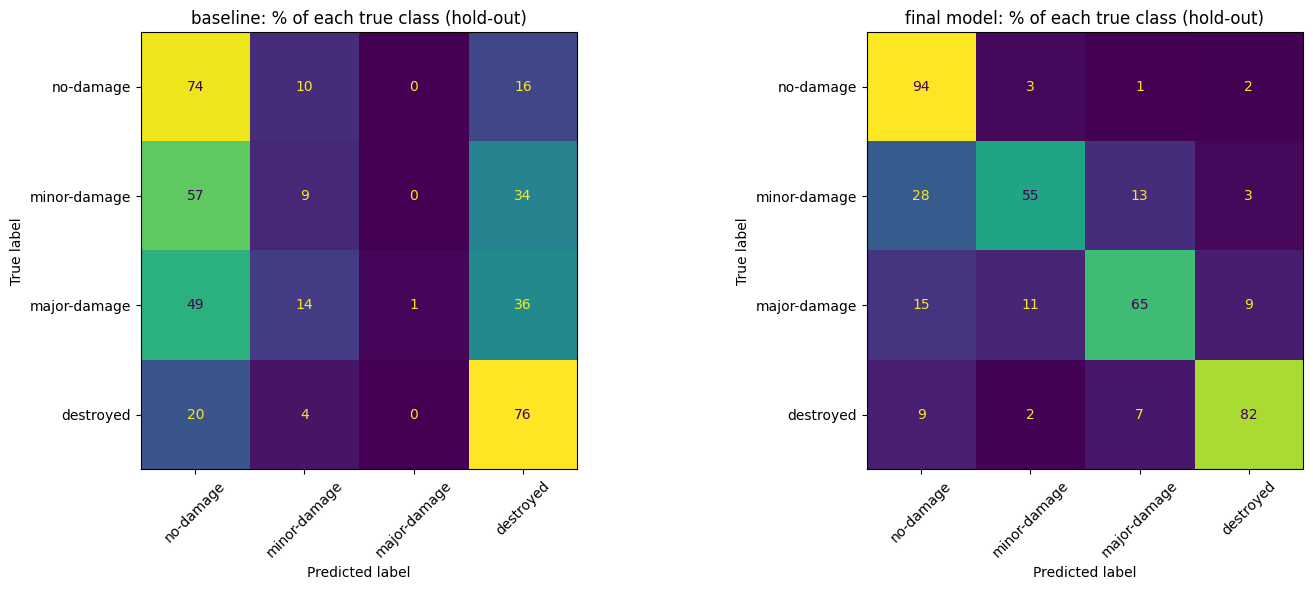

,"baseline (pretrained), hold-out","final model, test","final model, HOLD-OUT"
F1 no-damage,0.771,0.952,0.934
F1 minor-damage,0.099,0.592,0.603
F1 major-damage,0.028,0.685,0.655
F1 destroyed,0.369,0.803,0.780
macro F1,0.317,0.758,0.743
xView2 F1 (harmonic mean),0.080,0.735,0.722
accuracy,0.600,0.893,0.860
quadratic weighted kappa,0.347,0.827,0.802
mean class error,0.749,0.160,0.203
far errors (off by 2+ classes) %,21.783,3.798,4.488


In [44]:
import tarfile

HOLD_ARCHIVE = XBD_ROOT.parent / "archives" / "hold_images_labels_targets.tar"
if not (HOLD_DIR / "labels").exists():
    with tarfile.open(HOLD_ARCHIVE) as tar:
        members = [m for m in tar.getmembers() if m.name.startswith("hold/") and ".." not in m.name]
        tar.extractall(XBD_ROOT, members=members)

hold_buildings_df = build_metadata_table(HOLD_DIR / "labels")
hold_labelled = hold_buildings_df[hold_buildings_df["damage_class"].isin(DAMAGE_CLASSES)]
hold_post_labels = sorted((HOLD_DIR / "labels").glob("*_post_disaster.json"))
print(f"hold/: {len(hold_post_labels)} tiles, {len(hold_labelled):,} buildings with a damage label, "
      f"{hold_labelled['disaster'].nunique()} disasters")

# --- 1. damage on the surveyed outlines: final model and baseline ------------------
final_path = OUTPUT_DIR / "hold_final_damage_predictions.csv"
if final_path.exists():
    hold_final = pd.read_csv(final_path)
else:
    rows = []
    for label_path in hold_post_labels:
        _, features, _ = load_label(label_path)
        features = [f for f in features if f["properties"].get("subtype") in DAMAGE_CLASSES]
        if not features:
            continue
        file = label_path.stem
        before = xp.load_image(HOLD_DIR / "images" / f"{file.replace('_post_', '_pre_')}.png")
        after = xp.load_image(HOLD_DIR / "images" / f"{file}.png")
        boxes = pd.DataFrame([dict(zip(["x0", "y0", "x1", "y1"], wkt.loads(f["wkt"]).bounds)) for f in features])
        for f, pred in zip(features, xp.judge_damage(damage_model, before, after, boxes)):
            rows.append({"file": file, "uid": f["properties"]["uid"], "disaster": file.split("_")[0],
                         "true_class": f["properties"]["subtype"], "pred_class": pred})
    hold_final = pd.DataFrame(rows); hold_final.to_csv(final_path, index=False)

baseline_path = OUTPUT_DIR / "hold_baseline_damage_predictions.csv"
if baseline_path.exists():
    hold_baseline = pd.read_csv(baseline_path)
else:
    hold_baseline = predict_damage_for_tiles(baseline_classifier, hold_post_labels, baseline_preprocess)
    hold_baseline.to_csv(baseline_path, index=False)

hold_damage = pd.DataFrame({
    "baseline (pretrained), hold-out": damage_scores(hold_baseline["true_class"], hold_baseline["pred_class"]),
    "final model, test": results_table[selected_model_name],
    "final model, HOLD-OUT": damage_scores(hold_final["true_class"], hold_final["pred_class"]),
})
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, preds) in zip(axes, [("baseline", hold_baseline), ("final model", hold_final)]):
    cm_pct = confusion_matrix(preds["true_class"], preds["pred_class"], labels=DAMAGE_CLASSES, normalize="true") * 100
    ConfusionMatrixDisplay(cm_pct, display_labels=DAMAGE_CLASSES).plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".0f")
    ax.set_title(f"{name}: % of each true class (hold-out)")
plt.tight_layout(); plt.show()
hold_damage.round(3)

**Midpoint output 10b — finding buildings and the carbon/cost totals on the hold-out set.** The building finders are scored pixel by pixel against the surveyed outlines (as in Section 2b). The totals use the same four versions as Section 9d.

,tiles,precision,recall,IoU,F1
baseline U-Net,933,0.950,0.707,0.681,0.810
multi-task U-Net,933,0.798,0.841,0.693,0.819


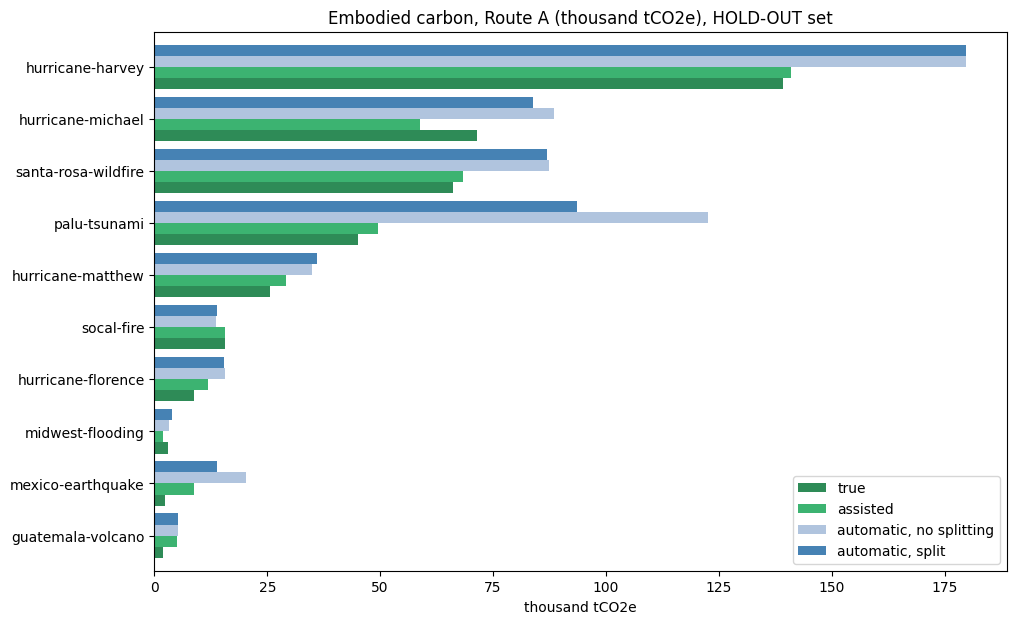

true                                          \
                       buildings needing work carbon A (kt) cost (USD m)   
disaster                                                                   
guatemala-volcano          101.0         35.0          1.91         4.43   
hurricane-florence        2491.0        390.0          8.72       126.32   
hurricane-harvey          7040.0       3993.0        139.25      1614.37   
hurricane-matthew         5504.0       4578.0         25.57        42.11   
hurricane-michael         7072.0       2615.0         71.33       762.78   
mexico-earthquake         7766.0         32.0          2.27         6.83   
midwest-flooding          2561.0        147.0          3.11        31.76   
palu-tsunami             11771.0       1357.0         45.05        74.62   
santa-rosa-wildfire       4758.0       1422.0         66.11      1354.10   
socal-fire                4073.0        597.0         15.72       321.90   
ALL HOLD-OUT DISASTERS   53137.0      15166.0        379.05      4339.21   

                        assisted                                          \
                       buildings needing work carbon A (kt) cost (USD m)   
disaster                                                                   
guatemala-volcano          101.0         41.0          5.00        11.56   
hurricane-florence        2491.0        432.0         11.91       172.60   
hurricane-harvey          7040.0       3597.0        141.04      1635.10   
hurricane-matthew         5504.0       4744.0         29.06        47.85   
hurricane-michael         7072.0       2192.0         58.82       628.94   
mexico-earthquake         7766.0         21.0          8.85        26.64   
midwest-flooding          2561.0         91.0          2.00        20.40   
palu-tsunami             11771.0       1498.0         49.46        81.92   
santa-rosa-wildfire       4758.0       1410.0         68.34      1399.74   
socal-fire                4073.0        532.0         15.60       319.56   
ALL HOLD-OUT DISASTERS   53137.0      14558.0        390.08      4344.31   

                       automatic, no splitting                             \
                                     buildings needing work carbon A (kt)   
disaster                                                                    
guatemala-volcano                         99.0         47.0          5.31   
hurricane-florence                      2430.0        428.0         15.62   
hurricane-harvey                        3826.0       1519.0        179.69   
hurricane-matthew                       2480.0       1923.0         34.82   
hurricane-michael                       6574.0       2139.0         88.50   
mexico-earthquake                       2504.0         82.0         20.28   
midwest-flooding                        2025.0         81.0          3.27   
palu-tsunami                            1923.0        357.0        122.53   
santa-rosa-wildfire                     3067.0        927.0         87.37   
socal-fire                              3337.0        306.0         13.75   
ALL HOLD-OUT DISASTERS                 28265.0       7809.0        571.14   

                                    automatic, split               \
                       cost (USD m)        buildings needing work   
disaster                                                            
guatemala-volcano             12.28            172.0         69.0   
hurricane-florence           226.23           3251.0        571.0   
hurricane-harvey            2083.22           8337.0       2906.0   
hurricane-matthew             57.33           3677.0       2754.0   
hurricane-michael            946.37           8862.0       2575.0   
mexico-earthquake             61.00           7110.0        138.0   
midwest-flooding              33.42           2804.0        137.0   
palu-tsunami                 202.95           5269.0        699.0   
santa-rosa-wildfire         1789.53           5031.0       1

HOLD-OUT: carbon (Route A) and cost as a multiple of the true-label figure; 1.00 = exact


,assisted,"automatic, no splitting","automatic, split","cost: automatic, split"
disaster,,,,
guatemala-volcano,2.61,2.77,2.77,2.77
hurricane-florence,1.37,1.79,1.78,1.78
hurricane-harvey,1.01,1.29,1.29,1.29
hurricane-matthew,1.14,1.36,1.41,1.41
hurricane-michael,0.82,1.24,1.18,1.18
mexico-earthquake,3.90,8.94,6.15,6.15
midwest-flooding,0.64,1.05,1.29,1.29
palu-tsunami,1.10,2.72,2.07,2.07
santa-rosa-wildfire,1.03,1.32,1.32,1.32


In [45]:
pixel_path = OUTPUT_DIR / "hold_building_maps.csv"
auto_paths = {"automatic, no splitting": OUTPUT_DIR / "hold_automatic_buildings.csv",
              f"automatic, split": OUTPUT_DIR / f"hold_automatic_buildings_split{CHOSEN_SEPARATION}.csv"}
if pixel_path.exists() and all(p.exists() for p in auto_paths.values()):
    hold_pixels = pd.read_csv(pixel_path)
    hold_auto = {k: pd.read_csv(p) for k, p in auto_paths.items()}
else:
    pixel_rows, auto_rows = [], {k: [] for k in auto_paths}
    for pre_path in sorted((HOLD_DIR / "images").glob("*_pre_disaster.png")):
        tile = pre_path.stem.replace("_pre_disaster", "")
        before, after = xp.load_image(pre_path), xp.load_image(HOLD_DIR / "images" / f"{tile}_post_disaster.png")
        true = load_true_mask(pre_path)
        unet = predict_building_mask(localization_model, np.array(Image.open(pre_path)))
        mask = xp.building_mask(finder, before, after)
        for model_name, pred in [("baseline U-Net", unet), ("multi-task U-Net", mask)]:
            pixel_rows.append({"tile": tile, "model": model_name, "tp": int((pred & true).sum()),
                               "fp": int((pred & ~true).sum()), "fn": int((~pred & true).sum())})
        for label, sep in [("automatic, no splitting", None), ("automatic, split", CHOSEN_SEPARATION)]:
            b, _ = xp.buildings_from_labels(xp.split_touching(mask, sep))
            b["damage_class"] = xp.judge_damage(damage_model, before, after, b)
            if len(b):
                auto_rows[label].append(b.assign(tile=tile, disaster=tile.split("_")[0]))
    hold_pixels = pd.DataFrame(pixel_rows); hold_pixels.to_csv(pixel_path, index=False)
    hold_auto = {k: pd.concat(v, ignore_index=True) for k, v in auto_rows.items()}
    for k, p in auto_paths.items():
        hold_auto[k].to_csv(p, index=False)

finder_scores = pd.DataFrame({m: localization_scores(g) for m, g in hold_pixels.groupby("model")}).T
display(finder_scores.astype({"tiles": int}).round(3))

hold_surveyed = hold_labelled.merge(hold_final[["file", "uid", "pred_class"]], on=["file", "uid"])
hold_versions = {"true": totals(hold_surveyed, "damage_class"), "assisted": totals(hold_surveyed, "pred_class")}
hold_versions.update({k: totals(v, "damage_class") for k, v in hold_auto.items()})
hold_four = pd.concat(hold_versions, axis=1)
hold_four.loc["ALL HOLD-OUT DISASTERS"] = hold_four.sum()

fig, ax = plt.subplots(figsize=(11, 7))
hold_four.xs("carbon A (kt)", axis=1, level=1).iloc[:-1].sort_values("true").plot(
    kind="barh", ax=ax, color=["seagreen", "mediumseagreen", "lightsteelblue", "steelblue"], width=0.85,
    title="Embodied carbon, Route A (thousand tCO2e), HOLD-OUT set")
ax.set_xlabel("thousand tCO2e"); ax.set_ylabel(""); plt.show()
display(hold_four.round(2))

hold_ratios = pd.DataFrame({label: hold_four[(label, measure)] / hold_four[("true", measure)]
                            for label in ["assisted", "automatic, no splitting", "automatic, split"]
                            for measure in ["carbon A (kt)"]})
hold_ratios["cost: automatic, split"] = hold_four[("automatic, split", "cost (USD m)")] / hold_four[("true", "cost (USD m)")]
print("HOLD-OUT: carbon (Route A) and cost as a multiple of the true-label figure; 1.00 = exact")
hold_ratios.round(2)

## Limitations & Assumptions (state these explicitly in your report)

1. **Construction type is a regional mix, not a per-building fact.** Layer 1 gives every building in a region the same GEM mix. There is no per-building ground truth for construction type in xBD, so this can only ever be validated at the regional level.
2. **Each disaster is matched to one GEM state/province**, although some span more than one, and GEM's figures describe the whole state, not the specific neighbourhoods that were hit. The disaster named `nepal-flooding` is matched to Uttar Pradesh, India, where its buildings actually are.
3. **Mapping GEM classes to RASMI's four structure types is an assumption**, most of all for GEM's "other" class (mobile homes, informal housing), which is treated as timber, and its "hybrid" class (India only), which is treated as masonry.
4. **RASMI values are medians from a published range** — the real data is a *range* per region/type, so a single value understates real-world variability. Several regions have few or no source buildings in RASMI and are filled in from wider regional pools.
5. **Rebuild percentages by damage class are assumed, not measured** — real reconstruction need depends on repairability, local building codes and insurance assessments.
6. **Floor area is uncertain, so two methods are reported side by side** (Section 7c): measured footprint × GEM's regional average storeys, and GEM's regional average building size. They differ by about 40%. Individual building heights are not observed.
7. **Carbon is embodied material carbon only.** It excludes transport, site energy, demolition and waste. Copper is excluded because ICE V5.0 withdrew its copper values.
8. **Cost is GEM's regional building replacement cost per m²**, including labour and excluding contents. It is not a quote for any individual building.
9. **The Stage 1/Stage 2 models are the only "black box" components** — everything from Section 4 onward is a transparent, auditable calculation, which is a deliberate design choice for decision-support use.

## Decisions log

Choices made by the project author, with the date, so a reader can see what was decided and what is still open.

| Date | Decision | Status |
|---|---|---|
| 2026-10-08 | Embodied carbon factors come from ICE Educational V5.0 (not v4.1) | Decided |
| 2026-10-08 | USGS commodity prices dropped; cost is GEM building replacement cost (includes labour, excludes contents) | Decided |
| 2026-10-08 | Construction type: GEM regional mix (Layer 1), later adjusted per building by a CNN (Layer 2) | Decided |
| 2026-10-08 | Carbon is calculated by both routes (RASMI × ICE, and GEM) and compared | Decided |
| 2026-10-08 | RASMI central value is the median (50th percentile); 25th/75th used for sensitivity | Decided |
| 2026-10-08 | Copper excluded (no ICE V5.0 factor) | Decided |
| 2026-10-08 | RASMI regions: Guatemala and Haiti = LAM_LAM-L, Nepal = ASIA_OAS-L | Accepted |
| 2026-10-08 | Disaster → GEM region table | Accepted; all 19 rows checked against building coordinates |
| 2026-10-08 | Floor area: both methods run and reported side by side | No single headline chosen yet |
| 2026-10-08 | Timber carbon factor: ICE's average for timber *excluding* carbon stored in the wood; the including-storage factor kept as a sensitivity case | Decided |
| 2026-10-08 | `nepal-flooding` uses India's figures (GEM: Uttar Pradesh; RASMI: ASIA_IND), because its building coordinates (about 26.6°N, 83.4°E) fall in India, not Nepal | Decided |
| — | Rebuild percentages by damage class (0 / 15 / 60 / 100%) | Assumed; no cited source yet |
